In [2]:
import os
import pandas as pd

dir_path = '.'
# Filter to ensure we only grab the prediction files
file_list = [f for f in os.listdir(dir_path) if f.endswith('.csv') and '_shot' in f]

def sort_key(filename):
    # Split "ProteinName_final_predictions_shot16.csv"
    base_name = filename.split('_final_predictions_shot')[0]
    k_val = int(filename.split('_shot')[-1].split('.csv')[0])
    return (base_name, k_val)

file_list.sort(key=sort_key)

def top_n_fitness(df, pred_col, target_col='target', n=10):
    """Sorts by prediction and returns the mean actual target of the top n items."""
    if pred_col not in df.columns or df[pred_col].isna().all():
        return float('-inf')
    top_n = df.sort_values(by=pred_col, ascending=False).head(n)
    return top_n[target_col].mean()

# Dictionary to hold stratified counts
stratified_counts = {}

for file in file_list:
    # Extract K value for stratification
    k_val = int(file.split('_shot')[-1].split('.csv')[0])
    
    # Initialize dictionary for this K value if not present
    if k_val not in stratified_counts:
        stratified_counts[k_val] = {'smite': 0, 'evolve': 0, 'zeroshot': 0, 'combined': 0, 'tie': 0}
        
    df = pd.read_csv(os.path.join(dir_path, file))
    
    if 'pred_epro' in df.columns and 'pred_my_method' in df.columns:
        min_e, max_e = df['pred_epro'].min(), df['pred_epro'].max()
        min_s, max_s = df['pred_my_method'].min(), df['pred_my_method'].max()
        mm_epro = (df['pred_epro'] - min_e) / (max_e - min_e + 1e-8)
        mm_smite = (df['pred_my_method'] - min_s) / (max_s - min_s + 1e-8)
        df['combined_score'] = (mm_smite + mm_epro) / 2

    # Calculate top 10 mean fitness for each method
    top10_zeroshot = top_n_fitness(df, 'delta_esm', 'target', n=10)
    top10_my = top_n_fitness(df, 'pred_my_method', 'target', n=10)
    top10_epr = top_n_fitness(df, 'pred_epro', 'target', n=10)
    top10_combined = top_n_fitness(df, 'combined_score', 'target', n=10)

    # Evaluate conditions
    if top10_my > top10_epr and top10_my > top10_zeroshot and top10_my > top10_combined:
        stratified_counts[k_val]['smite'] += 1
    elif top10_epr > top10_my and top10_epr > top10_zeroshot and top10_epr > top10_combined:
        stratified_counts[k_val]['evolve'] += 1
    elif top10_zeroshot > top10_my and top10_zeroshot > top10_epr and top10_zeroshot > top10_combined:
        stratified_counts[k_val]['zeroshot'] += 1
    elif top10_combined > top10_my and top10_combined > top10_epr and top10_combined > top10_zeroshot:
        stratified_counts[k_val]['combined'] += 1  # Count combined as an EVOLVEpro win
    else:
        stratified_counts[k_val]['tie'] += 1

print("\nSummary Stratified by K-shot (Metric: Top 10 Mean Fitness):")
print(f"{'K-Shot':<8} | {'SMITEpro Wins':<15} | {'EVOLVEpro Wins':<15} | {'Zero-Shot Wins':<15} | {'Combined Wins':<15} | {'Ties':<5}")
print("-" * 75)

# Print sorted by K value
for k in sorted(stratified_counts.keys()):
    counts = stratified_counts[k]
    print(f"{k:<8} | {counts['smite']:<15} | {counts['evolve']:<15} | {counts['zeroshot']:<15} | {counts['combined']:<15} | {counts['tie']:<5}")

# Global summary
total_smite = sum(c['smite'] for c in stratified_counts.values())
total_evolve = sum(c['evolve'] for c in stratified_counts.values())
total_zeroshot = sum(c['zeroshot'] for c in stratified_counts.values())
total_combined = sum(c['combined'] for c in stratified_counts.values())
total_ties = sum(c['tie'] for c in stratified_counts.values())
print("-" * 75)
print(f"{'Total':<8} | {total_smite:<15} | {total_evolve:<15} | {total_zeroshot:<15} | {total_combined:<15} | {total_ties:<5}")


Summary Stratified by K-shot (Metric: Top 10 Mean Fitness):
K-Shot   | SMITEpro Wins   | EVOLVEpro Wins  | Zero-Shot Wins  | Combined Wins   | Ties 
---------------------------------------------------------------------------
4        | 54              | 26              | 71              | 60              | 2    
8        | 63              | 48              | 56              | 44              | 2    
16       | 39              | 38              | 53              | 80              | 3    
32       | 53              | 43              | 43              | 70              | 4    
64       | 34              | 63              | 28              | 81              | 4    
128      | 32              | 60              | 28              | 84              | 4    
---------------------------------------------------------------------------
Total    | 275             | 278             | 279             | 419             | 19   


In [3]:
import os
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

dir_path = '.'
n_values = [10, 20, 30, 40]
records = []

for file in os.listdir(dir_path):
    if not file.endswith('.csv'):
        continue
        
    df = pd.read_csv(os.path.join(dir_path, file))
    
    if 'mutated_sequence' not in df.columns or 'mutant' not in df.columns:
        print(f"Skipping {file} due to missing required columns.")
        continue

    # Calculate num_sites
    unique_sites = set()
    for pos in df['mutant']:
        positions = pos.split(':')
        for position in positions:
            unique_sites.add(position[1:-1])
    num_sites = len(unique_sites)

    system_name = file.replace('.csv', '')
    train_size = int(file.split('_shot')[1].split('.csv')[0])
    
    # Global Ground Truth Definitions
    threshold_1pct = df['target'].quantile(0.99)
    true_top_1pct_indices = set(df[df['target'] >= threshold_1pct].index)
    background_hit_rate = len(true_top_1pct_indices) / len(df)
    if background_hit_rate == 0: background_hit_rate = 1e-8
    
    true_top_10_df = df.nlargest(10, 'target', keep='all')
    true_top_10_indices = set(true_top_10_df.index)
    
    min_target = df['target'].min()
    g_max = df['target'].max()
    g_median = df['target'].median()
    g_range = g_max - g_median if g_max > g_median else 1e-8

    # Ensemble Score
    if 'pred_epro' in df.columns and 'pred_my_method' in df.columns:
        min_e, max_e = df['pred_epro'].min(), df['pred_epro'].max()
        min_s, max_s = df['pred_my_method'].min(), df['pred_my_method'].max()
        mm_epro = (df['pred_epro'] - min_e) / (max_e - min_e + 1e-8)
        mm_smite = (df['pred_my_method'] - min_s) / (max_s - min_s + 1e-8)
        df['combined_score'] = (mm_smite + mm_epro) / 2

    # Filter Training Data
    if 'is_train' in df.columns:
        eval_df = df[~df['is_train']].copy()
    else:
        eval_df = df.copy()

    def calc_metrics(eval_df, pred_col, method_name, train_size, global_df, num_sites_val):
        results = []
        
        for n in n_values:
            pred_top_n = eval_df.nlargest(n, pred_col)
            pred_indices = set(pred_top_n.index)
            
            actual_n = len(pred_top_n)
            if actual_n == 0:
                continue
            
            # 1. Enrichment Factor & 2. Top 1% Precision
            prec_hits_1pct = len(pred_indices.intersection(true_top_1pct_indices))
            model_hit_rate = prec_hits_1pct / actual_n
            enrichment = model_hit_rate / background_hit_rate
            top_1_prec = model_hit_rate
            
            # 3. Mean Top-N Fitness
            mean_fitness = pred_top_n['target'].mean()
            
            # 4. NDCG@N
            relevances = pred_top_n['target'].values
            shifted_rels = relevances - min_target
            k = len(shifted_rels)
            dcg = np.sum(shifted_rels / np.log2(np.arange(2, k + 2)))
            
            ideal_top_n = eval_df.nlargest(n, 'target')['target'].values
            ideal_shifted_rels = ideal_top_n - min_target
            ideal_k = len(ideal_shifted_rels)
            idcg = np.sum(ideal_shifted_rels / np.log2(np.arange(2, ideal_k + 2)))
            ndcg = dcg / idcg if idcg > 0 else 0
            
            # 5. Top 10 Recall
            hr_hits = len(pred_indices.intersection(true_top_10_indices))
            top_10_recall = hr_hits / len(true_top_10_indices) if len(true_top_10_indices) > 0 else 0
            
            # 6. Normalized Max Score
            max_val_in_n = pred_top_n['target'].max()
            norm_max_score = max(0, (max_val_in_n - g_median) / g_range)
            
            # Base dictionary containing identifying info + num_sites
            base_dict = {
                'system': system_name, 'train_size': train_size, 'method': method_name, 
                'N': n, 'num_sites': num_sites_val
            }
            
            # Map of metric names to calculated values
            metrics_map = {
                'Enrichment Factor': enrichment,
                'Mean Top-N Fitness': mean_fitness,
                'NDCG': ndcg,
                'Top 1% Precision': top_1_prec,
                'Top 10 Recall': top_10_recall,
                'Normalized Max Score': norm_max_score
            }
            
            # Append each metric as its own row
            for m_name, m_val in metrics_map.items():
                res = base_dict.copy()
                res['metric'] = m_name
                res['value'] = m_val
                results.append(res)
            
        return results

    if 'pred_my_method' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_my_method', 'SMITEpro', train_size, df, num_sites))
    if 'pred_epro' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_epro', 'EVOLVEpro', train_size, df, num_sites))
    if 'combined_score' in df.columns:
        records.extend(calc_metrics(eval_df, 'combined_score', 'Ensemble', train_size, df, num_sites))
    if 'delta_esm' in df.columns and file.endswith('shot32.csv'):
        records.extend(calc_metrics(eval_df, 'delta_esm', 'Zero-Shot ESM', 0, df, num_sites))

metrics_df = pd.DataFrame(records)
print(f"Final dataset: {len(metrics_df)} entries across {metrics_df['system'].nunique()} systems.")
metrics_df.to_csv('evaluation_metrics_combined.csv', index=False)

Skipping top_1pct_precision_ensemble_by_panel.csv due to missing required columns.
Skipping evaluation_metrics.csv due to missing required columns.
Skipping hpab_subgroups_K128_N20_per_assay_win_tie_loss.csv due to missing required columns.
Skipping hpab_subgroups_K128_N20_mean_heatmap_values.csv due to missing required columns.
Skipping hpab_subgroups_raw_scores.csv due to missing required columns.
Skipping hpab_subgroups_K128_N20_ensemble_win_tie_loss.csv due to missing required columns.
Skipping top_1pct_precision_leaderboard.csv due to missing required columns.
Skipping hpab_subgroups_K128_N20_raw_scores.csv due to missing required columns.
Skipping evaluation_metrics_combined.csv due to missing required columns.
Skipping benchmark_bubble_matrix_means.csv due to missing required columns.
Skipping hpab_subgroups_per_assay_win_tie_loss.csv due to missing required columns.
Skipping mean_top_n_leaderboard.csv due to missing required columns.
Skipping top_1pct_precision_ensemble_head_to

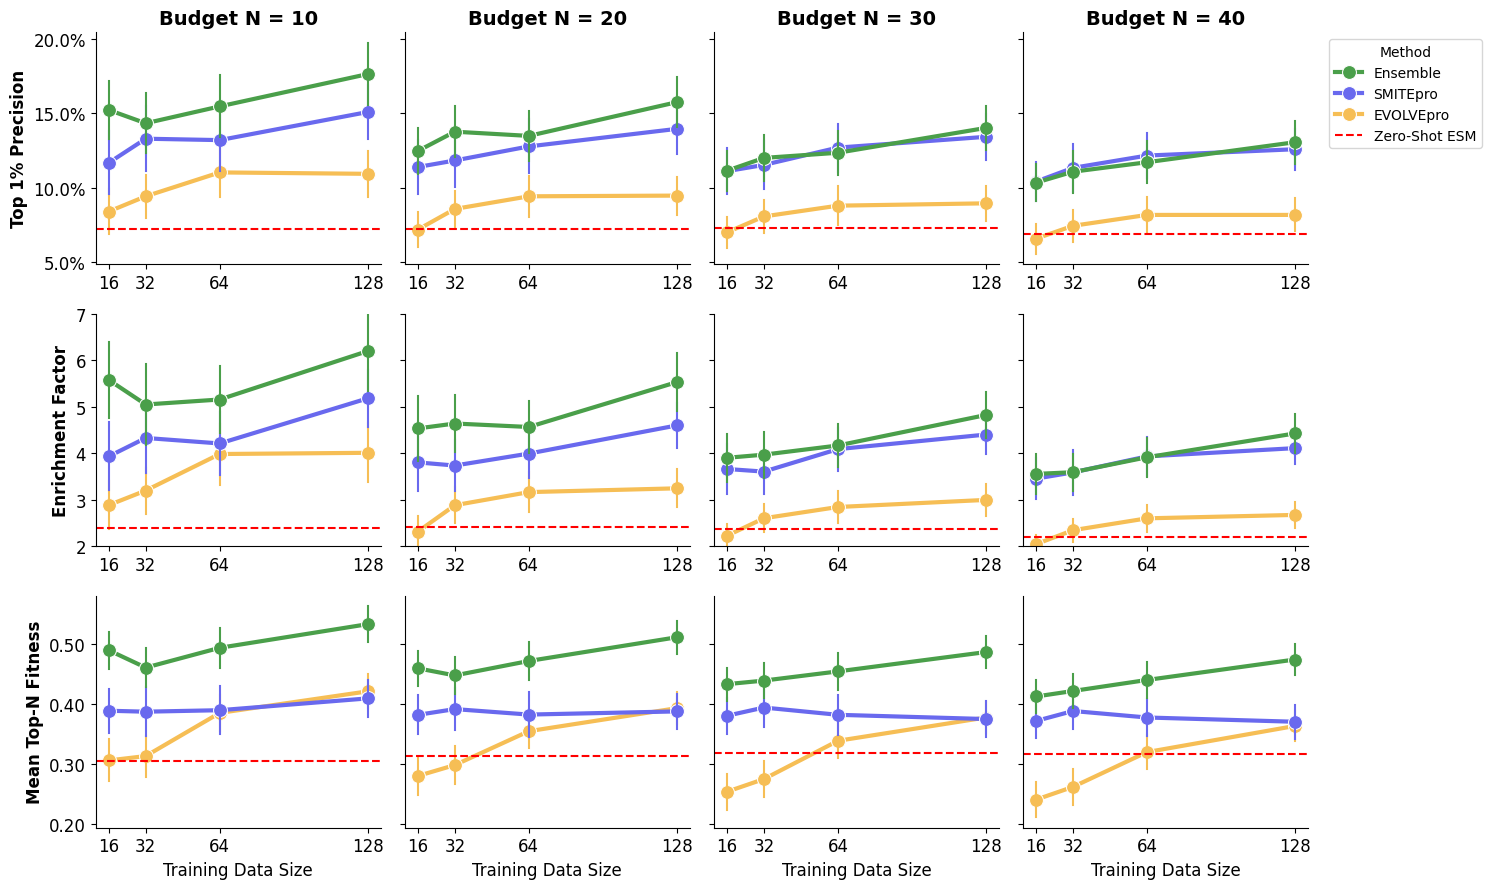

In [4]:
import matplotlib.ticker as mtick
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

metrics_df = pd.read_csv('evaluation_metrics_combined.csv')

# Set your filter threshold here
min_num_sites = 100 # change to 100 for less overlap

# Apply the filter before splitting the data
plot_metrics_df = metrics_df[metrics_df['num_sites'] >= min_num_sites].copy()

baseline_metrics_df = plot_metrics_df[plot_metrics_df['method'] == 'Zero-Shot ESM']
model_metrics_df = plot_metrics_df[plot_metrics_df['method'] != 'Zero-Shot ESM']

baseline_metrics_df['method'] = baseline_metrics_df['method'].replace('Combined', 'Ensemble')
model_metrics_df['method'] = model_metrics_df['method'].replace('Combined', 'Ensemble')

metrics_to_plot = [
    'Top 1% Precision', 
    # 'Top 10 Recall', 
    # 'Normalized Max Score',
    'Enrichment Factor',
    'Mean Top-N Fitness',
    # 'NDCG'
]
budgets_to_plot = [10, 20, 30, 40]

method_order = ['EVOLVEpro', 'SMITEpro', 'Ensemble']

custom_colors = {
    'EVOLVEpro': "#F6BE55",
    'SMITEpro': "#6969EE",
    'Ensemble': "#4A9F4A"
}

plot_height = 3*len(metrics_to_plot)

fig, axes = plt.subplots(len(metrics_to_plot), len(budgets_to_plot), figsize=(15, plot_height), sharey='row')

for i, metric in enumerate(metrics_to_plot):
    for j, n in enumerate(budgets_to_plot):
        ax = axes[i, j]
        
        data_subset = model_metrics_df[
            (model_metrics_df['metric'] == metric) & 
            (model_metrics_df['N'] == n)
        ]
        
        if data_subset.empty:
            continue
        
        data_subset = data_subset[~data_subset['train_size'].isin([4, 8])]

        sns.lineplot(
            data=data_subset,
            x="train_size",
            y="value",
            hue="method",
            hue_order=method_order, 
            palette=custom_colors, 
            errorbar="se",
            marker="o",
            err_style="bars",
            linewidth=3,
            markersize=10,
            ax=ax
        )
        
        zs_subset = baseline_metrics_df[
            (baseline_metrics_df['metric'] == metric) & 
            (baseline_metrics_df['N'] == n)
        ]
        if not zs_subset.empty:
            zs_val = zs_subset['value'].mean()
            if not pd.isna(zs_val):
                ax.axhline(y=zs_val, color='red', linestyle='--', linewidth=1.5, label='Zero-Shot ESM')
        
        if j == 0:
            ax.set_ylabel(metric, fontsize=12, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        if i == 0:
            ax.set_title(f"Budget N = {n}", fontsize=14, fontweight='bold')

        ax.set_xticks([16, 32, 64, 128])
        ax.tick_params(axis='both', which='major', labelsize=12)
        
        sns.despine(ax=ax)
        
        if i == len(metrics_to_plot) - 1:
            ax.set_xlabel("Training Data Size", fontsize=12)
        else:
            ax.set_xlabel("")

        if i == 0 and j == len(budgets_to_plot) - 1:
            # Reorder legend
            handles, labels = ax.get_legend_handles_labels()
            desired_order = ['Ensemble', 'SMITEpro', 'EVOLVEpro', 'Zero-Shot ESM']
            
            # Create a dictionary to map labels to their corresponding handles
            hl_dict = dict(zip(labels, handles))
            
            # Extract handles and labels in the desired order
            new_handles = [hl_dict[l] for l in desired_order if l in hl_dict]
            new_labels = [l for l in desired_order if l in hl_dict]
            
            ax.legend(new_handles, new_labels, title="Method", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            if ax.get_legend() is not None:
                ax.get_legend().remove()

    # Apply specific y-axis formatting per row
    if metric == 'Enrichment Factor':
        # axes[i, 0].set_yscale('log')
        axes[i, 0].set_ylim(2, 7)
        axes[i, 0].set_yticks([2, 3, 4, 5, 6, 7])
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
        axes[i, 0].yaxis.set_minor_formatter(mtick.NullFormatter())
    elif metric in ['Top 1% Precision', 'Top 10 Recall']:
        axes[i, 0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    elif metric == 'Mean Top-N Fitness':
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
    elif metric == 'NDCG':
        axes[i, 0].set_ylim(0, 1)
    elif metric == 'Normalized Max Score':
        axes[i, 0].set_ylim(0.7, 1)

plt.tight_layout()
plt.show()

In [5]:
import os
import pandas as pd

dir_path = '.'
records = []

for file in os.listdir(dir_path):
    if not file.endswith('.csv'):
        continue
        
    df = pd.read_csv(os.path.join(dir_path, file))

    # Extract metadata
    system_name = file.replace('.csv', '')
    train_size = int(file.split('_shot')[1].split('.csv')[0])
    ds_length = len(df)
    prot_length = len(df['mutated_sequence'][0])
    
    # Calculate unique mutated sites
    unique_sites = set()
    for pos in df['mutant']:
        positions = pos.split(':')
        for position in positions:
            unique_sites.add(position[1:-1])
    num_sites = len(unique_sites)
    

    # Base dictionary for shared row data
    base_record = {
        'system': system_name,
        'train_size': train_size,
        'dataset_length': ds_length,
        'protein_length': prot_length,
        'num_mutated_sites': num_sites
    }
    # Calculate correlations
    if 'pred_my_method' in df.columns:
        smite_rho = df[['pred_my_method', 'target']].corr(method='spearman').iloc[0, 1]
    else:
        smite_rho = float('nan')

    if 'pred_epro' in df.columns:
        evolve_rho = df[['pred_epro', 'target']].corr(method='spearman').iloc[0, 1]
    else:
        evolve_rho = float('nan')

    if 'pred_epro' in df.columns and 'pred_my_method' in df.columns:
        # take the min-max avg of the two methods as a combined score for correlation
        min_max_avg = (df['pred_my_method'].rank(pct=True) + df['pred_epro'].rank(pct=True)) / 2
        combined_score = (df['pred_my_method'] + df['pred_epro']) / 2
        df['combined_score'] = combined_score
        combined_rho = df[['combined_score', 'target']].corr(method='spearman').iloc[0, 1]
        records.append({**base_record, 'method': 'Combined', 'rho': combined_rho})


    
    # Append individual rows for each method
    if not pd.isna(smite_rho):
        records.append({**base_record, 'method': 'SMITEpro', 'rho': smite_rho})
    if not pd.isna(evolve_rho):
        records.append({**base_record, 'method': 'EVOLVEpro', 'rho': evolve_rho})
    
    # Capture zero-shot baseline once per system using shot32 as the anchor (or whatever is the lowest available)
    # We use shot32 here because shot4 files are not present in this directory
    if file.endswith('shot64.csv'):
        if 'delta_esm' in df.columns:
            zero_shot_rho = df[['delta_esm', 'target']].corr(method='spearman').iloc[0, 1]
            records.append({
                **base_record, 
                'method': 'Zero-Shot ESM', 
                'train_size': 0, 
                'rho': zero_shot_rho
            })

# Create the final long DataFrame
long_df = pd.DataFrame(records)

# Remove rows where rho calculation resulted in NaN
long_df = long_df.dropna(subset=['rho']).reset_index(drop=True)

# Print summary
print(f"Total valid datasets: {len(long_df)}")
if len(long_df) > 0:
    print("\nAverage Rho by Method and Train Size:")
    print(long_df.groupby(['method', 'train_size'])['rho'].mean().reset_index())
    
    # Check if we have Zero-Shot data
    zs_count = len(long_df[long_df['method'] == 'Zero-Shot ESM'])
    print(f"\nZero-Shot ESM records: {zs_count}")
else:
    print("No valid records found.")

IndexError: list index out of range

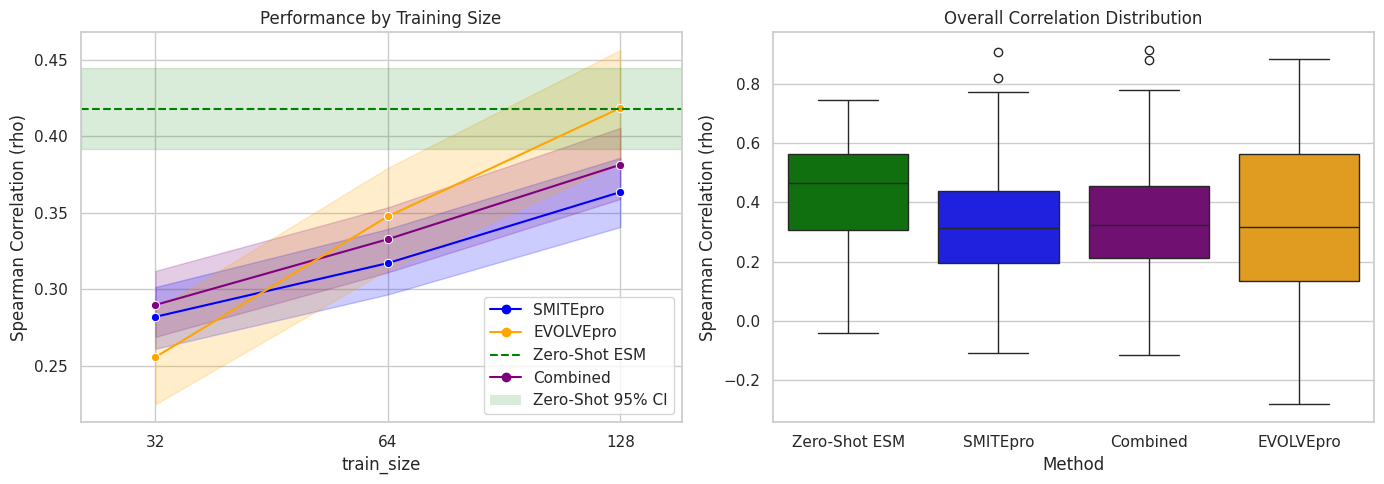

In [ ]:
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set visual style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Filter out Zero-Shot for the main line plot data points
# This allows plotting train_size vs rho on log scale
plot_df = long_df[long_df['method'] != 'Zero-Shot ESM']

# Calculate Zero-Shot statistics for the baseline
zero_shot_df = long_df[long_df['method'] == 'Zero-Shot ESM']
zs_mean = zero_shot_df['rho'].mean()
# Use standard error for CI (mean +/- 1.96 * SE)
zs_se = zero_shot_df['rho'].std() / np.sqrt(len(zero_shot_df))
zs_ci = 1.96 * zs_se

# Plot 1: Average Spearman Correlation vs. Train Size
sns.lineplot(
    data=plot_df, 
    x="train_size", 
    y="rho", 
    hue="method", 
    palette={"SMITEpro": "blue", "EVOLVEpro": "orange", "Zero-Shot ESM": "green", "Combined": "purple"},
    marker="o",
    errorbar=("ci", 95),
    ax=axes[0]
)

# Add Zero-Shot baseline as a horizontal line with error band using axhspan
# Note: axhspan covers the entire x-axis width
axes[0].axhline(y=zs_mean, color='green', linestyle='--', label='Zero-Shot ESM Mean')
axes[0].axhspan(ymin=zs_mean - zs_ci, ymax=zs_mean + zs_ci, color='green', alpha=0.15, label='Zero-Shot ESM 95% CI')

unique_train_sizes = sorted(plot_df['train_size'].unique())

axes[0].set_xscale('log', base=2)
if unique_train_sizes:
    axes[0].set_xticks(unique_train_sizes)
    axes[0].get_xaxis().set_major_formatter(ticker.ScalarFormatter())
    # Add some padding to the x-axis limits
    axes[0].set_xlim(min(unique_train_sizes) * 0.8, max(unique_train_sizes) * 1.2)

axes[0].set_title("Performance by Training Size")
axes[0].set_ylabel("Spearman Correlation (rho)")

# Manually update legend to include Zero-Shot lines
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
custom_lines = [
    Line2D([0], [0], color='blue', marker='o', label='SMITEpro'),
    Line2D([0], [0], color='orange', marker='o', label='EVOLVEpro'),
    Line2D([0], [0], color='green', linestyle='--', label='Zero-Shot ESM'),
    Line2D([0], [0], color='purple', marker='o', label='Combined'),
    Patch(facecolor='green', edgecolor='none', alpha=0.15, label='Zero-Shot 95% CI')
]
axes[0].legend(handles=custom_lines, loc='lower right')


# Plot 2: Distribution of Correlations by Method
# Include Zero-Shot in the boxplot explicitly
sns.boxplot(
    data=long_df,
    x="method",
    y="rho", 
    # Use hue to map methods to colors
    hue="method",
    palette={"Zero-Shot ESM": "green", "SMITEpro": "blue", "EVOLVEpro": "orange", "Combined": "purple"},
    order=[
        'Zero-Shot ESM', 
        'SMITEpro', 
        'Combined',
        'EVOLVEpro', 
        ],
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Overall Correlation Distribution")
axes[1].set_xlabel("Method")
axes[1].set_ylabel("Spearman Correlation (rho)")

plt.tight_layout()
plt.show()

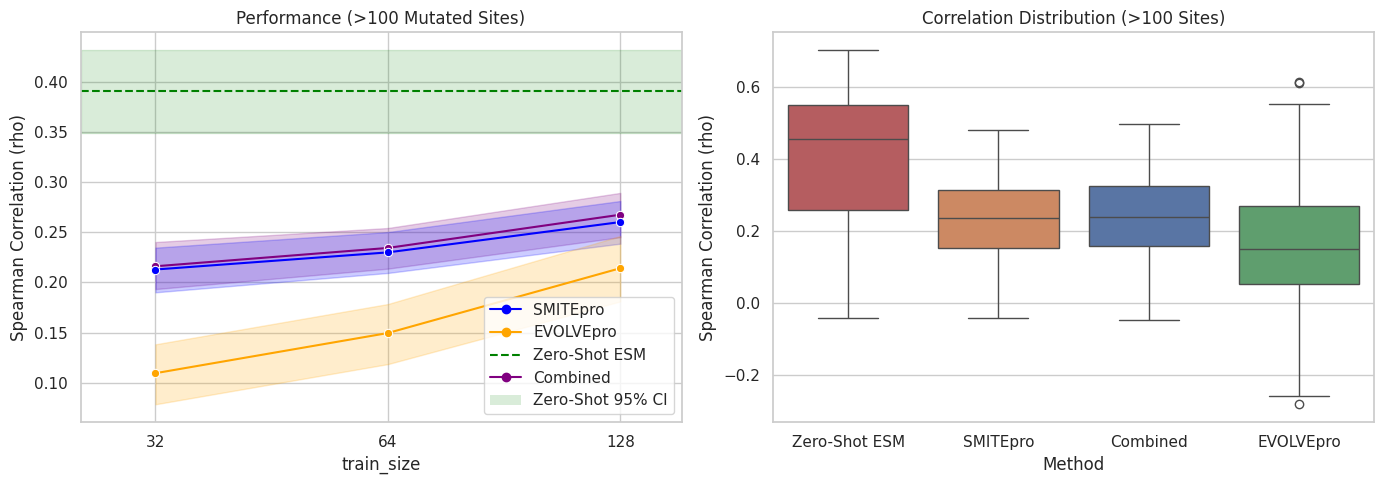

In [ ]:
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

long_df_filtered = long_df[long_df['num_mutated_sites'] > 100]  # Exclude zero-shot for the first plot
# long_df_short = long_df[long_df['num_mutated_sites'] <= 100]  # Focus on zero-shot and few-shot for the second plot

# Set visual style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Average Spearman Correlation vs. Train Size ---
# Filter out Zero-Shot for the main line plot data points
plot_df_filtered = long_df_filtered[long_df_filtered['method'] != 'Zero-Shot ESM']

# Calculate Zero-Shot statistics for the baseline from filtered data
zs_df_filtered = long_df_filtered[long_df_filtered['method'] == 'Zero-Shot ESM']
if not zs_df_filtered.empty:
    zs_mean = zs_df_filtered['rho'].mean()
    zs_se = zs_df_filtered['rho'].std() / np.sqrt(len(zs_df_filtered))
    zs_ci = 1.96 * zs_se
else:
    zs_mean = 0
    zs_ci = 0

sns.lineplot(
    data=plot_df_filtered, 
    x="train_size", 
    y="rho", 
    hue="method",
    palette={"SMITEpro": "blue", "EVOLVEpro": "orange", "Combined": "purple"},
    marker="o",
    errorbar=("ci", 95),
    ax=axes[0]
)

# Add Zero-Shot baseline
if not zs_df_filtered.empty:
    axes[0].axhline(y=zs_mean, color='green', linestyle='--', label='Zero-Shot ESM Mean')
    axes[0].axhspan(ymin=zs_mean - zs_ci, ymax=zs_mean + zs_ci, color='green', alpha=0.15, label='Zero-Shot ESM 95% CI')

# Fix Plot 1 axes
unique_train_sizes = sorted(plot_df_filtered['train_size'].unique())

axes[0].set_xscale('log', base=2)
if unique_train_sizes:
    axes[0].set_xticks(unique_train_sizes)
    axes[0].xaxis.set_major_formatter(ticker.ScalarFormatter())
    axes[0].set_xlim(min(unique_train_sizes) * 0.8, max(unique_train_sizes) * 1.2)
axes[0].set_title("Performance (>100 Mutated Sites)")
axes[0].set_ylabel("Spearman Correlation (rho)")

# Update Legend
custom_lines = [
    Line2D([0], [0], color='blue', marker='o', label='SMITEpro'),
    Line2D([0], [0], color='orange', marker='o', label='EVOLVEpro'),
    Line2D([0], [0], color='green', linestyle='--', label='Zero-Shot ESM'),
    Line2D([0], [0], color='purple', marker='o', label='Combined'),
    Patch(facecolor='green', edgecolor='none', alpha=0.15, label='Zero-Shot 95% CI')
]
axes[0].legend(handles=custom_lines, loc='lower right')

# --- Plot 2: Distribution of Correlations by Method ---
sns.boxplot(
    data=long_df_filtered,
    x="method",
    y="rho",
    # make the box plots split into methods with different colors
    hue="method",
    # palette={"Zero-Shot ESM": "green", "SMITEpro": "blue", "EVOLVEpro": "orange"},
    order=['Zero-Shot ESM', 'SMITEpro', 'Combined', 'EVOLVEpro'],
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Correlation Distribution (>100 Sites)")
axes[1].set_xlabel("Method")
axes[1].set_ylabel("Spearman Correlation (rho)")

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

dir_path = '.'
n_values = [10, 20, 30, 40]

records = []

for file in os.listdir(dir_path):
    if not file.endswith('.csv'):
        continue
        
    df = pd.read_csv(os.path.join(dir_path, file))
    
    if 'mutated_sequence' not in df.columns or 'mutant' not in df.columns:
        print(f"Skipping {file} due to missing required columns.")
        continue

    protein_length = len(df['mutated_sequence'][0])
    unique_sites = set()
    for pos in df['mutant']:
        positions = pos.split(':')
        for position in positions:
            unique_sites.add(position[1:-1])
    num_sites = len(unique_sites)

    # if num_sites < 100:
    #     continue

    system_name = file.replace('.csv', '')
    train_size = int(file.split('_shot')[1].split('.csv')[0])
    
    # 1. Ground Truth Definitions
    threshold_1pct = df['target'].quantile(0.99)
    true_top_1pct_indices = set(df[df['target'] >= threshold_1pct].index)
    
    true_top_10_df = df.nlargest(10, 'target', keep='all')
    true_top_10_indices = set(true_top_10_df.index)
    
    # Calculate combined score on the full dataframe first if both exist
    if 'pred_epro' in df.columns and 'pred_my_method' in df.columns:
        min_e, max_e = df['pred_epro'].min(), df['pred_epro'].max()
        min_s, max_s = df['pred_my_method'].min(), df['pred_my_method'].max()
        mm_epro = (df['pred_epro'] - min_e) / (max_e - min_e + 1e-8)
        mm_smite = (df['pred_my_method'] - min_s) / (max_s - min_s + 1e-8)
        df['combined_score'] = (mm_smite + mm_epro) / 2

    # 2. Filter out the training data
    if 'is_train' in df.columns:
        eval_df = df[~df['is_train']].copy()
    else:
        # Note: If you do not have this column, all variants are evaluated
        eval_df = df.copy()

    def calc_metrics(eval_df, pred_col, method_name, train_size, global_df):
        results = []
        
        g_max = global_df['target'].max()
        g_median = global_df['target'].median()
        g_range = g_max - g_median if g_max > g_median else 1e-8

        for n in n_values:
            pred_top_n = eval_df.nlargest(n, pred_col)
            pred_indices = set(pred_top_n.index)
            
            # Top 1% Precision
            prec_hits = len(pred_indices.intersection(true_top_1pct_indices))
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Top 1% Precision', 'value': prec_hits / n, 'N': n
            })

            # Top 10 Recall
            hr_hits = len(pred_indices.intersection(true_top_10_indices))
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Top 10 Recall', 'value': hr_hits / len(true_top_10_indices), 'N': n
            })

            # Normalized Max Score
            max_val_in_n = pred_top_n['target'].max()
            norm_max_score = max(0, (max_val_in_n - g_median) / g_range)
            
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Normalized Max Score', 'value': norm_max_score, 'N': n
            })
            
        return results

    # 3. Execution Blocks
    if 'pred_my_method' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_my_method', 'SMITEpro', train_size, df))

    if 'pred_epro' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_epro', 'EVOLVEpro', train_size, df))
        
    if 'combined_score' in df.columns:
        records.extend(calc_metrics(eval_df, 'combined_score', 'Combined', train_size, df))
            
    if 'delta_esm' in df.columns:
        if file.endswith('shot32.csv'):
            records.extend(calc_metrics(eval_df, 'delta_esm', 'Zero-Shot ESM', 0, df))

metrics_df = pd.DataFrame(records)
print(f"Final dataset: {len(metrics_df)} entries across {metrics_df['system'].nunique()} systems.")
metrics_df.to_csv('evaluation_metrics.csv', index=False)

Skipping evaluation_metrics_v3.csv due to missing required columns.
Skipping evaluation_metrics_v2.csv due to missing required columns.
Skipping evaluation_metrics.csv due to missing required columns.
Final dataset: 48276 entries across 1270 systems.


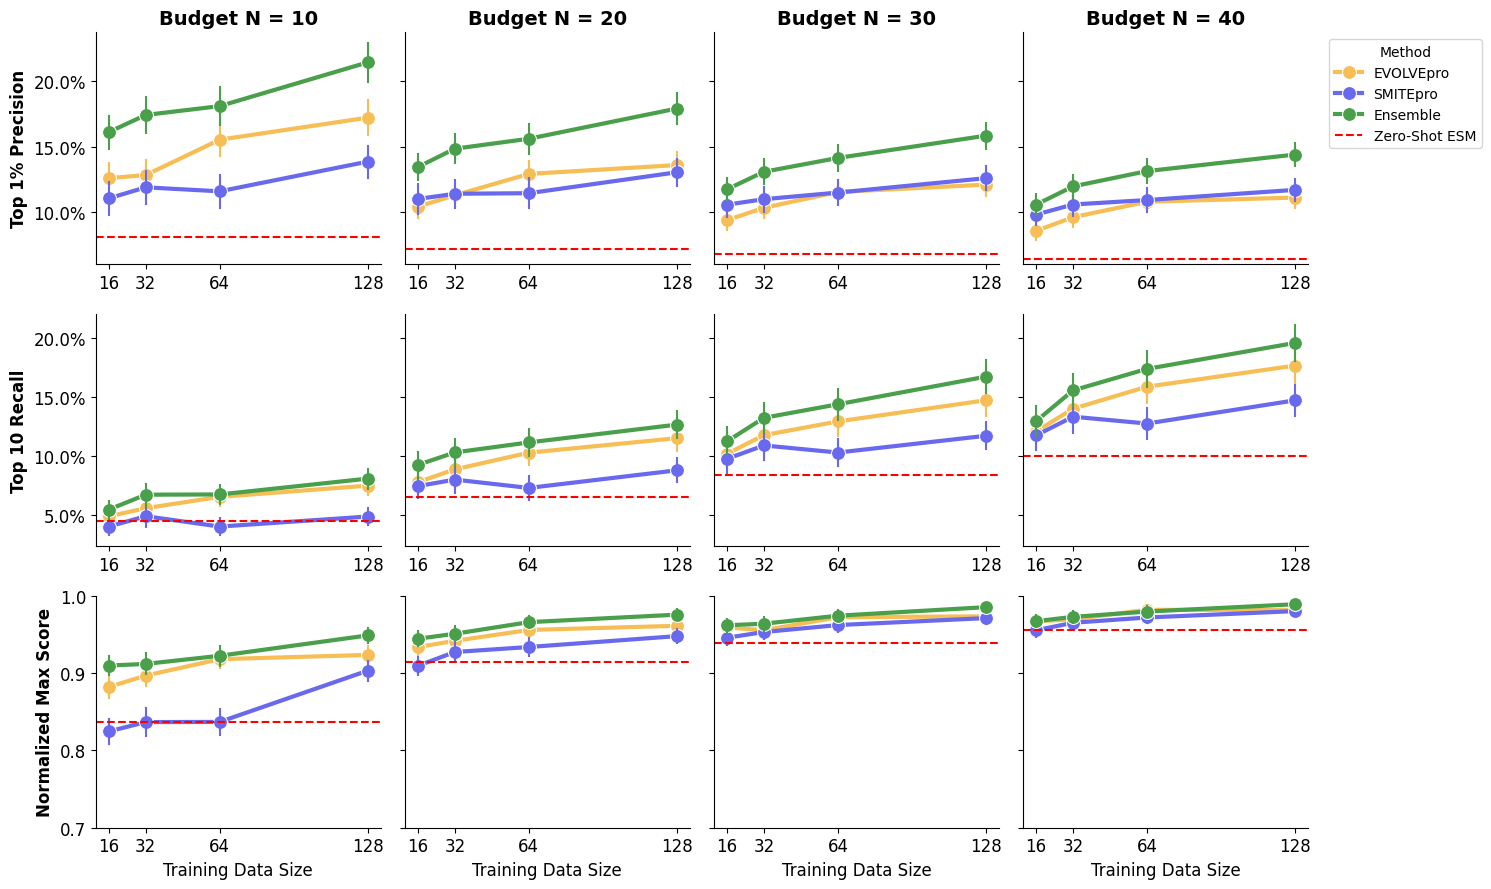

In [ ]:
import matplotlib.ticker as mtick
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import warnings

metrics_df = pd.read_csv('evaluation_metrics.csv')

warnings.filterwarnings("ignore")

plot_metrics_df = metrics_df.copy()

baseline_metrics_df = plot_metrics_df[plot_metrics_df['method'] == 'Zero-Shot ESM']
model_metrics_df = plot_metrics_df[plot_metrics_df['method'] != 'Zero-Shot ESM']

baseline_metrics_df['method'] = baseline_metrics_df['method'].replace('Combined', 'Ensemble')
model_metrics_df['method'] = model_metrics_df['method'].replace('Combined', 'Ensemble')

metrics_to_plot = ['Top 1% Precision', 'Top 10 Recall', 'Normalized Max Score']
budgets_to_plot = [10, 20, 30, 40]

method_order = ['EVOLVEpro', 'SMITEpro', 'Ensemble']

custom_colors = {
    'EVOLVEpro': "#F6BE55",
    'SMITEpro': "#6969EE",
    'Ensemble': "#4A9F4A"
}

fig, axes = plt.subplots(len(metrics_to_plot), len(budgets_to_plot), figsize=(15, 9), sharey='row')

for i, metric in enumerate(metrics_to_plot):
    for j, n in enumerate(budgets_to_plot):
        ax = axes[i, j]
        
        data_subset = model_metrics_df[
            (model_metrics_df['metric'] == metric) & 
            (model_metrics_df['N'] == n)
        ]
        
        if data_subset.empty:
            continue
        
        data_subset = data_subset[~data_subset['train_size'].isin([4, 8])]

        sns.lineplot(
            data=data_subset,
            x="train_size",
            y="value",
            hue="method",
            hue_order=method_order, 
            palette=custom_colors, 
            errorbar="se",
            marker="o",
            err_style="bars",
            linewidth=3,
            markersize=10,
            ax=ax
        )
        
        if metric in ['Top 1% Precision', 'Top 10 Recall']:
            ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        
        zs_subset = baseline_metrics_df[
            (baseline_metrics_df['metric'] == metric) & 
            (baseline_metrics_df['N'] == n)
        ]
        if not zs_subset.empty:
            zs_val = zs_subset['value'].mean()
            if not pd.isna(zs_val):
                ax.axhline(y=zs_val, color='red', linestyle='--', linewidth=1.5, label='Zero-Shot ESM')
        
        if j == 0:
            ax.set_ylabel(metric, fontsize=12, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        if i == 0:
            ax.set_title(f"Budget N = {n}", fontsize=14, fontweight='bold')

        if metric == 'Normalized Max Score':
            ax.set_ylim(0.7, 1)

        ax.set_xticks([16, 32, 64, 128])
        ax.tick_params(axis='both', which='major', labelsize=12)
        
        sns.despine(ax=ax)
        
        if i == len(metrics_to_plot) - 1:
            ax.set_xlabel("Training Data Size", fontsize=12)
        else:
            ax.set_xlabel("")

        if i == 0 and j == len(budgets_to_plot) - 1:
             ax.legend(title="Method", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            if ax.get_legend() is not None:
                ax.get_legend().remove()
                
plt.tight_layout()
plt.show()

In [6]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import warnings

warnings.filterwarnings("ignore")

dir_path = '.'
n_values = [10, 20, 30, 40]
records = []

for file in os.listdir(dir_path):
    if not file.endswith('.csv'):
        continue
        
    df = pd.read_csv(os.path.join(dir_path, file))
    
    if 'mutated_sequence' not in df.columns or 'mutant' not in df.columns:
        continue

    unique_sites = set()
    for pos in df['mutant']:
        positions = pos.split(':')
        for position in positions:
            unique_sites.add(position[1:-1])
    num_sites = len(unique_sites)

    if num_sites < 100:
        continue

    system_name = file.replace('.csv', '')
    train_size = int(file.split('_shot')[1].split('.csv')[0])
    
    if 'pred_epro' in df.columns and 'pred_my_method' in df.columns:
        min_e, max_e = df['pred_epro'].min(), df['pred_epro'].max()
        min_s, max_s = df['pred_my_method'].min(), df['pred_my_method'].max()
        mm_epro = (df['pred_epro'] - min_e) / (max_e - min_e + 1e-8)
        mm_smite = (df['pred_my_method'] - min_s) / (max_s - min_s + 1e-8)
        df['combined_score'] = (mm_smite + mm_epro) / 2

    if 'is_train' in df.columns:
        eval_df = df[~df['is_train']].copy()
    else:
        eval_df = df.copy()

    def calc_metrics(eval_df, pred_col, method_name, train_size, global_df):
        results = []
        
        threshold_1pct = global_df['target'].quantile(0.99)
        true_top_1pct_indices = set(global_df[global_df['target'] >= threshold_1pct].index)
        background_hit_rate = len(true_top_1pct_indices) / len(global_df)
        if background_hit_rate == 0: background_hit_rate = 1e-8
        
        min_target = global_df['target'].min()

        for n in n_values:
            pred_top_n = eval_df.nlargest(n, pred_col)
            pred_indices = set(pred_top_n.index)
            
            # Enrichment Factor
            prec_hits = len(pred_indices.intersection(true_top_1pct_indices))
            model_hit_rate = prec_hits / n
            enrichment = model_hit_rate / background_hit_rate
            
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Enrichment Factor', 'value': enrichment, 'N': n
            })

            # Mean Top-N Fitness
            mean_fitness = pred_top_n['target'].mean()
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Mean Top-N Fitness', 'value': mean_fitness, 'N': n
            })

            # NDCG@N
            relevances = pred_top_n['target'].values
            shifted_rels = relevances - min_target
            dcg = np.sum(shifted_rels / np.log2(np.arange(2, n + 2)))
            
            ideal_top_n = eval_df.nlargest(n, 'target')['target'].values
            ideal_shifted_rels = ideal_top_n - min_target
            idcg = np.sum(ideal_shifted_rels / np.log2(np.arange(2, n + 2)))
            
            ndcg = dcg / idcg if idcg > 0 else 0
            
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'NDCG', 'value': ndcg, 'N': n
            })
            
        return results

    if 'pred_my_method' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_my_method', 'SMITEpro', train_size, df))
    if 'pred_epro' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_epro', 'EVOLVEpro', train_size, df))
    if 'combined_score' in df.columns:
        records.extend(calc_metrics(eval_df, 'combined_score', 'Ensemble', train_size, df))
    if 'delta_esm' in df.columns and file.endswith('shot32.csv'):
        records.extend(calc_metrics(eval_df, 'delta_esm', 'Zero-Shot ESM', 0, df))

metrics_df = pd.DataFrame(records)
metrics_df.to_csv('evaluation_metrics_v2.csv', index=False)


KeyboardInterrupt: 

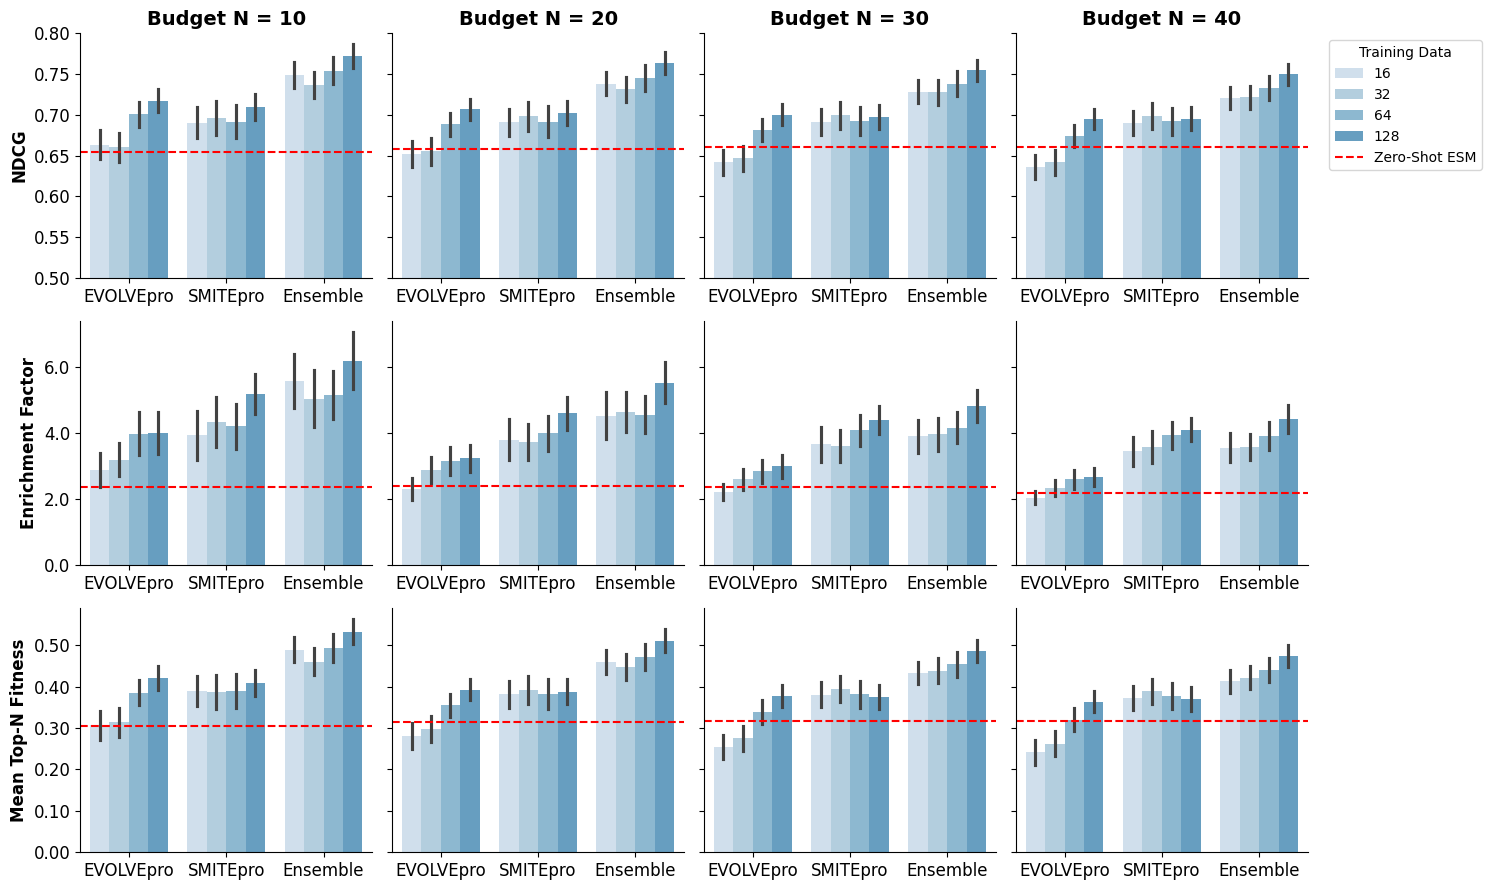

In [ ]:
# Plotting block
baseline_metrics_df = metrics_df[metrics_df['method'] == 'Zero-Shot ESM']
model_metrics_df = metrics_df[metrics_df['method'] != 'Zero-Shot ESM']

metrics_to_plot = ['NDCG', 'Enrichment Factor', 'Mean Top-N Fitness']
budgets_to_plot = [10, 20, 30, 40]
method_order = ['EVOLVEpro', 'SMITEpro', 'Ensemble']

fig, axes = plt.subplots(len(metrics_to_plot), len(budgets_to_plot), figsize=(15, 9), sharey='row')

for i, metric in enumerate(metrics_to_plot):

    # Set y-axis formatting based on metric type
    if metric == 'Enrichment Factor':
        axes[i, 0].set_ylabel(metric, fontsize=12, fontweight='bold')
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f'))
    elif metric == 'Mean Top-N Fitness':
        axes[i, 0].set_ylabel(metric, fontsize=12, fontweight='bold')
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
    else:
        axes[i, 0].set_ylabel(metric, fontsize=12, fontweight='bold')
        # scale NDCG y axis 0 to 1
        axes[i, 0].set_ylim(0.5, 0.8)

    for j, n in enumerate(budgets_to_plot):
        ax = axes[i, j]
        
        data_subset = model_metrics_df[
            (model_metrics_df['metric'] == metric) & 
            (model_metrics_df['N'] == n)
        ]
        
        if data_subset.empty:
            continue
        
        blue_palette = sns.color_palette("Blues", 8)[1:-1]
        data_subset = data_subset[~data_subset['train_size'].isin([4, 8])]

        sns.barplot(
            data=data_subset,
            x="method",
            y="value",
            hue="train_size",
            order=method_order, 
            palette=blue_palette, 
            errorbar="se",
            ax=ax
        )
        
        zs_subset = baseline_metrics_df[
            (baseline_metrics_df['metric'] == metric) & 
            (baseline_metrics_df['N'] == n)
        ]
        if not zs_subset.empty:
            zs_val = zs_subset['value'].mean()
            if not pd.isna(zs_val):
                ax.axhline(y=zs_val, color='red', linestyle='--', linewidth=1.5, label='Zero-Shot ESM')
        
        if j == 0:
            ax.set_ylabel(metric, fontsize=12, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        if i == 0:
            ax.set_title(f"Budget N = {n}", fontsize=14, fontweight='bold')

        # make ticks larger for better readability
        ax.tick_params(axis='both', which='major', labelsize=12)

        sns.despine(ax=ax)
        ax.set_xlabel("")

        if i == 0 and j == len(budgets_to_plot)-1:
             ax.legend(title="Training Data", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            if ax.get_legend() is not None:
                ax.get_legend().remove()
                
plt.tight_layout()
plt.show()

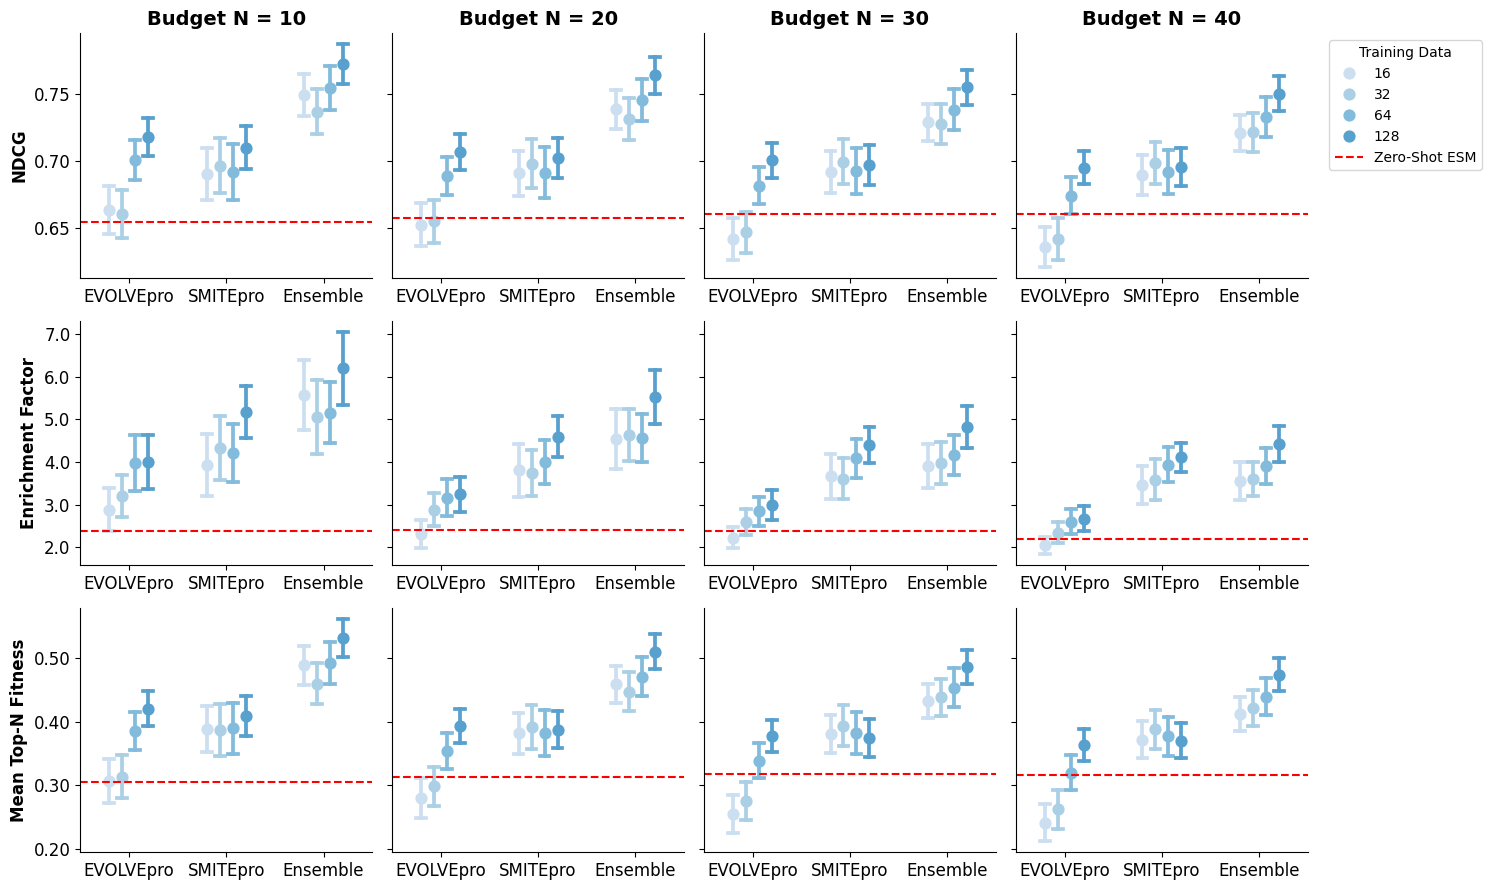

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# load dataset
metrics_df = pd.read_csv('evaluation_metrics_v2.csv')

# Plotting block
baseline_metrics_df = metrics_df[metrics_df['method'] == 'Zero-Shot ESM']
model_metrics_df = metrics_df[metrics_df['method'] != 'Zero-Shot ESM']

metrics_to_plot = ['NDCG', 'Enrichment Factor', 'Mean Top-N Fitness']
budgets_to_plot = [10, 20, 30, 40]
method_order = ['EVOLVEpro', 'SMITEpro', 'Ensemble']

fig, axes = plt.subplots(len(metrics_to_plot), len(budgets_to_plot), figsize=(15, 9), sharey='row')

for i, metric in enumerate(metrics_to_plot):

    # Set y-axis formatting based on metric type
    if metric == 'Enrichment Factor':
        axes[i, 0].set_ylabel(metric, fontsize=12, fontweight='bold')
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f'))
    elif metric == 'Mean Top-N Fitness':
        axes[i, 0].set_ylabel(metric, fontsize=12, fontweight='bold')
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
    else:
        axes[i, 0].set_ylabel(metric, fontsize=12, fontweight='bold')
        # scale NDCG y axis 0 to 1
        # axes[i, 0].set_ylim(0.5, 0.8)

    for j, n in enumerate(budgets_to_plot):
        ax = axes[i, j]
        
        data_subset = model_metrics_df[
            (model_metrics_df['metric'] == metric) & 
            (model_metrics_df['N'] == n)
        ]
        
        if data_subset.empty:
            continue
        
        blue_palette = sns.color_palette("Blues", 8)[1:-1]
        data_subset = data_subset[~data_subset['train_size'].isin([4, 8])]

        # Use pointplot for mean dots and standard error bars
        sns.pointplot(
            data=data_subset,
            x="method",
            y="value",
            hue="train_size",
            order=method_order, 
            palette=blue_palette, 
            dodge=0.4,
            errorbar="se",
            linestyle="none",
            marker="o",
            capsize=0.1,
            ax=ax
        )
        
        zs_subset = baseline_metrics_df[
            (baseline_metrics_df['metric'] == metric) & 
            (baseline_metrics_df['N'] == n)
        ]
        if not zs_subset.empty:
            zs_val = zs_subset['value'].mean()
            if not pd.isna(zs_val):
                ax.axhline(y=zs_val, color='red', linestyle='--', linewidth=1.5, label='Zero-Shot ESM')
        
        if j == 0:
            ax.set_ylabel(metric, fontsize=12, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        if i == 0:
            ax.set_title(f"Budget N = {n}", fontsize=14, fontweight='bold')

        # make ticks larger for better readability
        ax.tick_params(axis='both', which='major', labelsize=12)

        sns.despine(ax=ax)
        ax.set_xlabel("")

        if i == 0 and j == len(budgets_to_plot)-1:
             ax.legend(title="Training Data", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            if ax.get_legend() is not None:
                ax.get_legend().remove()
                
plt.tight_layout()
plt.show()

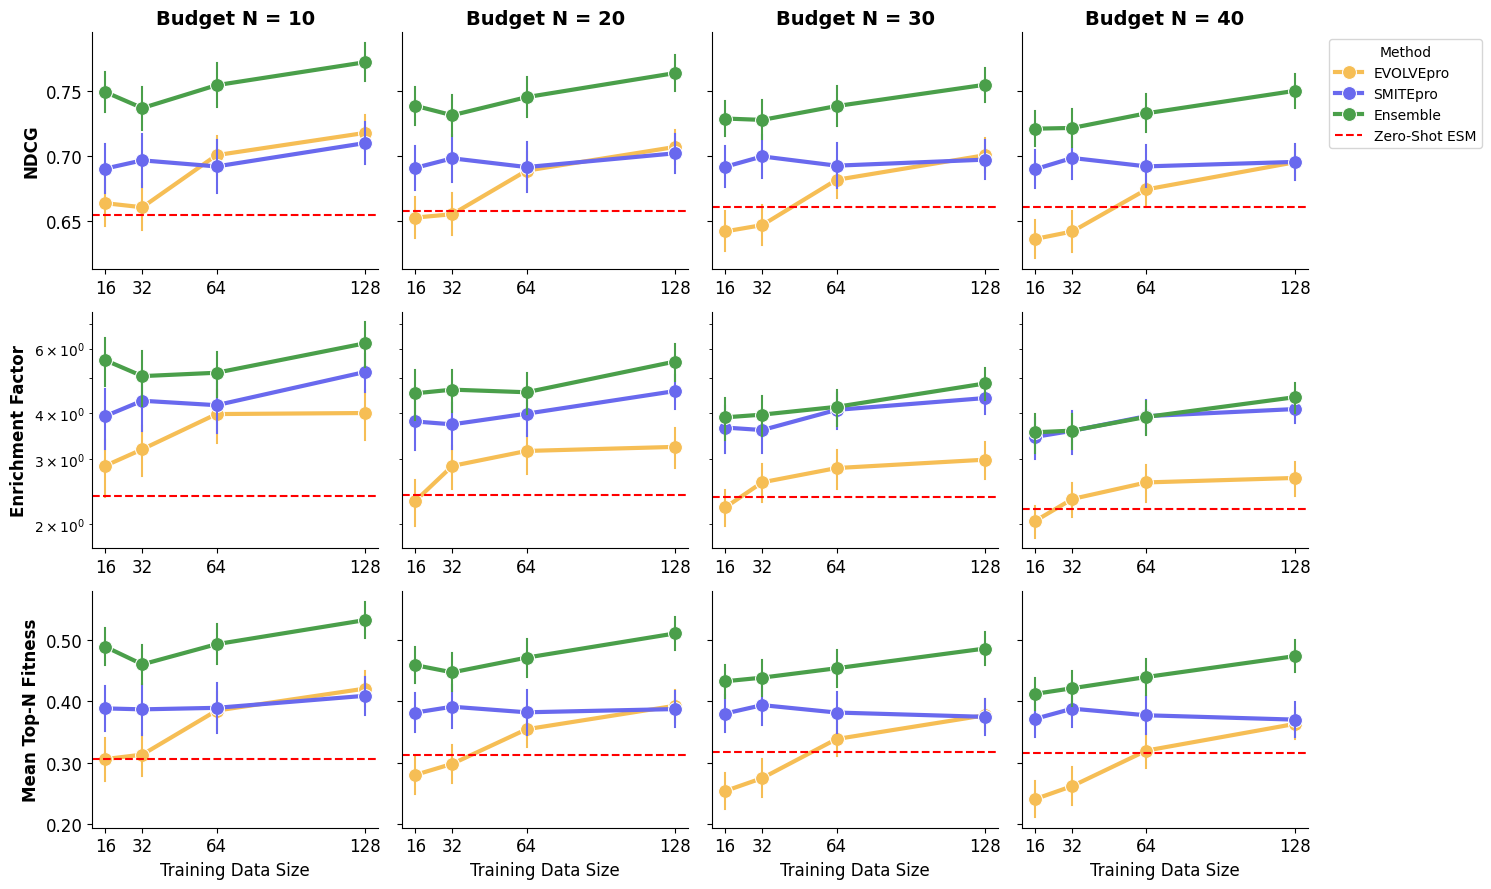

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# load dataset
metrics_df = pd.read_csv('evaluation_metrics_v2.csv')

# Plotting block
baseline_metrics_df = metrics_df[metrics_df['method'] == 'Zero-Shot ESM']
model_metrics_df = metrics_df[metrics_df['method'] != 'Zero-Shot ESM']

metrics_to_plot = ['NDCG', 'Enrichment Factor', 'Mean Top-N Fitness']
budgets_to_plot = [10, 20, 30, 40]
method_order = ['EVOLVEpro', 'SMITEpro', 'Ensemble']

# Custom palette mapping
custom_colors = {
    'EVOLVEpro': "#F6BE55",
    'SMITEpro': "#6969EE",
    'Ensemble': "#4A9F4A"
}

fig, axes = plt.subplots(len(metrics_to_plot), len(budgets_to_plot), figsize=(15, 9), sharey='row')

for i, metric in enumerate(metrics_to_plot):

    for j, n in enumerate(budgets_to_plot):
        ax = axes[i, j]
        
        data_subset = model_metrics_df[
            (model_metrics_df['metric'] == metric) & 
            (model_metrics_df['N'] == n)
        ]
        
        if data_subset.empty:
            continue
        
        data_subset = data_subset[~data_subset['train_size'].isin([4, 8])]

        # Use lineplot with the custom color palette
        sns.lineplot(
            data=data_subset,
            x="train_size",
            y="value",
            hue="method",
            hue_order=method_order, 
            palette=custom_colors, 
            errorbar="se",
            marker="o",
            err_style="bars",
            ax=ax,
            linewidth=3,
            markersize=10
        )
        
        zs_subset = baseline_metrics_df[
            (baseline_metrics_df['metric'] == metric) & 
            (baseline_metrics_df['N'] == n)
        ]
        if not zs_subset.empty:
            zs_val = zs_subset['value'].mean()
            if not pd.isna(zs_val):
                ax.axhline(y=zs_val, color='red', linestyle='--', linewidth=1.5, label='Zero-Shot ESM')
        
        if j == 0:
            ax.set_ylabel(metric, fontsize=12, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        if i == 0:
            ax.set_title(f"Budget N = {n}", fontsize=14, fontweight='bold')

        ax.set_xticks([16, 32, 64, 128])
        ax.tick_params(axis='both', which='major', labelsize=12)

        sns.despine(ax=ax)
        
        if i == len(metrics_to_plot) - 1:
            ax.set_xlabel("Training Data Size", fontsize=12)
        else:
            ax.set_xlabel("")

        # Handle legend
        if i == 0 and j == len(budgets_to_plot)-1:
             ax.legend(title="Method", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            if ax.get_legend() is not None:
                ax.get_legend().remove()

    # Apply y-axis formatting per row
    if metric == 'Enrichment Factor':
        axes[i, 0].set_yscale('log')
        formatter = mtick.ScalarFormatter()
        formatter.set_scientific(False)
        axes[i, 0].yaxis.set_major_formatter(formatter)
    elif metric == 'Mean Top-N Fitness':
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
                
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import warnings

warnings.filterwarnings("ignore")

dir_path = '.'
n_values = [10, 20, 30, 40]
records = []

for file in os.listdir(dir_path):
    if not file.endswith('.csv'):
        continue
        
    df = pd.read_csv(os.path.join(dir_path, file))
    
    if 'mutated_sequence' not in df.columns or 'mutant' not in df.columns:
        continue

    unique_sites = set()
    for pos in df['mutant']:
        positions = pos.split(':')
        for position in positions:
            unique_sites.add(position[1:-1])
    num_sites = len(unique_sites)

    # if num_sites < 100:
    #     continue

    system_name = file.replace('.csv', '')
    train_size = int(file.split('_shot')[1].split('.csv')[0])
    
    if 'pred_epro' in df.columns and 'pred_my_method' in df.columns:
        min_e, max_e = df['pred_epro'].min(), df['pred_epro'].max()
        min_s, max_s = df['pred_my_method'].min(), df['pred_my_method'].max()
        mm_epro = (df['pred_epro'] - min_e) / (max_e - min_e + 1e-8)
        mm_smite = (df['pred_my_method'] - min_s) / (max_s - min_s + 1e-8)
        df['combined_score'] = (mm_smite + mm_epro) / 2

    if 'is_train' in df.columns:
        eval_df = df[~df['is_train']].copy()
    else:
        eval_df = df.copy()

    def calc_metrics(eval_df, pred_col, method_name, train_size, global_df):
        results = []
        
        threshold_1pct = global_df['target'].quantile(0.99)
        true_top_1pct_indices = set(global_df[global_df['target'] >= threshold_1pct].index)
        background_hit_rate = len(true_top_1pct_indices) / len(global_df)
        if background_hit_rate == 0: background_hit_rate = 1e-8
        
        min_target = global_df['target'].min()

        for n in n_values:
            pred_top_n = eval_df.nlargest(n, pred_col)
            pred_indices = set(pred_top_n.index)
            
            # Enrichment Factor
            prec_hits = len(pred_indices.intersection(true_top_1pct_indices))
            
            # Handle cases where eval_df has fewer than N rows
            actual_n = len(pred_top_n)
            if actual_n == 0:
                continue
                
            model_hit_rate = prec_hits / actual_n
            enrichment = model_hit_rate / background_hit_rate
            
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Enrichment Factor', 'value': enrichment, 'N': n
            })

            # Mean Top-N Fitness
            mean_fitness = pred_top_n['target'].mean()
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'Mean Top-N Fitness', 'value': mean_fitness, 'N': n
            })

            # NDCG@N
            relevances = pred_top_n['target'].values
            shifted_rels = relevances - min_target
            k = len(shifted_rels)
            dcg = np.sum(shifted_rels / np.log2(np.arange(2, k + 2)))
            
            ideal_top_n = eval_df.nlargest(n, 'target')['target'].values
            ideal_shifted_rels = ideal_top_n - min_target
            ideal_k = len(ideal_shifted_rels)
            idcg = np.sum(ideal_shifted_rels / np.log2(np.arange(2, ideal_k + 2)))
            
            ndcg = dcg / idcg if idcg > 0 else 0
            
            results.append({
                'system': system_name, 'train_size': train_size, 'method': method_name,
                'metric': 'NDCG', 'value': ndcg, 'N': n
            })
            
        return results
    
    if 'pred_my_method' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_my_method', 'SMITEpro', train_size, df))
    if 'pred_epro' in df.columns:
        records.extend(calc_metrics(eval_df, 'pred_epro', 'EVOLVEpro', train_size, df))
    if 'combined_score' in df.columns:
        records.extend(calc_metrics(eval_df, 'combined_score', 'Ensemble', train_size, df))
    if 'delta_esm' in df.columns and file.endswith('shot32.csv'):
        records.extend(calc_metrics(eval_df, 'delta_esm', 'Zero-Shot ESM', 0, df))

metrics_df = pd.DataFrame(records)
metrics_df.to_csv('evaluation_metrics_v3.csv', index=False)


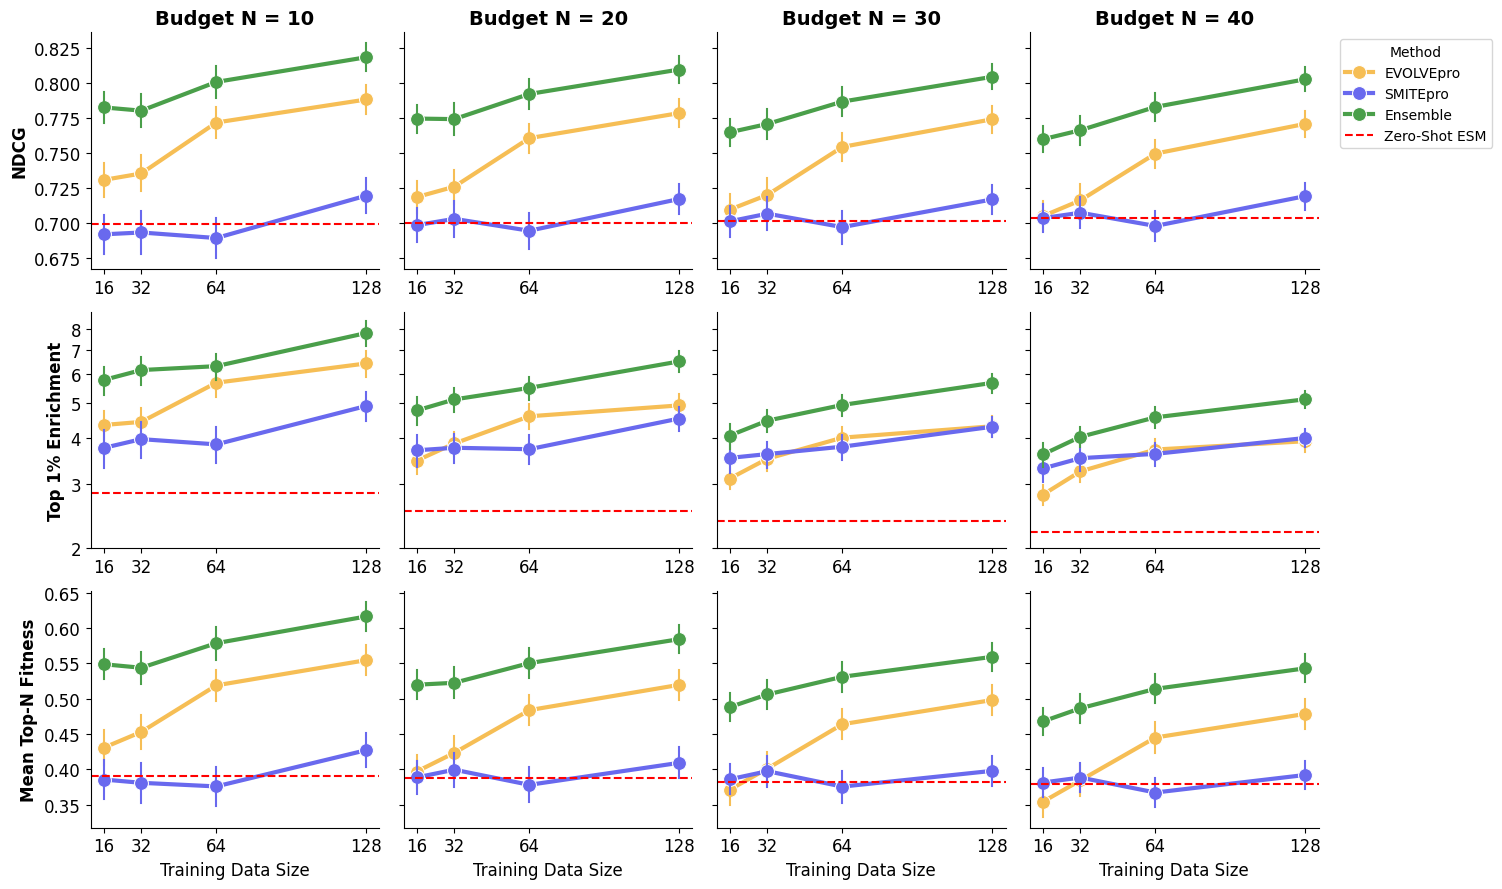

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# load dataset
metrics_df = pd.read_csv('evaluation_metrics_v3.csv')

# Plotting block
baseline_metrics_df = metrics_df[metrics_df['method'] == 'Zero-Shot ESM']
model_metrics_df = metrics_df[metrics_df['method'] != 'Zero-Shot ESM']

metrics_to_plot = ['NDCG', 'Enrichment Factor', 'Mean Top-N Fitness']
budgets_to_plot = [10, 20, 30, 40]
method_order = ['EVOLVEpro', 'SMITEpro', 'Ensemble']

# Custom palette mapping
custom_colors = {
    'EVOLVEpro': "#F6BE55",
    'SMITEpro': "#6969EE",
    'Ensemble': "#4A9F4A"
}

fig, axes = plt.subplots(len(metrics_to_plot), len(budgets_to_plot), figsize=(15, 9), sharey='row')

for i, metric in enumerate(metrics_to_plot):

    for j, n in enumerate(budgets_to_plot):
        ax = axes[i, j]
        
        data_subset = model_metrics_df[
            (model_metrics_df['metric'] == metric) & 
            (model_metrics_df['N'] == n)
        ]
        
        if data_subset.empty:
            continue
        
        data_subset = data_subset[~data_subset['train_size'].isin([4, 8])]

        # Use lineplot with the custom color palette
        sns.lineplot(
            data=data_subset,
            x="train_size",
            y="value",
            hue="method",
            hue_order=method_order, 
            palette=custom_colors, 
            errorbar="se",
            marker="o",
            err_style="bars",
            ax=ax,
            linewidth=3,
            markersize=10
        )
        
        zs_subset = baseline_metrics_df[
            (baseline_metrics_df['metric'] == metric) & 
            (baseline_metrics_df['N'] == n)
        ]
        if not zs_subset.empty:
            zs_val = zs_subset['value'].mean()
            if not pd.isna(zs_val):
                ax.axhline(y=zs_val, color='red', linestyle='--', linewidth=1.5, label='Zero-Shot ESM')
        
        if j == 0:
            ax.set_ylabel(metric, fontsize=12, fontweight='bold')
        else:
            ax.set_ylabel("")
            
        if i == 0:
            ax.set_title(f"Budget N = {n}", fontsize=14, fontweight='bold')

        ax.set_xticks([16, 32, 64, 128])
        ax.tick_params(axis='both', which='major', labelsize=12)

        sns.despine(ax=ax)
        
        if i == len(metrics_to_plot) - 1:
            ax.set_xlabel("Training Data Size", fontsize=12)
        else:
            ax.set_xlabel("")

        # Handle legend
        if i == 0 and j == len(budgets_to_plot)-1:
             ax.legend(title="Method", bbox_to_anchor=(1.05, 1), loc='upper left')
        else:
            if ax.get_legend() is not None:
                ax.get_legend().remove()

    # Apply y-axis formatting per row
    if metric == 'Enrichment Factor':
        # relabel y axis to "Top 1% Enrichment"
        axes[i, 0].set_ylabel('Top 1% Enrichment')
        axes[i, 0].set_yscale('log')
        axes[i, 0].set_ylim(2, 8.9)
        # Force ticks at specific integers
        axes[i, 0].set_yticks([2, 3, 4, 5, 6, 7, 8])
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
        axes[i, 0].yaxis.set_minor_formatter(mtick.NullFormatter())
    elif metric == 'Mean Top-N Fitness':
        axes[i, 0].yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
                
plt.tight_layout()
plt.show()

In [ ]:
# Inspection Cell for Debugging
debug_file = 'Q2N0S5_9HIV1_Haddox_2018_final_predictions_shot32.csv'
if os.path.exists(debug_file):
    debug_df = pd.read_csv(debug_file)
    print(f"Dataset Size: {len(debug_df)}")
    
    # Target stats
    print(f"Target Max: {debug_df['target'].max()}")
    print(f"Target 99th percentile: {debug_df['target'].quantile(0.99)}")
    
    k_debug = max(1, int(0.01 * len(debug_df)))
    print(f"Top 1% Count (k): {k_debug}")
    
    top_targets = debug_df.nlargest(k_debug, 'target')
    print(f"Smallest value in Top 1%: {top_targets['target'].min()}")
    
    # Check predictions
    pred_col = 'pred_my_method' 
    if pred_col in debug_df.columns:
        top_preds = debug_df.nlargest(20, pred_col)
        print(f"Top 20 Predicted Targets:\n{top_preds[['target', pred_col]]}")
        
        # Check intersection
        hits = set(top_preds.index).intersection(set(top_targets.index))
        print(f"Hits in Top 20: {len(hits)}")
        print(f"Hit Indices: {hits}")
        
        # Check max score found
        max_found = top_preds['target'].max()
        print(f"Max Target in Top 20 Preds: {max_found}")
        print(f"Normalized Score: {max_found / debug_df['target'].max()}")
    else:
        print("Prediction column not found")

Dataset Size: 12697
Target Max: 1.0
Target 99th percentile: 1.0
Top 1% Count (k): 126
Smallest value in Top 1%: 1.0
Top 20 Predicted Targets:
        target  pred_my_method
3992  0.685764        7.828125
7200  0.638355        7.781250
7201  0.836095        7.781250
7211  0.673268        7.781250
7205  0.549260        7.718750
3983  0.987439        7.671875
7207  0.716305        7.656250
7212  0.677872        7.656250
7199  0.213311        7.593750
7209  0.599909        7.593750
7213  0.150683        7.593750
7214  0.638683        7.593750
3978  0.771997        7.578125
3991  0.486855        7.578125
3993  1.000000        7.578125
3988  0.527018        7.546875
7203  0.631693        7.531250
7210  0.578142        7.531250
3982  0.573860        7.515625
3984  0.701053        7.484375
Hits in Top 20: 0
Hit Indices: set()
Max Target in Top 20 Preds: 1.0
Normalized Score: 1.0


In [ ]:
# filter topk_df to include only system in long_df_filtered
topk_df_filtered = topk_df[topk_df['system'].isin(long_df_filtered['system'].unique())].reset_index(drop=True)

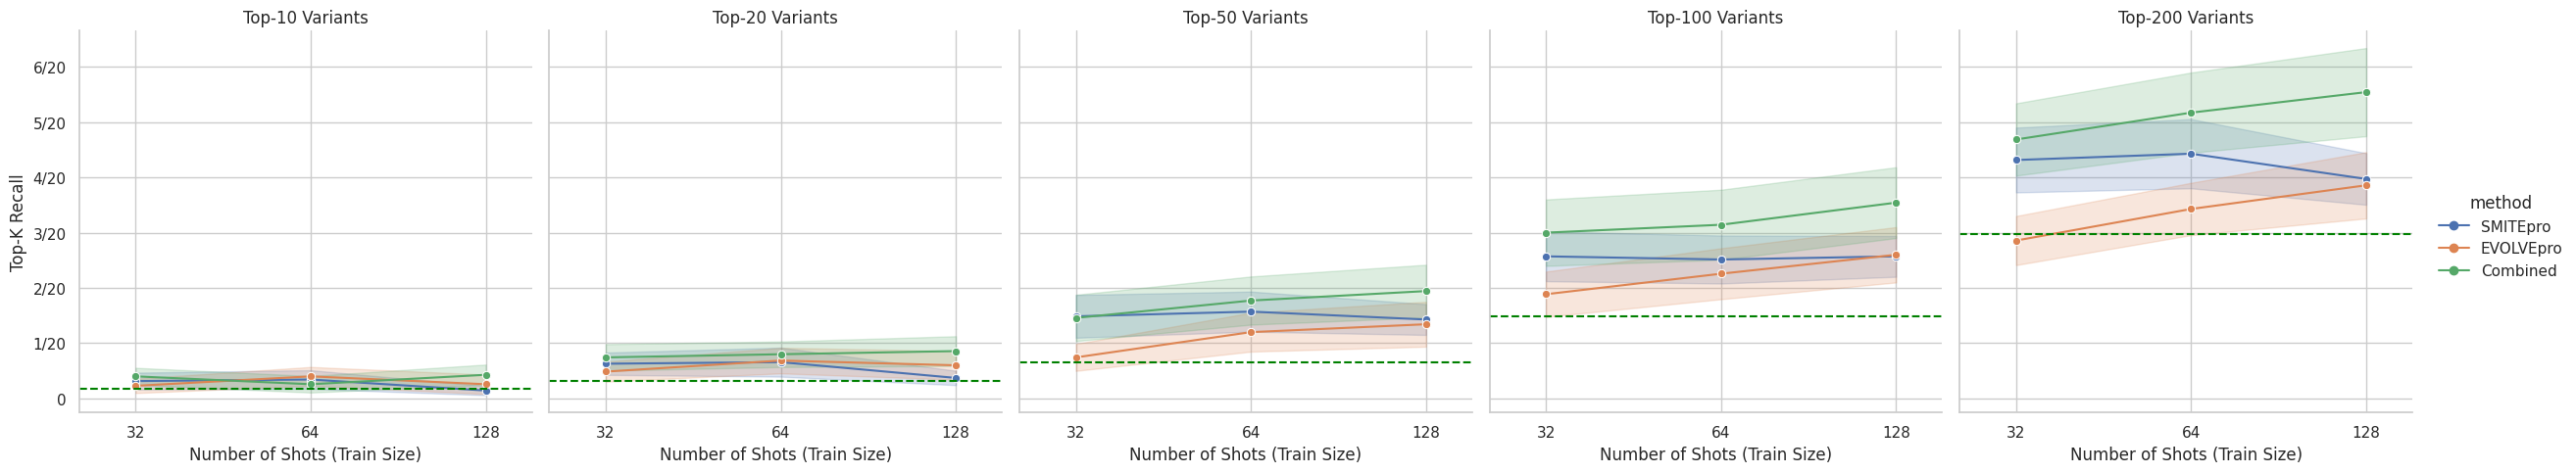

In [ ]:
import matplotlib.ticker as ticker

# Filter out Zero-Shot ESM from the main plot data so it doesn't mess up log scale
plot_topk_df = topk_df_filtered[topk_df_filtered['method'] != 'Zero-Shot ESM']

# remove Combined method from the plot
# plot_topk_df = plot_topk_df[plot_topk_df['method'] != 'Combined']

# 1. Generate the plot
g = sns.relplot(
    data=plot_topk_df,
    x="train_size",
    y="recall",
    hue="method",
    col="k",
    kind="line",
    marker="o",
    errorbar='se', #("ci", 95),
    height=5,
    aspect=1
)

# 2. Fix the axes
unique_train_sizes = sorted(plot_topk_df['train_size'].unique())

for ax, k in zip(g.axes.flat, k_values):
    # Add horizontal baseline
    # We use the full dataframe to calculate the baseline
    esm_data = topk_df_filtered[(topk_df_filtered['method'] == 'Zero-Shot ESM') & (topk_df_filtered['k'] == k)]
    if not esm_data.empty:
        esm_recall = esm_data['recall'].mean()
        ax.axhline(esm_recall, color='green', linestyle='--', label='Zero-Shot ESM Baseline')
    
    # --- The Fix ---
    ax.set_xscale('log', base=2)
    if unique_train_sizes:
        ax.set_xticks(unique_train_sizes)
        # Use ScalarFormatter to stop it from using scientific notation/powers of 2
        ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
        # Optional: Adjust limits so the markers don't sit right on the edge
        ax.set_xlim(min(unique_train_sizes) * 0.8, max(unique_train_sizes) * 1.2)

g.set_axis_labels("Number of Shots (Train Size)", "Top-K Recall")
g.set_titles("Top-{col_name} Variants")
g.set(yticks=[0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3], yticklabels=['0', '1/20', '2/20', '3/20', '4/20', '5/20', '6/20'])

plt.show()

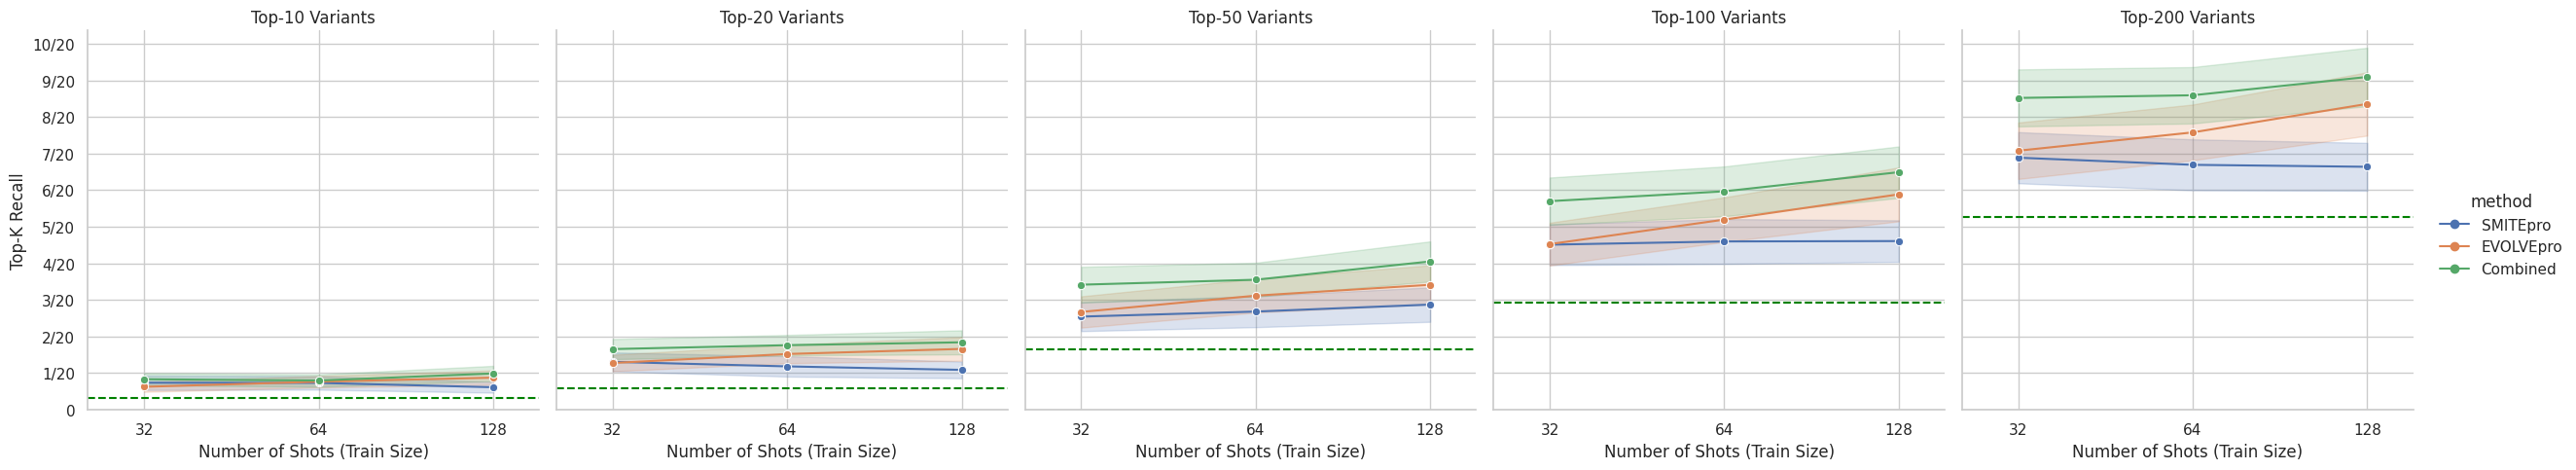

In [ ]:
import matplotlib.ticker as ticker
import seaborn as sns
import matplotlib.pyplot as plt

# Filter out Zero-Shot ESM from the log-scale plot data
plot_topk_df = topk_df[topk_df['method'] != 'Zero-Shot ESM']

# 1. Generate the plot
g = sns.relplot(
    data=plot_topk_df,
    x="train_size",
    y="recall",
    hue="method",
    col="k",
    kind="line",
    marker="o",
    errorbar="se",#("ci", 95),
    height=5,
    aspect=1
)

# 2. Fix the axes
unique_train_sizes = sorted(plot_topk_df['train_size'].unique())

for ax, k in zip(g.axes.flat, k_values):
    # Add horizontal baseline
    esm_data = topk_df[(topk_df['method'] == 'Zero-Shot ESM') & (topk_df['k'] == k)]
    if not esm_data.empty:
        esm_recall = esm_data['recall'].mean()
        ax.axhline(esm_recall, color='green', linestyle='--', label='Zero-Shot ESM Baseline')
    
    # --- The Fix ---
    ax.set_xscale('log', base=2)
    if unique_train_sizes:
        ax.set_xticks(unique_train_sizes)
        # Use ScalarFormatter to stop it from using scientific notation/powers of 2
        ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
        # Optional: Adjust limits so the markers don't sit right on the edge
        ax.set_xlim(min(unique_train_sizes) * 0.8, max(unique_train_sizes) * 1.2)

g.set_axis_labels("Number of Shots (Train Size)", "Top-K Recall")
g.set_titles("Top-{col_name} Variants")
g.set(yticks=[0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5], yticklabels=['0', '1/20', '2/20', '3/20', '4/20', '5/20', '6/20', '7/20', '8/20', '9/20', '10/20'])

plt.show()

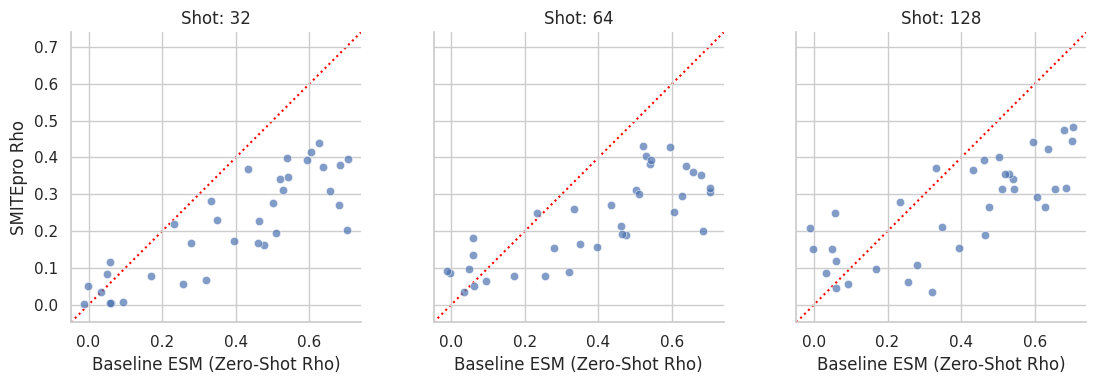

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extract baseline ESM scores
baseline_df = (long_df_filtered[long_df_filtered['method'] == 'Zero-Shot ESM']
               [['system', 'rho']]
               .drop_duplicates(subset=['system'])
               .rename(columns={'rho': 'Baseline_rho'}))

# 2. Extract SMITEpro scores
smite_df = (long_df_filtered[long_df_filtered['method'] == 'SMITEpro']
            [['system', 'train_size', 'rho']]
            .rename(columns={'rho': 'SMITEpro_rho'}))

# 3. Create a clean join column by removing the shot number from both
smite_df['join_key'] = smite_df['system'].str.split('_shot').str[0]
baseline_df['join_key'] = baseline_df['system'].str.split('_shot').str[0]

# 4. Merge using the new join key
merged_df = pd.merge(smite_df, baseline_df, on='join_key', how='inner')

# 5. Create the paneled scatterplots
g = sns.relplot(
    data=merged_df,
    x='Baseline_rho',
    y='SMITEpro_rho',
    col='train_size',
    col_wrap=3,
    kind='scatter',
    alpha=0.7,
    height=4
)

for ax in g.axes.flat:
    ax.axline((0, 0), slope=1, color='red', linestyle=':', zorder=0)
    
    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect('equal')

g.set_axis_labels("Baseline ESM (Zero-Shot Rho)", "SMITEpro Rho")
g.set_titles("Shot: {col_name}")

plt.tight_layout()
# plt.savefig("smitepro_vs_baseline_scatter.png", dpi=300)

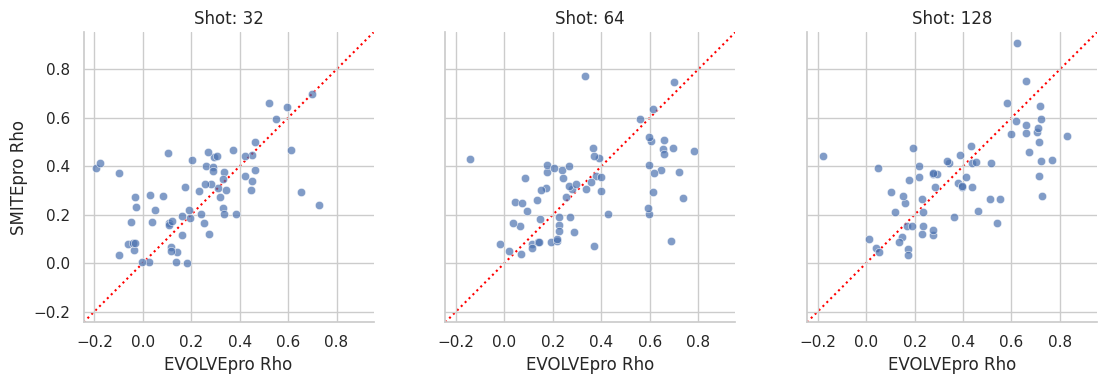

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extract SMITEpro scores
smite_df = (long_df[long_df['method'] == 'SMITEpro']
            [['system', 'train_size', 'rho']]
            .rename(columns={'rho': 'SMITEpro_rho'}))

# 2. Extract EVOLVEpro scores
evolve_df = (long_df[long_df['method'] == 'EVOLVEpro']
             [['system', 'train_size', 'rho']]
             .rename(columns={'rho': 'EVOLVEpro_rho'}))

# 3. Create a clean join column by removing the shot number
smite_df['join_key'] = smite_df['system'].str.split('_shot').str[0]
evolve_df['join_key'] = evolve_df['system'].str.split('_shot').str[0]

# 4. Merge using the new join key and train_size
merged_df = pd.merge(smite_df, evolve_df, on=['join_key', 'train_size'], how='inner')

# 5. Create the paneled scatterplots
g = sns.relplot(
    data=merged_df,
    x='EVOLVEpro_rho',
    y='SMITEpro_rho',
    col='train_size',
    col_wrap=3,
    kind='scatter',
    alpha=0.7,
    height=4
)

for ax in g.axes.flat:
    ax.axline((0, 0), slope=1, color='red', linestyle=':', zorder=0)
    
    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect('equal')

g.set_axis_labels("EVOLVEpro Rho", "SMITEpro Rho")
g.set_titles("Shot: {col_name}")

plt.tight_layout()
plt.show()
# plt.savefig("smitepro_vs_evolvepro_scatter.png", dpi=300)

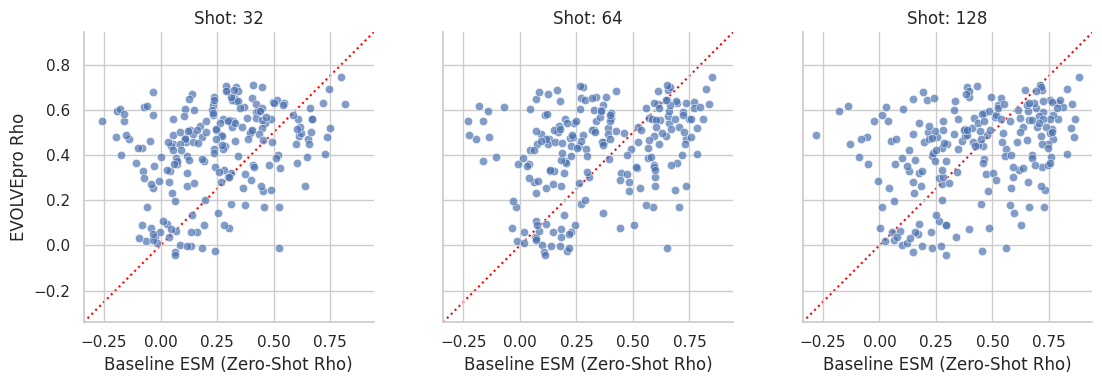

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extract baseline ESM scores
baseline_df = (long_df[long_df['method'] == 'Zero-Shot ESM']
               [['system', 'rho']]
               .drop_duplicates(subset=['system'])
               .rename(columns={'rho': 'Baseline_rho'}))

# 2. Extract EVOLVEpro scores
evolve_df = (long_df[long_df['method'] == 'EVOLVEpro']
             [['system', 'train_size', 'rho']]
             .rename(columns={'rho': 'EVOLVEpro_rho'}))

# 3. Create a clean join column by removing the shot number
baseline_df['join_key'] = baseline_df['system'].str.split('_shot').str[0]
evolve_df['join_key'] = evolve_df['system'].str.split('_shot').str[0]

# 4. Merge using the new join key
merged_df = pd.merge(evolve_df, baseline_df, on='join_key', how='inner')

# 5. Create the paneled scatterplots
g = sns.relplot(
    data=merged_df,
    x='EVOLVEpro_rho',
    y='Baseline_rho',
    col='train_size',
    col_wrap=3,
    kind='scatter',
    alpha=0.7,
    height=4
)

for ax in g.axes.flat:
    ax.axline((0, 0), slope=1, color='red', linestyle=':', zorder=0)
    
    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect('equal')

g.set_axis_labels("Baseline ESM (Zero-Shot Rho)", "EVOLVEpro Rho")
g.set_titles("Shot: {col_name}")

plt.tight_layout()
plt.show()

In [ ]:
# Summary of the new metrics
summary_df = metrics_df.groupby(['method', 'train_size', 'metric'])['value'].mean().reset_index()
print("Summary Statistics for New Metrics:")
print(summary_df)


Summary Statistics for New Metrics:
           method  train_size                metric     value
0        Combined          32  Normalized Max Score  0.958513
1        Combined          32      Top 1% Precision  0.045021
2        Combined          32        Top 5 Hit Rate  0.225962
3        Combined          64  Normalized Max Score  0.964146
4        Combined          64      Top 1% Precision  0.053473
5        Combined          64        Top 5 Hit Rate  0.211538
6        Combined         128  Normalized Max Score  0.981564
7        Combined         128      Top 1% Precision  0.071258
8        Combined         128        Top 5 Hit Rate  0.311881
9       EVOLVEpro          32  Normalized Max Score  0.948669
10      EVOLVEpro          32      Top 1% Precision  0.032953
11      EVOLVEpro          32        Top 5 Hit Rate  0.173077
12      EVOLVEpro          64  Normalized Max Score  0.964214
13      EVOLVEpro          64      Top 1% Precision  0.043292
14      EVOLVEpro          64     

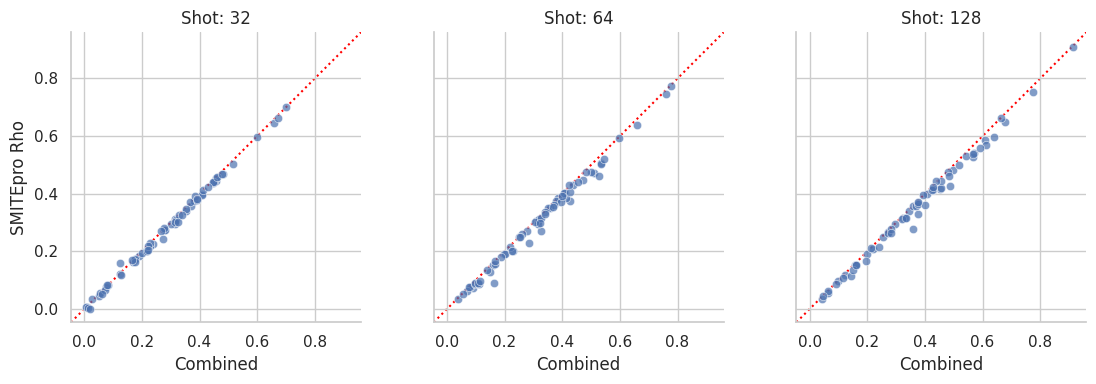

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extract SMITEpro scores
smite_df = (long_df[long_df['method'] == 'SMITEpro']
            [['system', 'train_size', 'rho']]
            .rename(columns={'rho': 'SMITEpro_rho'}))

# 2. Extract Combined scores
combined_df = (long_df[long_df['method'] == 'Combined']
             [['system', 'train_size', 'rho']]
             .rename(columns={'rho': 'Combined_rho'}))

# 3. Create a clean join column by removing the shot number
smite_df['join_key'] = smite_df['system'].str.split('_shot').str[0]
combined_df['join_key'] = combined_df['system'].str.split('_shot').str[0]
# evolve_df['join_key'] = evolve_df['system'].str.split('_shot').str[0]

# 4. Merge using the new join key and train_size
merged_df = pd.merge(smite_df, combined_df, on=['join_key', 'train_size'], how='inner')

# 5. Create the paneled scatterplots
g = sns.relplot(
    data=merged_df,
    x='Combined_rho',
    y='SMITEpro_rho',
    col='train_size',
    col_wrap=3,
    kind='scatter',
    alpha=0.7,
    height=4
)

for ax in g.axes.flat:
    ax.axline((0, 0), slope=1, color='red', linestyle=':', zorder=0)
    
    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect('equal')

g.set_axis_labels("Combined", "SMITEpro Rho")
g.set_titles("Shot: {col_name}")

plt.tight_layout()
plt.show()


Matched comparison: 107 assays; 5100 assay/shot/metric/budget combinations. Replicate values are averaged per assay.
Ensemble2 retained in evaluations, omitted from the grid figure.
Cached per-K zero-shot evaluation: 425 held-out tables; 88.5 seconds before plotting. No model inference.


train_size             16   32   64   128
metric             N                     
Enrichment Factor  10  107  106  106  106
                   20  107  106  106  106
                   30  107  106  106  106
                   40  107  106  106  106
Mean Top-N Fitness 10  107  106  106  106
                   20  107  106  106  106
                   30  107  106  106  106
                   40  107  106  106  106
Top 1% Precision   10  107  106  106  106
                   20  107  106  106  106
                   30  107  106  106  106
                   40  107  106  106  106

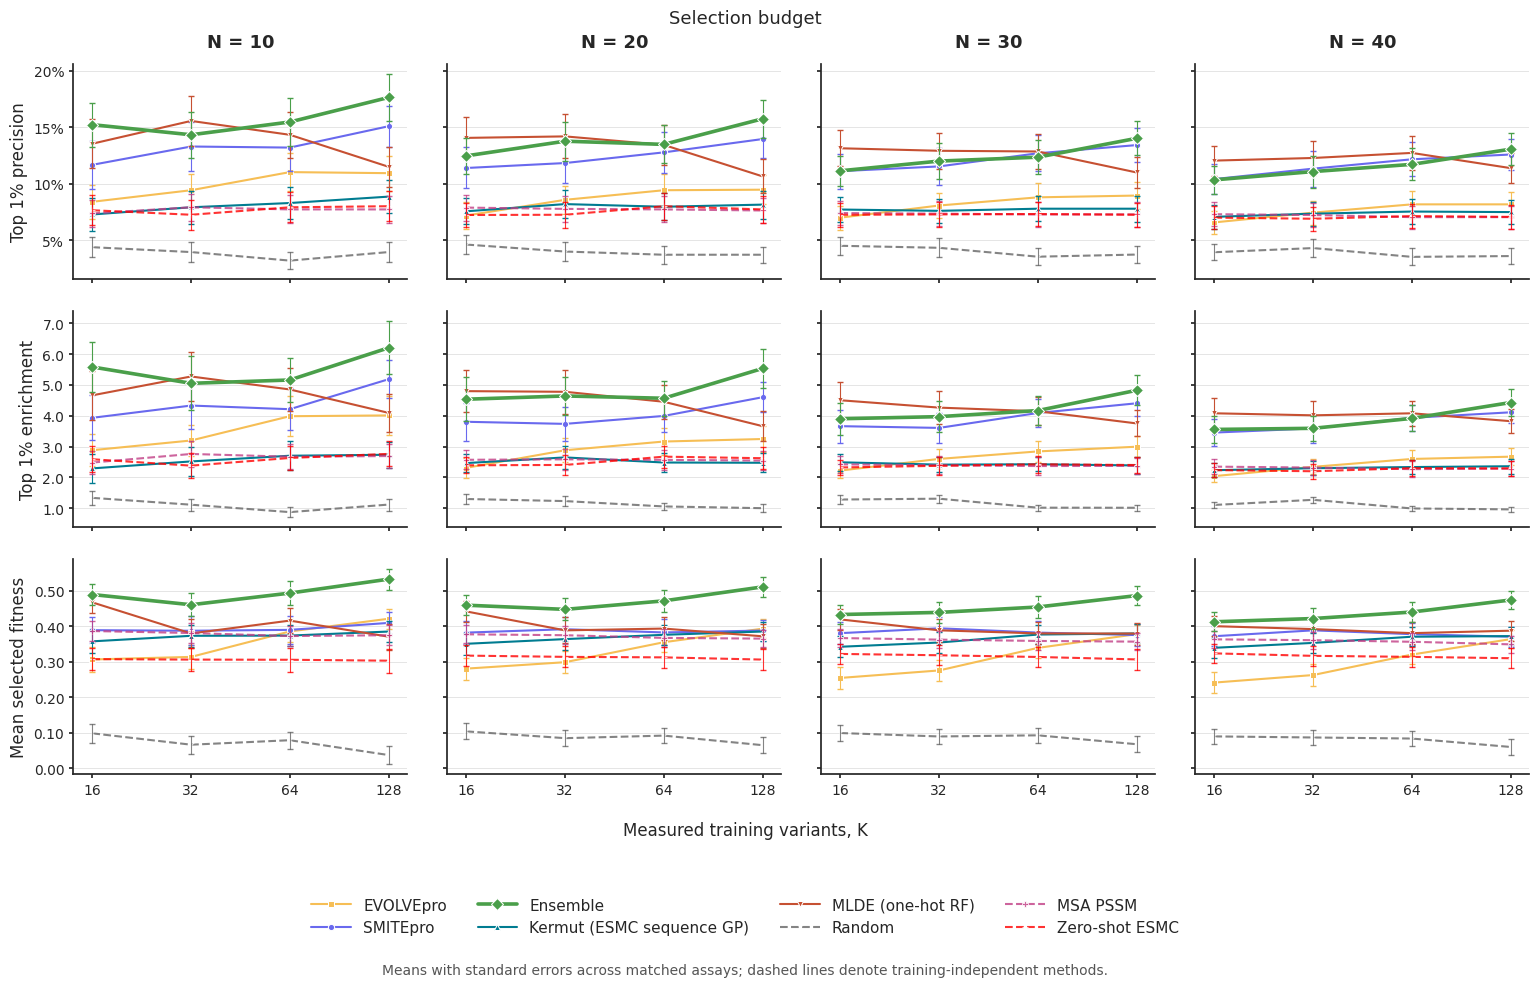

In [ ]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

comparison_started = perf_counter()
workspace_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'baselines/new_benchmark_evaluation_metrics.csv').is_file()
)
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))
from baselines.metrics import evaluate
from baselines.ensembles import evaluate_ensemble2

historical_directory = workspace_root / 'proteinGym/singleMutant/2026-02-27_softSqLoss_16batch_1e-3_cosineannealing_PEFT'
historical_metrics = pd.read_csv(historical_directory / 'evaluation_metrics_combined.csv')
external_metrics = pd.read_csv(workspace_root / 'baselines/new_benchmark_evaluation_metrics.csv')

comparison_metrics = ['Top 1% Precision', 'Enrichment Factor', 'Mean Top-N Fitness']
comparison_budgets = [10, 20, 30, 40]
comparison_shots = [16, 32, 64, 128]
comparison_methods = [
    'EVOLVEpro', 'SMITEpro', 'Ensemble', 'Ensemble2', 'Kermut ESMC Sequence GP',
    'MLDE One-Hot RF', 'Random', 'MSA PSSM'
]
comparison_colors = {
    'EVOLVEpro': '#F6BE55', 'SMITEpro': '#6969EE', 'Ensemble': '#4A9F4A',
    'Ensemble2': '#161616',
    'Kermut ESMC Sequence GP': '#007C91', 'MLDE One-Hot RF': '#C65032',
    'Random': '#666666', 'MSA PSSM': '#C13D85', 'Zero-Shot ESM': 'red'
}
untrained_methods = {'Random', 'MSA PSSM', 'Zero-Shot ESM'}

ensemble2_archive = workspace_root / 'baselines/cache/transfer/smitepro_mlde_seed101_per_mutant_20261010.zip'
ensemble2_metrics = evaluate_ensemble2(
    ensemble2_archive, historical_directory, budgets=comparison_budgets, min_sites=100
)
ensemble2_metrics.to_csv(workspace_root / 'baselines/ensemble2_evaluation_metrics.csv', index=False)

for flag in ['smoke_test', 'synthetic_resources']:
    if flag in external_metrics:
        external_metrics = external_metrics.loc[
            ~external_metrics[flag].astype(str).str.lower().isin(['true', '1'])
        ].copy()
if 'budget_supported' in external_metrics:
    external_metrics = external_metrics.loc[
        external_metrics['budget_supported'].astype(str).str.lower().isin(['true', '1'])
    ].copy()

for frame in [historical_metrics, external_metrics, ensemble2_metrics]:
    frame['method'] = frame['method'].replace({'Combined': 'Ensemble'})
    frame['assay'] = frame['system'].str.replace(r'_final_predictions_shot\d+$', '', regex=True)

combined_metrics = pd.concat([historical_metrics, external_metrics, ensemble2_metrics], ignore_index=True)
combined_metrics = combined_metrics.loc[
    combined_metrics['num_sites'].ge(100)
    & combined_metrics['metric'].isin(comparison_metrics)
    & combined_metrics['N'].isin(comparison_budgets)
    & np.isfinite(combined_metrics['value'])
].copy()
model_metrics = combined_metrics.loc[
    combined_metrics['method'].isin(comparison_methods)
    & combined_metrics['train_size'].isin(comparison_shots)
].copy()
comparison_keys = ['assay', 'train_size', 'metric', 'N']
assay_means = model_metrics.groupby(comparison_keys + ['method'], as_index=False)['value'].mean()
method_coverage = assay_means.groupby(comparison_keys)['method'].nunique()
shared_keys = method_coverage.loc[method_coverage.eq(len(comparison_methods))].reset_index()[comparison_keys]
matched_metrics = assay_means.merge(shared_keys, on=comparison_keys, how='inner', validate='many_to_one')
if matched_metrics.empty:
    raise ValueError('No matched assay/shot panels contain all methods after filtering.')

zero_shot_records = []
for assay, shots in shared_keys[['assay', 'train_size']].drop_duplicates().itertuples(index=False, name=None):
    prediction_path = historical_directory / f'{assay}_final_predictions_shot{int(shots)}.csv'
    predictions = pd.read_csv(
        prediction_path, usecols=lambda column: column in {'mutant', 'target', 'delta_esm', 'is_train'}
    )
    if 'is_train' in predictions:
        training_mask = predictions['is_train'].astype(str).str.lower()
        if not training_mask.isin(['true', 'false', '1', '0']).all():
            raise ValueError(f'Invalid training flags in {prediction_path.name}')
        predictions = predictions.loc[~training_mask.isin(['true', '1'])].copy()
    if predictions.empty or predictions['mutant'].duplicated().any():
        raise ValueError(f'Empty or duplicate held-out variants in {prediction_path.name}')
    if not np.isfinite(predictions[['target', 'delta_esm']].to_numpy()).all():
        raise ValueError(f'Missing/nonfinite cached zero-shot scores in {prediction_path.name}')
    predictions = predictions.rename(columns={'delta_esm': 'pred_score'})
    evaluated = evaluate(predictions, assay, int(shots), 'Zero-Shot ESM', budgets=comparison_budgets)
    evaluated['assay'] = assay
    zero_shot_records.append(evaluated)

zero_shot_metrics = pd.concat(zero_shot_records, ignore_index=True)
zero_shot_metrics = zero_shot_metrics.loc[
    zero_shot_metrics['metric'].isin(comparison_metrics)
    & zero_shot_metrics['budget_supported']
    & np.isfinite(zero_shot_metrics['value'])
]
zero_shot_metrics = shared_keys.merge(
    zero_shot_metrics, on=comparison_keys, how='left', validate='one_to_one'
)
if zero_shot_metrics['value'].isna().any():
    raise ValueError('Zero-shot evaluation does not cover every matched panel.')
matched_metrics = pd.concat([matched_metrics, zero_shot_metrics], ignore_index=True)
plot_method_order = comparison_methods + ['Zero-Shot ESM']
assert matched_metrics.groupby(comparison_keys)['method'].nunique().eq(len(plot_method_order)).all()
print(f'Matched comparison: {matched_metrics.assay.nunique()} assays; '
      f'{len(shared_keys)} assay/shot/metric/budget combinations. Replicate values are averaged per assay.')
print('Ensemble2 retained in evaluations, omitted from the grid figure.')
print(f'Cached per-K zero-shot evaluation: {len(zero_shot_records)} held-out tables; '
      f'{perf_counter() - comparison_started:.1f} seconds before plotting. No model inference.')
display(matched_metrics.groupby(['metric', 'N', 'train_size'])['assay'].nunique().unstack('train_size'))

display_method_order = [method for method in plot_method_order if method != 'Ensemble2']
method_labels = {
    'Kermut ESMC Sequence GP': 'Kermut (ESMC sequence GP)',
    'MLDE One-Hot RF': 'MLDE (one-hot RF)',
    'Zero-Shot ESM': 'Zero-shot ESMC',
}
method_markers = {
    'EVOLVEpro': 's', 'SMITEpro': 'o', 'Ensemble': 'D',
    'Kermut ESMC Sequence GP': '^', 'MLDE One-Hot RF': 'v',
    'Random': 'x', 'MSA PSSM': 'P', 'Zero-Shot ESM': '+',
}
row_labels = ['Top 1% precision', 'Top 1% enrichment', 'Mean selected fitness']
sns.set_theme(style='ticks', context='notebook')
comparison_figure, comparison_axes = plt.subplots(
    3, 4, figsize=(16, 10), sharex=True, sharey='row'
)
legend_handles = {}
draw_order = [method for method in display_method_order if method != 'Ensemble'] + ['Ensemble']
for row_index, metric in enumerate(comparison_metrics):
    for column_index, budget in enumerate(comparison_budgets):
        axis = comparison_axes[row_index, column_index]
        panel = matched_metrics.loc[matched_metrics['metric'].eq(metric) & matched_metrics['N'].eq(budget)]
        for method in draw_order:
            method_panel = panel.loc[panel['method'].eq(method)]
            if not method_panel.empty:
                is_reference = method in untrained_methods
                is_ensemble = method == 'Ensemble'
                sns.lineplot(
                    data=method_panel, x='train_size', y='value',
                    color=comparison_colors[method], label=method,
                    linestyle='--' if is_reference else '-',
                    errorbar='se', marker=method_markers[method], err_style='bars',
                    linewidth=2.6 if is_ensemble else 1.5,
                    markersize=6 if is_ensemble else 4.5,
                    alpha=0.8 if is_reference else 1.0,
                    zorder=5 if is_ensemble else 2,
                    err_kws={'elinewidth': 0.8, 'capsize': 2}, ax=axis,
                )
        handles, labels = axis.get_legend_handles_labels()
        legend_handles.update(dict(zip(labels, handles)))
        if axis.get_legend() is not None:
            axis.get_legend().remove()
        axis.set_xscale('log', base=2)
        axis.set_xticks(comparison_shots, labels=[str(shots) for shots in comparison_shots])
        axis.set_xlim(14, 146)
        axis.xaxis.set_minor_locator(mtick.NullLocator())
        axis.set_xlabel('')
        axis.set_ylabel(row_labels[row_index] if column_index == 0 else '', fontsize=12)
        if row_index == 0:
            axis.set_title(f'N = {budget}', fontsize=13, fontweight='bold', pad=12)
        axis.tick_params(axis='both', labelsize=10, length=3)
        axis.grid(axis='y', color='#e5e5e5', linewidth=0.7)
        axis.grid(axis='x', visible=False)
        if metric == 'Top 1% Precision':
            axis.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
        elif metric == 'Enrichment Factor':
            axis.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f'))
        else:
            axis.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
        sns.despine(ax=axis)
        assert {label for label in labels} == set(display_method_order)

comparison_figure.suptitle('Selection budget', fontsize=13, y=0.985)
comparison_figure.supxlabel('Measured training variants, K', fontsize=12, y=0.155)
comparison_figure.legend(
    [legend_handles[method] for method in display_method_order],
    [method_labels.get(method, method) for method in display_method_order],
    loc='lower center', bbox_to_anchor=(0.5, 0.045), ncol=4,
    frameon=False, fontsize=11, columnspacing=2.0, handlelength=2.6,
)
comparison_figure.text(
    0.5, 0.02, 'Means with standard errors across matched assays; dashed lines denote training-independent methods.',
    ha='center', fontsize=10, color='#555555',
)
comparison_figure.subplots_adjust(left=0.08, right=0.99, top=0.93, bottom=0.22, hspace=0.15, wspace=0.12)
assert 'Ensemble2' not in legend_handles
assert len(comparison_figure.axes) == 12
plt.show()

Ensemble3: equal mean of independently min-max-scaled SMITEpro, EVOLVEpro, and MLDE scores.
Validated 5100 existing matched metric panels; no model inference.


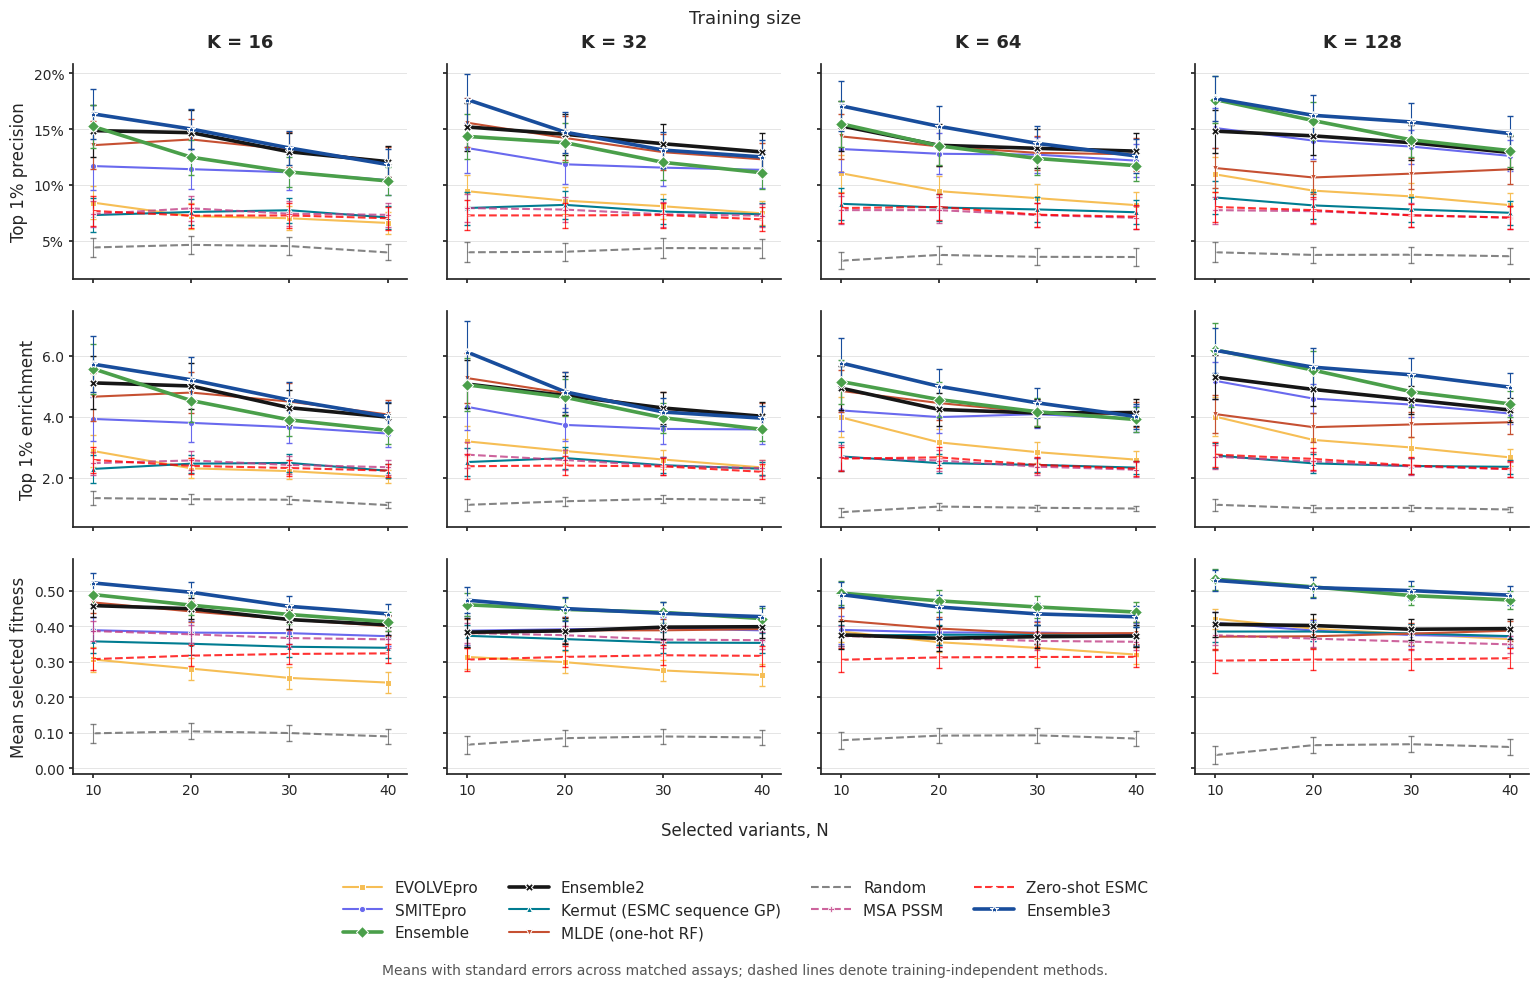

In [ ]:
import importlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import baselines.ensembles as ensemble_evaluation

if 'matched_metrics' not in globals() or 'display_method_order' not in globals():
    raise RuntimeError('Run Cell 24 first to load the matched comparison data and plotting styles.')

importlib.reload(ensemble_evaluation)
ensemble3_metrics = ensemble_evaluation.evaluate_ensemble3(
    ensemble2_archive, historical_directory, budgets=comparison_budgets, min_sites=100,
)
ensemble3_metrics['assay'] = ensemble3_metrics['system'].str.replace(
    r'_final_predictions_shot\d+$', '', regex=True,
)
ensemble3_panel_metrics = ensemble3_metrics.loc[
    ensemble3_metrics['metric'].isin(comparison_metrics)
    & ensemble3_metrics['budget_supported']
].copy()
ensemble3_matched = shared_keys.merge(
    ensemble3_panel_metrics, on=comparison_keys, how='left', validate='one_to_one',
)
if not np.isfinite(ensemble3_matched['value'].to_numpy()).all():
    raise ValueError('Ensemble3 does not cover every existing matched assay/K/N/metric panel.')
assert ensemble3_matched['method'].eq('Ensemble3').all()
ensemble3_metrics.to_csv(workspace_root / 'baselines/ensemble3_evaluation_metrics.csv', index=False)
budget_plot_metrics = pd.concat([matched_metrics, ensemble3_matched], ignore_index=True)
budget_display_methods = list(plot_method_order) + ['Ensemble3']
assert not budget_plot_metrics.duplicated(comparison_keys + ['method']).any()
assert budget_plot_metrics.groupby(comparison_keys)['method'].nunique().eq(len(budget_display_methods)).all()
budget_colors = {**comparison_colors, 'Ensemble3': '#184D9C'}
budget_markers = {**method_markers, 'Ensemble2': 'X', 'Ensemble3': '*'}
budget_draw_order = [method for method in budget_display_methods if method not in {'Ensemble', 'Ensemble2', 'Ensemble3'}]
budget_draw_order += ['Ensemble2', 'Ensemble', 'Ensemble3']
print('Ensemble3: equal mean of independently min-max-scaled SMITEpro, EVOLVEpro, and MLDE scores.')
print(f'Validated {len(ensemble3_matched)} existing matched metric panels; no model inference.')
sns.set_theme(style='ticks', context='notebook')
budget_figure, budget_axes = plt.subplots(
    len(comparison_metrics), len(comparison_shots), figsize=(16, 10),
    sharex=True, sharey='row', squeeze=False,
)
budget_legend_handles = {}
for metric_index, budget_metric in enumerate(comparison_metrics):
    for shot_index, training_size in enumerate(comparison_shots):
        budget_axis = budget_axes[metric_index, shot_index]
        budget_panel = budget_plot_metrics.loc[
            budget_plot_metrics['metric'].eq(budget_metric)
            & budget_plot_metrics['train_size'].eq(training_size)
            & budget_plot_metrics['N'].isin(comparison_budgets)
        ]
        for budget_method in budget_draw_order:
            budget_method_panel = budget_panel.loc[budget_panel['method'].eq(budget_method)]
            if budget_method_panel.empty:
                raise ValueError(f'Missing plot data for {budget_method}, K={training_size}, {budget_metric}')
            budget_reference = budget_method in untrained_methods
            budget_ensemble = budget_method in {'Ensemble', 'Ensemble2', 'Ensemble3'}
            sns.lineplot(
                data=budget_method_panel, x='N', y='value',
                color=budget_colors[budget_method], label=budget_method,
                linestyle='--' if budget_reference else '-',
                errorbar='se', marker=budget_markers[budget_method], err_style='bars',
                linewidth=2.6 if budget_ensemble else 1.5,
                markersize=6 if budget_ensemble else 4.5,
                alpha=0.8 if budget_reference else 1.0,
                zorder=5 if budget_ensemble else 2,
                err_kws={'elinewidth': 0.8, 'capsize': 2}, ax=budget_axis,
            )
        budget_handles, budget_labels = budget_axis.get_legend_handles_labels()
        budget_legend_handles.update(dict(zip(budget_labels, budget_handles)))
        if budget_axis.get_legend() is not None:
            budget_axis.get_legend().remove()
        budget_axis.set_xticks(comparison_budgets)
        budget_axis.set_xlim(8, 42)
        budget_axis.xaxis.set_minor_locator(mtick.NullLocator())
        budget_axis.set_xlabel('')
        budget_axis.set_ylabel(row_labels[metric_index] if shot_index == 0 else '', fontsize=12)
        if metric_index == 0:
            budget_axis.set_title(f'K = {training_size}', fontsize=13, fontweight='bold', pad=12)
        budget_axis.tick_params(axis='both', labelsize=10, length=3)
        budget_axis.grid(axis='y', color='#e5e5e5', linewidth=0.7)
        budget_axis.grid(axis='x', visible=False)
        if budget_metric == 'Top 1% Precision':
            budget_axis.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
        elif budget_metric == 'Enrichment Factor':
            budget_axis.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f'))
        else:
            budget_axis.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.2f'))
        sns.despine(ax=budget_axis)
        assert set(budget_labels) == set(budget_display_methods)

budget_figure.suptitle('Training size', fontsize=13, y=0.985)
budget_figure.supxlabel('Selected variants, N', fontsize=12, y=0.155)
budget_figure.legend(
    [budget_legend_handles[budget_method] for budget_method in budget_display_methods],
    [method_labels.get(budget_method, budget_method) for budget_method in budget_display_methods],
    loc='lower center', bbox_to_anchor=(0.5, 0.04), ncol=4,
    frameon=False, fontsize=11, columnspacing=2.0, handlelength=2.6,
)
budget_figure.text(
    0.5, 0.02, 'Means with standard errors across matched assays; dashed lines denote training-independent methods.',
    ha='center', fontsize=10, color='#555555',
)
budget_figure.subplots_adjust(left=0.08, right=0.99, top=0.93, bottom=0.22, hspace=0.15, wspace=0.12)
assert {'Ensemble2', 'Ensemble3'}.issubset(budget_legend_handles)
assert not {'Ensemble2', 'Ensemble3'}.intersection(display_method_order)
assert 'Ensemble3' not in set(matched_metrics['method'])
assert len(budget_figure.axes) == len(comparison_metrics) * len(comparison_shots)
budget_export_directory = workspace_root / 'manuscript/figures'
budget_export_directory.mkdir(parents=True, exist_ok=True)
for budget_export_extension in ('png', 'pdf'):
    budget_figure.savefig(
        budget_export_directory / f'benchmark_curves_all_ensembles.{budget_export_extension}',
        dpi=300, bbox_inches='tight',
    )
plt.show()

106 complete assays; 16 K/N panels per assay; 10 models.
Each assay/K/N matchup has equal weight. Heatmaps show strict row-model wins, not score differences.
Ties (absolute score difference <= 1e-10) count as neither wins nor losses; CSVs report all three percentages.
Descriptive results only; no significance claims or new experimental validation.


,method,model,assays,matchups_per_opponent,mean_top_n_fitness,mean_pairwise_win_pct,mean_pairwise_tie_pct
0,Ensemble3,Ensemble3: SMITEpro + EVOLVEpro + MLDE (one-ho...,106,1696,0.4704,67.0401,0.8058
1,Ensemble,Ensemble: SMITEpro + EVOLVEpro,106,1696,0.4641,65.3629,0.7469
2,Ensemble2,Ensemble2: SMITEpro + MLDE (one-hot RF),106,1696,0.3983,52.7450,1.6444
3,MLDE One-Hot RF,MLDE (one-hot RF),106,1696,0.3975,55.3459,0.4455
4,SMITEpro,SMITEpro,106,1696,0.3848,50.3865,1.5658
5,MSA PSSM,MSA PSSM,106,1696,0.3668,48.2377,0.0459
6,Kermut ESMC Sequence GP,Kermut (ESMC sequence GP),106,1696,0.3650,54.0618,0.3538
7,EVOLVEpro,EVOLVEpro,106,1696,0.3240,42.7804,0.2358
8,Zero-Shot ESM,Zero-shot ESMC,106,1696,0.3114,47.9101,0.3538
9,Random,Random,106,1696,0.0808,13.0307,0.0000


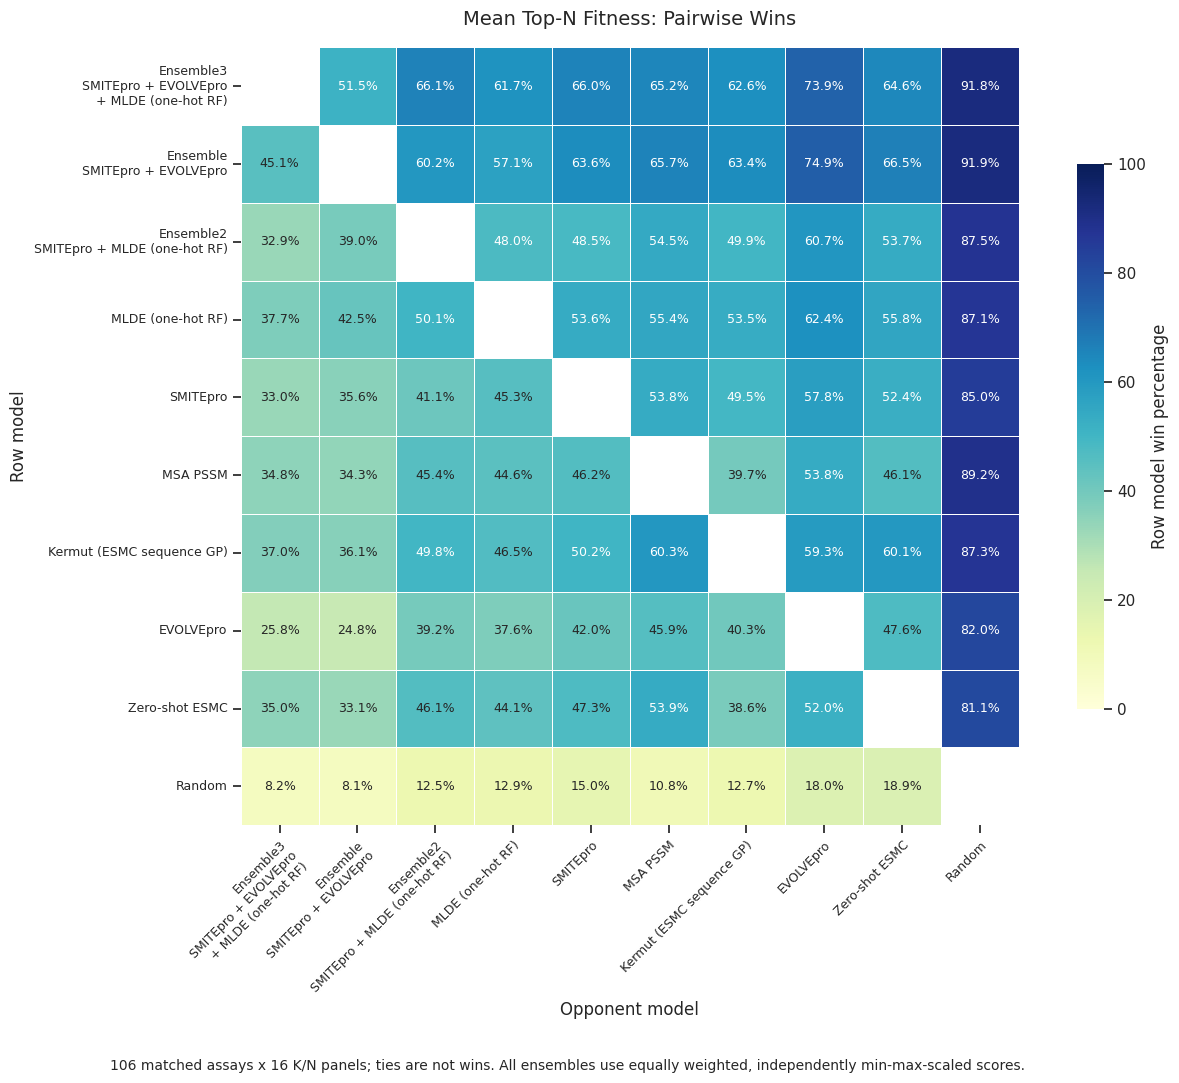

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if 'budget_plot_metrics' not in globals() or 'ensemble3_matched' not in globals():
    raise RuntimeError('Run Cells 24 and 25 first to load all methods, including the triple ensemble.')

head_to_head_methods = list(budget_display_methods)
head_to_head_keys = ['assay', 'train_size', 'N']
head_to_head_labels = {
    **method_labels,
    'Ensemble': 'Ensemble: SMITEpro + EVOLVEpro',
    'Ensemble2': 'Ensemble2: SMITEpro + MLDE (one-hot RF)',
    'Ensemble3': 'Ensemble3: SMITEpro + EVOLVEpro + MLDE (one-hot RF)',
}
heatmap_method_labels = {
    **head_to_head_labels,
    'Ensemble': 'Ensemble\nSMITEpro + EVOLVEpro',
    'Ensemble2': 'Ensemble2\nSMITEpro + MLDE (one-hot RF)',
    'Ensemble3': 'Ensemble3\nSMITEpro + EVOLVEpro\n+ MLDE (one-hot RF)',
}
expected_panels = pd.MultiIndex.from_product(
    [comparison_shots, comparison_budgets], names=['train_size', 'N'],
)
head_to_head_metric_frames = {}
complete_metric_assays = []
for score_metric in ['Mean Top-N Fitness', 'Top 1% Precision']:
    score_long = budget_plot_metrics.loc[budget_plot_metrics['metric'].eq(score_metric)]
    if score_long.duplicated(head_to_head_keys + ['method']).any():
        raise ValueError('Expected one replicate-averaged score per assay/K/N/method.')
    score_wide = score_long.pivot(index=head_to_head_keys, columns='method', values='value')
    score_wide = score_wide.reindex(columns=head_to_head_methods)
    metric_assays = []
    for assay_name, assay_panel in score_wide.groupby(level='assay'):
        assay_panel = assay_panel.droplevel('assay').reindex(expected_panels)
        if np.isfinite(assay_panel.to_numpy()).all():
            metric_assays.append(assay_name)
    complete_metric_assays.append(set(metric_assays))
    head_to_head_metric_frames[score_metric] = score_wide
complete_assays = sorted(set.intersection(*complete_metric_assays))
if len(complete_assays) < 2:
    raise ValueError('Need at least two assays covering every K/N/method in both metrics.')
for score_metric, score_wide in head_to_head_metric_frames.items():
    head_to_head_metric_frames[score_metric] = score_wide.loc[
        score_wide.index.get_level_values('assay').isin(complete_assays)
    ].sort_index()
    assert len(head_to_head_metric_frames[score_metric]) == len(complete_assays) * len(expected_panels)
assert head_to_head_metric_frames['Mean Top-N Fitness'].index.equals(
    head_to_head_metric_frames['Top 1% Precision'].index,
)
tie_tolerance = 1e-10


def pairwise_win_percentages(values, tolerance=tie_tolerance):
    differences = values[:, :, None] - values[:, None, :]
    win_pct = 100 * (differences > tolerance).mean(axis=0)
    tie_pct = 100 * (np.abs(differences) <= tolerance).mean(axis=0)
    assert np.allclose(win_pct + win_pct.T + tie_pct, 100)
    return win_pct, tie_pct


probe_wins, probe_ties = pairwise_win_percentages(np.array([[2.0, 1.0], [1.0, 2.0], [1.0, 1.0]]))
assert np.isclose(probe_wins[0, 1], 100 / 3)
assert np.isclose(probe_ties[0, 1], 100 / 3)


def show_pairwise_win_heatmap(score_metric, output_prefix, raw_score_column, score_scale=1.0):
    score_wide = head_to_head_metric_frames[score_metric]
    raw_means = score_wide.groupby(level='assay').mean().mean().sort_values(ascending=False)
    ordered_methods = list(raw_means.index)
    score_wide = score_wide.reindex(columns=ordered_methods)
    win_pct, tie_pct = pairwise_win_percentages(score_wide.to_numpy())
    off_diagonal = ~np.eye(len(ordered_methods), dtype=bool)
    leaderboard = pd.DataFrame({
        'method': ordered_methods,
        'model': [head_to_head_labels.get(method, method) for method in ordered_methods],
        'assays': len(complete_assays),
        'matchups_per_opponent': len(score_wide),
        raw_score_column: score_scale * raw_means.to_numpy(),
        'mean_pairwise_win_pct': win_pct.sum(axis=1) / (len(ordered_methods) - 1),
        'mean_pairwise_tie_pct': (tie_pct * off_diagonal).sum(axis=1) / (len(ordered_methods) - 1),
    })
    pair_records = []
    for row_index, row_method in enumerate(ordered_methods):
        for column_index, column_method in enumerate(ordered_methods):
            if row_method == column_method:
                continue
            pair_records.append({
                'metric': score_metric,
                'row_method': row_method, 'row_model': head_to_head_labels.get(row_method, row_method),
                'column_method': column_method, 'column_model': head_to_head_labels.get(column_method, column_method),
                'assays': len(complete_assays), 'matchups': len(score_wide),
                'row_win_pct': win_pct[row_index, column_index],
                'tie_pct': tie_pct[row_index, column_index],
                'row_loss_pct': win_pct[column_index, row_index],
            })
    pair_table = pd.DataFrame(pair_records)
    assert np.allclose(pair_table[['row_win_pct', 'tie_pct', 'row_loss_pct']].sum(axis=1), 100)
    display(leaderboard.round(4))
    leaderboard.to_csv(historical_directory / f'{output_prefix}_all_models_raw_scores.csv', index=False)
    pair_table.to_csv(historical_directory / f'{output_prefix}_all_models_pairwise_win_percentages.csv', index=False)
    plot_labels = [heatmap_method_labels.get(method, method) for method in ordered_methods]
    heatmap_data = pd.DataFrame(win_pct, index=plot_labels, columns=plot_labels)
    annotations = np.array([[f'{value:.1f}%' for value in row] for row in win_pct])
    figure, axis = plt.subplots(figsize=(14, 11))
    sns.heatmap(
        heatmap_data, mask=~off_diagonal, annot=annotations, fmt='',
        cmap='YlGnBu', vmin=0, vmax=100, linewidths=0.5, square=True,
        annot_kws={'fontsize': 9}, ax=axis,
        cbar_kws={'label': 'Row model win percentage', 'shrink': 0.7},
    )
    axis.set_title(f'{score_metric}: Pairwise Wins', fontsize=14, pad=16)
    axis.set_xlabel('Opponent model', fontsize=12)
    axis.set_ylabel('Row model', fontsize=12)
    axis.tick_params(axis='x', labelsize=9)
    axis.tick_params(axis='y', rotation=0, labelsize=9)
    plt.setp(axis.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    figure.text(
        0.5, 0.02,
        f'{len(complete_assays)} matched assays x {len(expected_panels)} K/N panels; ties are not wins. '
        'All ensembles use equally weighted, independently min-max-scaled scores.',
        ha='center', fontsize=10,
    )
    figure.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()
    return leaderboard, pair_table


print(f'{len(complete_assays)} complete assays; {len(expected_panels)} K/N panels per assay; 10 models.')
print('Each assay/K/N matchup has equal weight. Heatmaps show strict row-model wins, not score differences.')
print('Ties (absolute score difference <= 1e-10) count as neither wins nor losses; CSVs report all three percentages.')
print('Descriptive results only; no significance claims or new experimental validation.')
fitness_leaderboard, fitness_pairwise_wins = show_pairwise_win_heatmap(
    'Mean Top-N Fitness', 'mean_top_n', 'mean_top_n_fitness',
)

Top 1% Precision: 106 complete assays; 16 K/N panels each.
Precision = fraction of selected N variants in the held-out assay top 1%, including threshold ties.
Same assays, panels, models, and strict-win convention as Cell 26; ties are reported separately.
Raw mean precision is shown in percent. Heatmap values are pairwise win percentages, not precision differences.
Descriptive results only; no significance claims or new experimental validation.


,method,model,assays,matchups_per_opponent,mean_top_1pct_precision_pct,mean_pairwise_win_pct,mean_pairwise_tie_pct
0,Ensemble3,Ensemble3: SMITEpro + EVOLVEpro + MLDE (one-ho...,106,1696,14.8433,48.3884,29.6777
1,Ensemble2,Ensemble2: SMITEpro + MLDE (one-hot RF),106,1696,13.8886,41.9222,30.9552
2,Ensemble,Ensemble: SMITEpro + EVOLVEpro,106,1696,13.3825,44.8048,28.6950
3,MLDE One-Hot RF,MLDE (one-hot RF),106,1696,12.8778,40.8477,29.2649
4,SMITEpro,SMITEpro,106,1696,12.4263,39.4327,29.8611
5,EVOLVEpro,EVOLVEpro,106,1696,8.6046,31.9313,27.0833
6,Kermut ESMC Sequence GP,Kermut (ESMC sequence GP),106,1696,7.7933,30.6866,28.7736
7,MSA PSSM,MSA PSSM,106,1696,7.4990,32.6389,24.2400
8,Zero-Shot ESM,Zero-shot ESMC,106,1696,7.3939,30.2869,28.1316
9,Random,Random,106,1696,3.9431,18.1276,25.1834


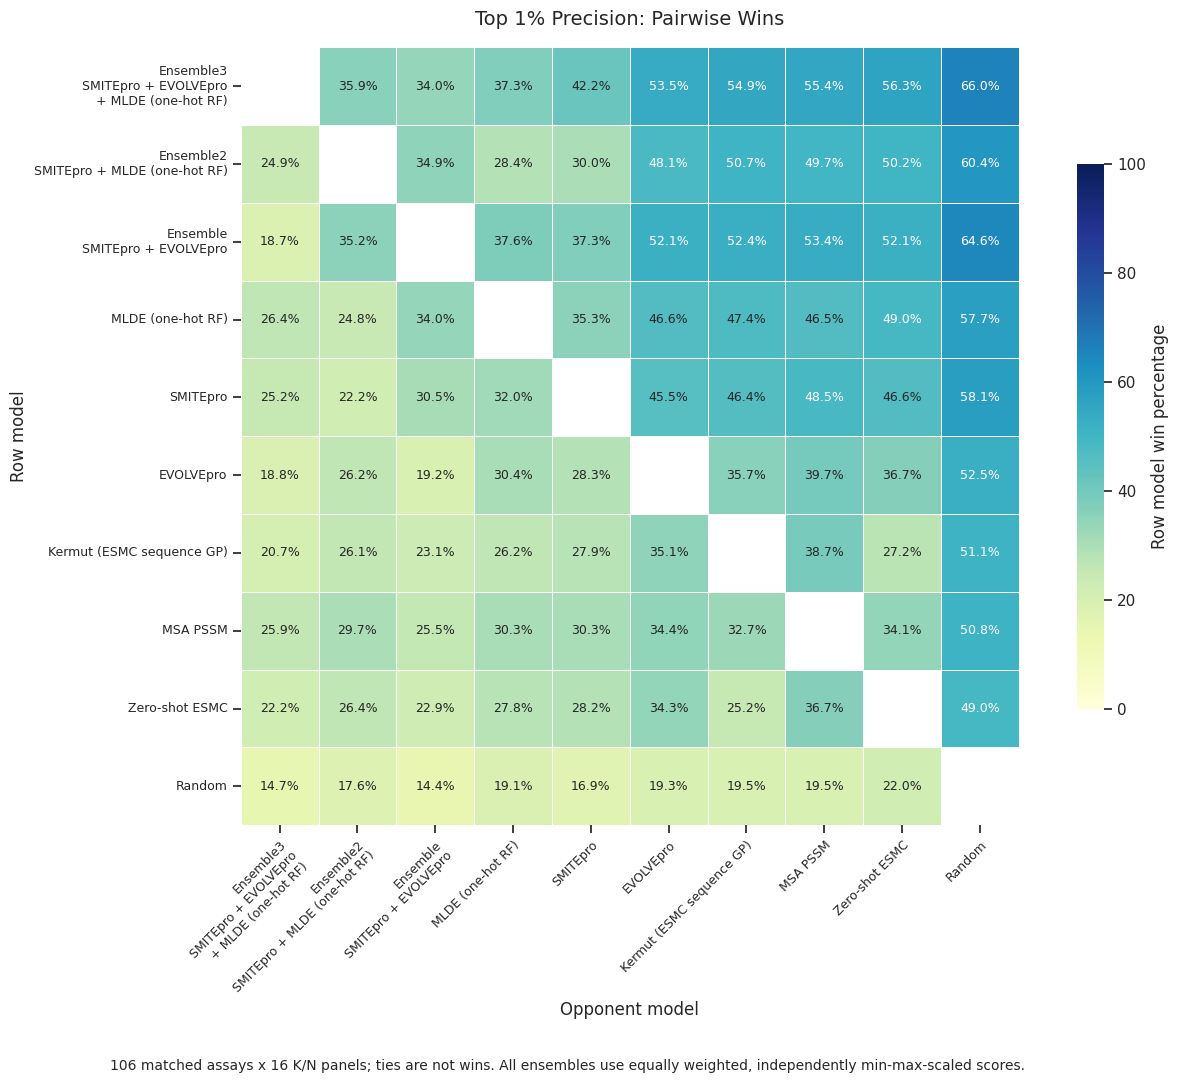

In [ ]:
if 'show_pairwise_win_heatmap' not in globals() or 'head_to_head_metric_frames' not in globals():
    raise RuntimeError('Run Cells 24, 25, and 26 first to build the ten-model matched comparison.')

precision_scores = head_to_head_metric_frames['Top 1% Precision']
assert ((precision_scores >= 0) & (precision_scores <= 1)).to_numpy().all()
print(f'Top 1% Precision: {len(complete_assays)} complete assays; {len(expected_panels)} K/N panels each.')
print('Precision = fraction of selected N variants in the held-out assay top 1%, including threshold ties.')
print('Same assays, panels, models, and strict-win convention as Cell 26; ties are reported separately.')
print('Raw mean precision is shown in percent. Heatmap values are pairwise win percentages, not precision differences.')
print('Descriptive results only; no significance claims or new experimental validation.')
top1_leaderboard, top1_pairwise_wins = show_pairwise_win_heatmap(
    'Top 1% Precision', 'top_1pct_precision', 'mean_top_1pct_precision_pct', score_scale=100.0,
)

In [ ]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
import io
import numpy as np
import pandas as pd

if 'head_to_head_metric_frames' not in globals():
    raise RuntimeError('Run Cells 24-26 first to load the matched benchmark scores.')

hpab_fasta_path = workspace_root / 'internal_data/Dan_data/round1/HpaBC Data/Fastas/HpaB_WT.fasta'
hpab_sequence = ''.join(
    line.strip() for line in hpab_fasta_path.read_text().splitlines() if not line.startswith('>')
)
hpab_length = len(hpab_sequence)
hpab_training = pd.read_csv(
    workspace_root / 'internal_data/Dan_data/round2/hpab_data2_enumerated.csv', usecols=['wt_sequence'],
)
assert hpab_length == 520
assert hpab_training['wt_sequence'].str.len().eq(hpab_length).all()
hpab_length_bounds = (int(np.ceil(0.8 * hpab_length)), int(np.floor(1.2 * hpab_length)))

pg_metadata_path = historical_directory / 'hpab_proteingym_metadata_snapshot.csv'
pg_provenance_path = historical_directory / 'hpab_proteingym_metadata_provenance.json'
if not pg_metadata_path.exists():
    with urlopen('https://api.github.com/repos/OATML-Markslab/ProteinGym/commits/main', timeout=30) as response:
        pg_commit = json.load(response)['sha']
    pg_metadata_url = (
        f'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/{pg_commit}/reference_files/DMS_substitutions.csv'
    )
    with urlopen(pg_metadata_url, timeout=30) as response:
        pg_metadata_bytes = response.read()
    pg_metadata = pd.read_csv(io.BytesIO(pg_metadata_bytes))
    required_pg_columns = {'DMS_id', 'UniProt_ID', 'target_seq', 'seq_len', 'coarse_selection_type', 'selection_type', 'selection_assay'}
    assert required_pg_columns.issubset(pg_metadata.columns)
    pg_metadata_path.write_bytes(pg_metadata_bytes)
    pg_provenance_path.write_text(json.dumps({
        'source_url': pg_metadata_url, 'commit': pg_commit,
        'sha256': hashlib.sha256(pg_metadata_bytes).hexdigest(),
        'retrieved_utc': pd.Timestamp.now(tz='UTC').isoformat(),
    }, indent=2) + '\n')
else:
    pg_metadata_bytes = pg_metadata_path.read_bytes()
    pg_metadata = pd.read_csv(io.BytesIO(pg_metadata_bytes))
pg_provenance = json.loads(pg_provenance_path.read_text())
assert hashlib.sha256(pg_metadata_bytes).hexdigest() == pg_provenance['sha256']
assert not pg_metadata['DMS_id'].duplicated().any()

hpab_assay_metadata = pd.DataFrame({'assay': complete_assays}).merge(
    pg_metadata.rename(columns={'DMS_id': 'assay'}), on='assay', how='left', validate='one_to_one', indicator=True,
)
if not hpab_assay_metadata['_merge'].eq('both').all():
    raise ValueError('ProteinGym metadata missing for: ' + ', '.join(
        hpab_assay_metadata.loc[hpab_assay_metadata['_merge'].ne('both'), 'assay']
    ))
assert hpab_assay_metadata[['UniProt_ID', 'target_seq', 'seq_len', 'coarse_selection_type']].notna().all().all()
hpab_assay_metadata['protein_length'] = hpab_assay_metadata['target_seq'].str.len()
assert hpab_assay_metadata['protein_length'].eq(hpab_assay_metadata['seq_len']).all()
hpab_assay_metadata['length_matched'] = hpab_assay_metadata['protein_length'].between(*hpab_length_bounds)
hpab_assay_metadata['activity_primary'] = hpab_assay_metadata['coarse_selection_type'].eq('Activity')
hpab_assay_metadata['activity_explicit_annotation'] = (
    hpab_assay_metadata['activity_primary']
    | hpab_assay_metadata['selection_type'].fillna('').str.contains(r'\bactivity\b', case=False, regex=True) 
)
hpab_cohort_masks = {
    'Length matched': hpab_assay_metadata['length_matched'],
    'Length matched + Activity': hpab_assay_metadata['length_matched'] & hpab_assay_metadata['activity_primary'],
    'Sensitivity: explicit activity annotation': hpab_assay_metadata['length_matched'] & hpab_assay_metadata['activity_explicit_annotation'],
}
hpab_cohort_assays = {
    cohort: sorted(hpab_assay_metadata.loc[mask, 'assay']) for cohort, mask in hpab_cohort_masks.items()
}
assert set(hpab_cohort_assays['Length matched + Activity']).issubset(hpab_cohort_assays['Length matched'])
assert all(hpab_cohort_assays.values())
hpab_metadata_columns = [
    'assay', 'UniProt_ID', 'molecule_name', 'protein_length', 'coarse_selection_type',
    'selection_type', 'selection_assay', 'length_matched', 'activity_primary', 'activity_explicit_annotation',
]
hpab_assay_metadata[hpab_metadata_columns].to_csv(historical_directory / 'hpab_benchmark_assay_eligibility.csv', index=False)
print(f'HpaB: {hpab_length} residues; primary inclusive length window: {hpab_length_bounds[0]}-{hpab_length_bounds[1]} residues.')
print('Primary activity criterion: coarse_selection_type == Activity. Sensitivity adds selection_type containing the word activity.')
print('Length means the full ProteinGym reference sequence, not the number of represented mutation sites.')
print(f'Metadata snapshot: {pg_provenance["source_url"]}; SHA256: {pg_provenance["sha256"]}')
print('Cohorts retain the existing 106 complete benchmark assays and all 16 K/N panels, regardless of outcomes.')
display(pd.DataFrame([
    {'cohort': cohort, 'assays': len(assays),
     'proteins': hpab_assay_metadata.loc[hpab_assay_metadata['assay'].isin(assays), 'UniProt_ID'].nunique()}
    for cohort, assays in hpab_cohort_assays.items()
]))
display(hpab_assay_metadata.loc[hpab_assay_metadata['length_matched'], hpab_metadata_columns].sort_values(['protein_length', 'assay']))
print('Additional explicit-activity annotations excluded by the strict primary category:')
display(hpab_assay_metadata.loc[
    hpab_assay_metadata['length_matched'] & hpab_assay_metadata['activity_explicit_annotation'] & ~hpab_assay_metadata['activity_primary'],
    hpab_metadata_columns,
])

HpaB: 520 residues; primary inclusive length window: 416-624 residues.
Primary activity criterion: coarse_selection_type == Activity. Sensitivity adds selection_type containing the word activity.
Length means the full ProteinGym reference sequence, not the number of represented mutation sites.
Metadata snapshot: https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv; SHA256: a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308
Cohorts retain the existing 106 complete benchmark assays and all 16 K/N panels, regardless of outcomes.


,cohort,assays,proteins
0,Length matched,25,18
1,Length matched + Activity,7,6
2,Sensitivity: explicit activity annotation,9,8


,assay,UniProt_ID,molecule_name,protein_length,coarse_selection_type,selection_type,selection_assay,length_matched,activity_primary,activity_explicit_annotation
47,KCNJ2_MOUSE_Coyote-Maestas_2022_function,KCNJ2_MOUSE,Kir2.1,428,Activity,FACS,Ion conduction,True,True,True
48,KCNJ2_MOUSE_Coyote-Maestas_2022_surface,KCNJ2_MOUSE,Kir2.1,428,Expression,FACS,Surface trafficking,True,False,False
50,LGK_LIPST_Klesmith_2015,LGK_LIPST,LGK (levoglucosan kinase),439,Activity,Growth,Growth,True,True,True
35,GDIA_HUMAN_Silverstein_2021,GDIA_HUMAN,GDI1,447,OrganismalFitness,Growth,Yeast Growth,True,False,False
42,HXK4_HUMAN_Gersing_2022_activity,HXK4_HUMAN,glucokinase regulatory protein,465,OrganismalFitness,enzymatic activity,functional complementation to reduced growth o...,True,False,True
43,HXK4_HUMAN_Gersing_2023_abundance,HXK4_HUMAN,GCK,465,Expression,Growth,abundance,True,False,False
73,PRKN_HUMAN_Clausen_2023,PRKN_HUMAN,Parkin,465,Expression,FACS,protein stability,True,False,False
28,CP2C9_HUMAN_Amorosi_2021_abundance,CP2C9_HUMAN,Cytochrome P450 2C9,490,Expression,protein abundance,protein abundance,True,False,False
29,CP2C9_HUMAN_Amorosi_2021_activity,CP2C9_HUMAN,Cytochrome P450 2C9,490,Binding,"Activity, binding","activity, binding (to fluorescent CYP probe)",True,False,True
44,I6TAH8_I68A0_Doud_2015,I6TAH8_I68A0,Influenza nucleoprotein,498,OrganismalFitness,Growth,NaN,True,False,False


Additional explicit-activity annotations excluded by the strict primary category:


,assay,UniProt_ID,molecule_name,protein_length,coarse_selection_type,selection_type,selection_assay,length_matched,activity_primary,activity_explicit_annotation
29,CP2C9_HUMAN_Amorosi_2021_activity,CP2C9_HUMAN,Cytochrome P450 2C9,490,Binding,"Activity, binding","activity, binding (to fluorescent CYP probe)",True,False,True
42,HXK4_HUMAN_Gersing_2022_activity,HXK4_HUMAN,glucokinase regulatory protein,465,OrganismalFitness,enzymatic activity,functional complementation to reduced growth o...,True,False,True


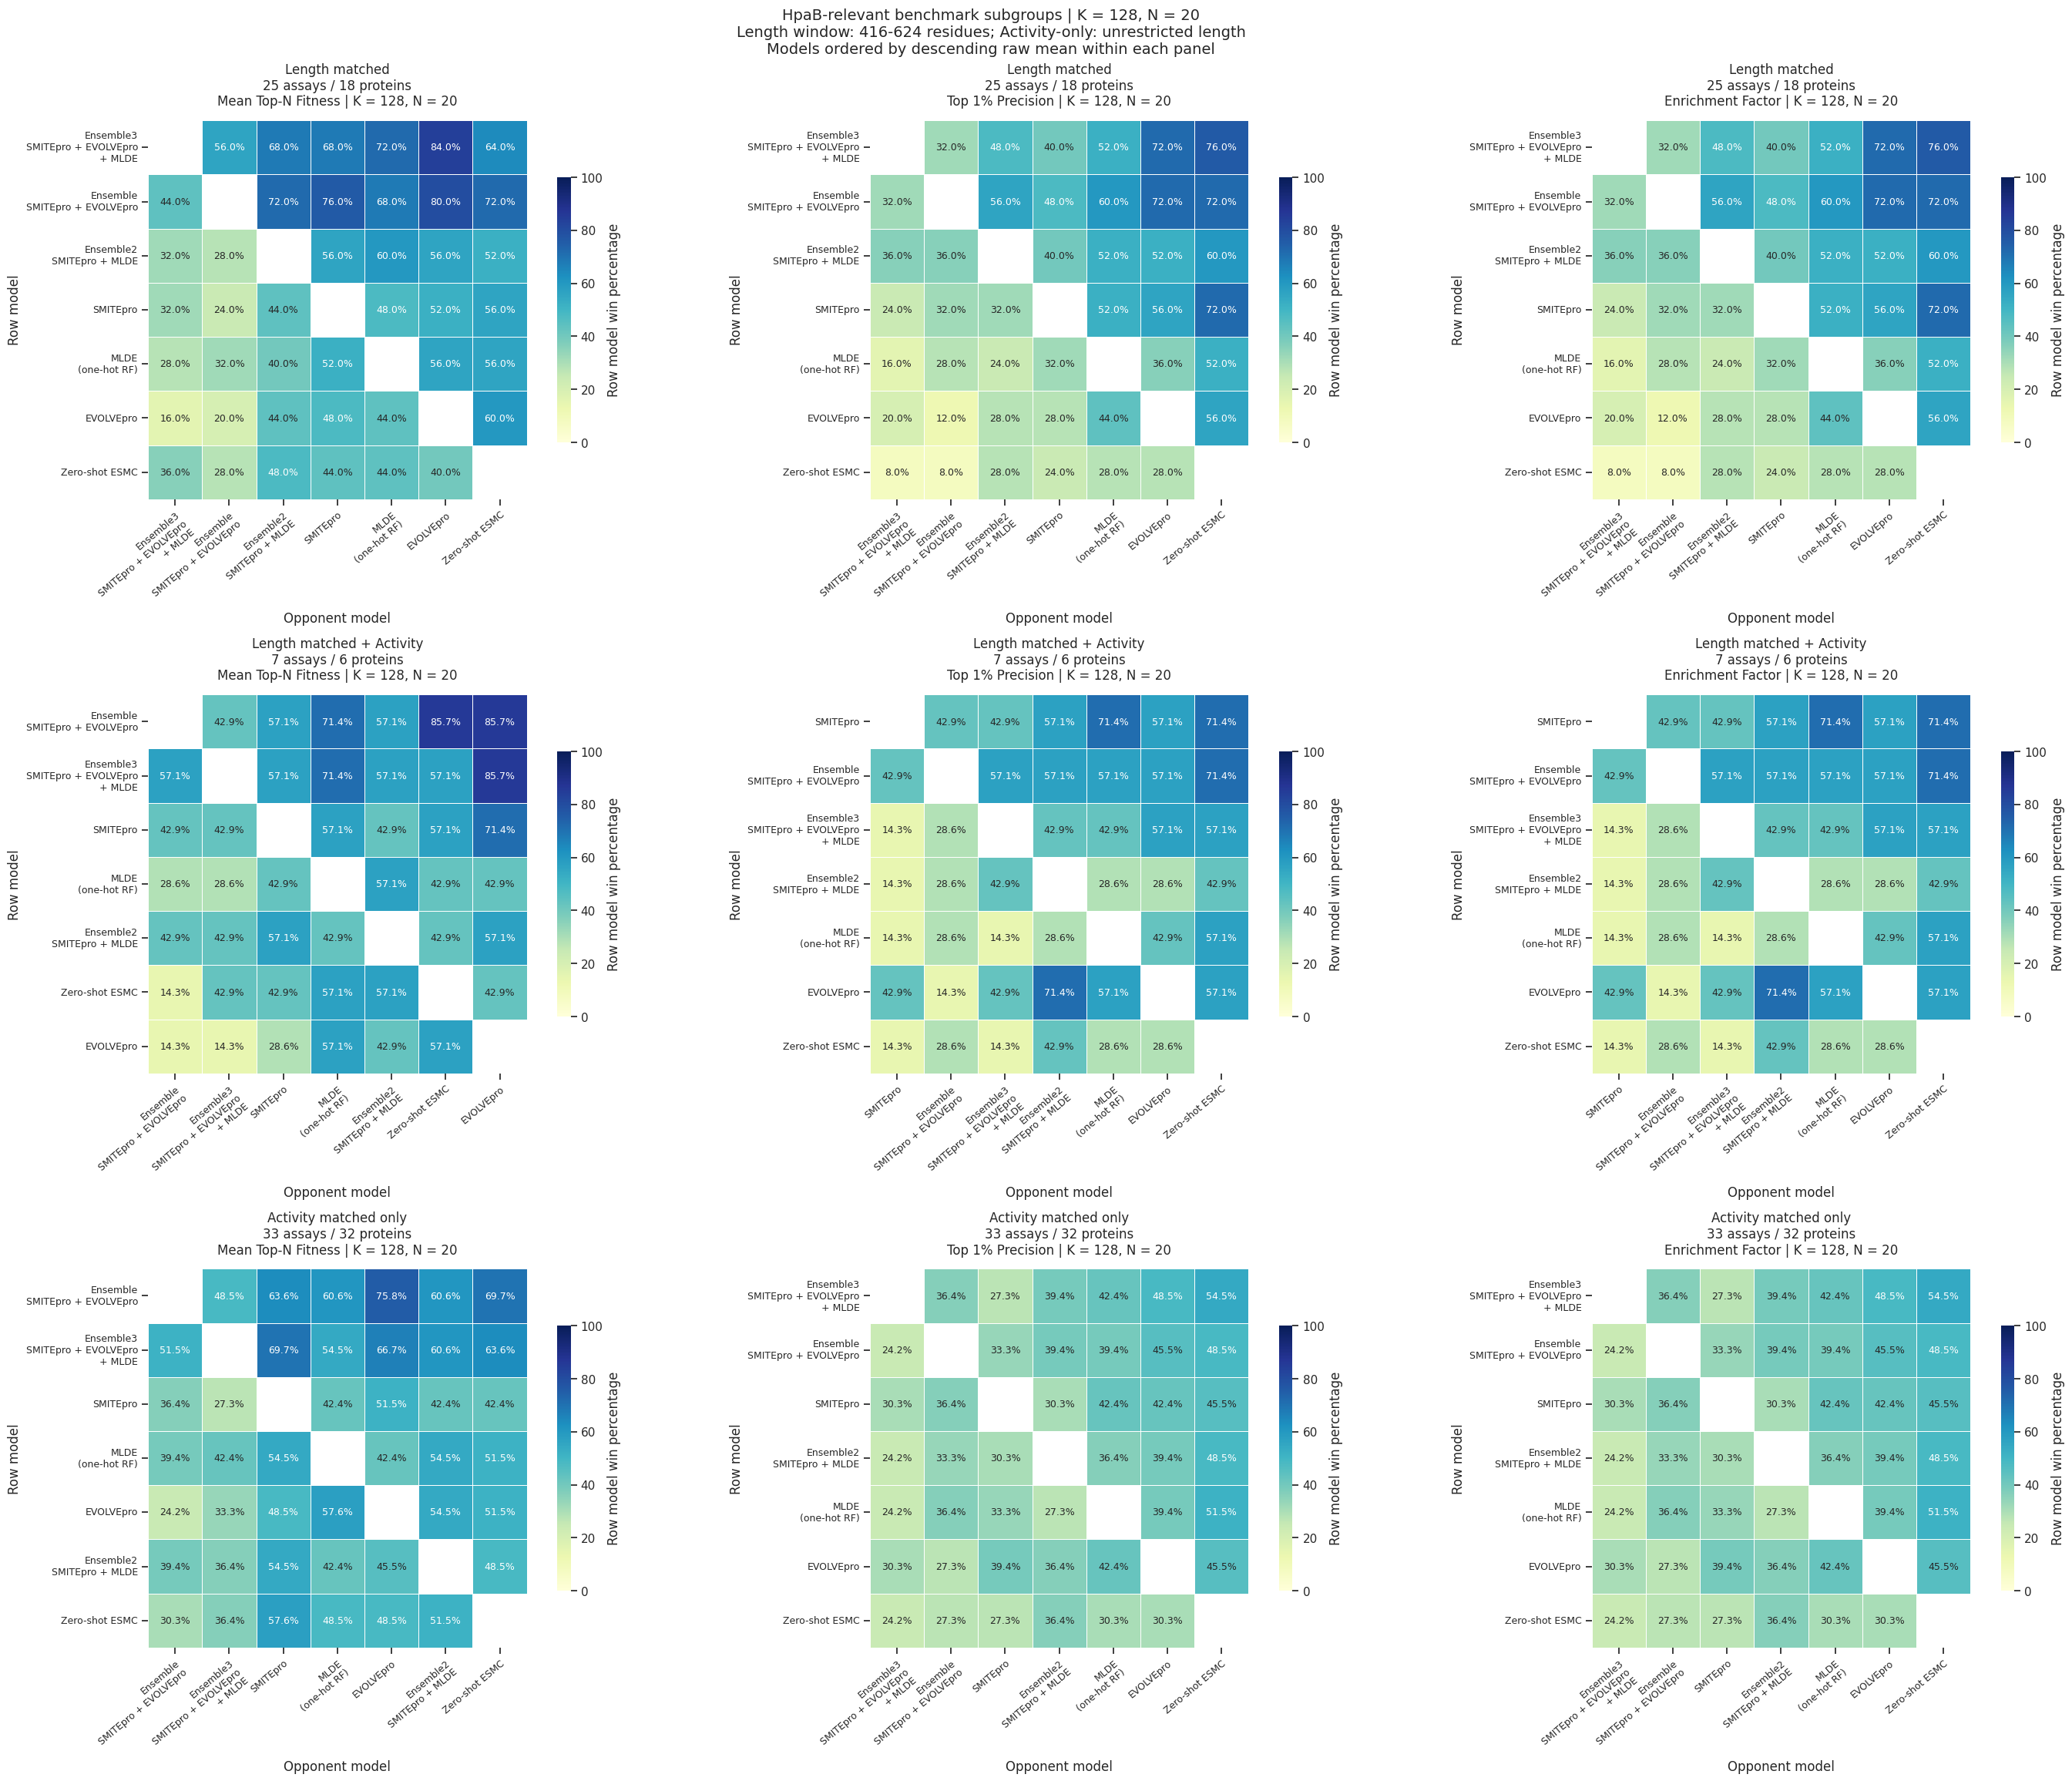

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

hpab_training_size = 128
hpab_budget = 20
hpab_metrics = ['Mean Top-N Fitness', 'Top 1% Precision', 'Enrichment Factor']
hpab_metric_units = {'Mean Top-N Fitness': 'normalized target', 'Top 1% Precision': 'percent', 'Enrichment Factor': 'fold enrichment'}
hpab_methods = ['Ensemble', 'Ensemble2', 'Ensemble3', 'SMITEpro', 'EVOLVEpro', 'MLDE One-Hot RF', 'Zero-Shot ESM']
hpab_ensemble_methods = ['Ensemble', 'Ensemble2', 'Ensemble3']
hpab_model_labels = {
    'Ensemble': 'Ensemble: SMITEpro + EVOLVEpro',
    'Ensemble2': 'Ensemble2: SMITEpro + MLDE (one-hot RF)',
    'Ensemble3': 'Ensemble3: SMITEpro + EVOLVEpro + MLDE (one-hot RF)',
    'SMITEpro': 'SMITEpro', 'EVOLVEpro': 'EVOLVEpro',
    'MLDE One-Hot RF': 'MLDE (one-hot RF)', 'Zero-Shot ESM': 'Zero-shot ESMC',
}
hpab_cohort_assays = {
    **hpab_cohort_assays,
    'Activity matched only': sorted(hpab_assay_metadata.loc[hpab_assay_metadata['activity_primary'], 'assay']),
}
assert hpab_cohort_assays['Activity matched only']
assert set(hpab_cohort_assays['Length matched + Activity']) == (
    set(hpab_cohort_assays['Length matched']) & set(hpab_cohort_assays['Activity matched only'])
)
hpab_restricted_metric_frames = {}
for hpab_metric in hpab_metrics:
    hpab_metric_long = budget_plot_metrics.loc[
        budget_plot_metrics['metric'].eq(hpab_metric)
        & budget_plot_metrics['train_size'].eq(hpab_training_size)
        & budget_plot_metrics['N'].eq(hpab_budget)
        & budget_plot_metrics['assay'].isin(complete_assays)
        & budget_plot_metrics['method'].isin(hpab_methods)
    ]
    assert not hpab_metric_long.duplicated(head_to_head_keys + ['method']).any()
    hpab_frame = hpab_metric_long.pivot(index=head_to_head_keys, columns='method', values='value').reindex(columns=hpab_methods).sort_index()
    assert len(hpab_frame) == len(complete_assays)
    assert set(hpab_frame.index.get_level_values('assay')) == set(complete_assays)
    assert not hpab_frame.index.get_level_values('assay').duplicated().any()
    assert np.isfinite(hpab_frame.to_numpy()).all()
    if hpab_metric in head_to_head_metric_frames:
        hpab_original = head_to_head_metric_frames[hpab_metric].reindex(index=hpab_frame.index, columns=hpab_methods)
        np.testing.assert_allclose(hpab_frame.to_numpy(), hpab_original.to_numpy())
    hpab_restricted_metric_frames[hpab_metric] = hpab_frame
assert all(hpab_frame.index.equals(hpab_restricted_metric_frames[hpab_metrics[0]].index) for hpab_frame in hpab_restricted_metric_frames.values())
hpab_raw_records = []
hpab_win_records = []
hpab_assay_win_records = []
hpab_win_matrices = {}
hpab_bootstrap_replicates = 5000
hpab_protein_lookup = hpab_assay_metadata.set_index('assay')['UniProt_ID']

for hpab_cohort, hpab_assays in hpab_cohort_assays.items():
    for hpab_metric in hpab_metrics:
        hpab_frame = hpab_restricted_metric_frames[hpab_metric]
        hpab_scores = hpab_frame.loc[hpab_frame.index.get_level_values('assay').isin(hpab_assays)].sort_index()
        assert len(hpab_scores) == len(hpab_assays)
        assert set(hpab_scores.index.get_level_values('assay')) == set(hpab_assays)
        assert np.isfinite(hpab_scores.to_numpy()).all()
        hpab_protein_ids = hpab_scores.index.get_level_values('assay').map(hpab_protein_lookup)
        hpab_proteins = sorted(set(hpab_protein_ids))
        hpab_scale = 100.0 if hpab_metric == 'Top 1% Precision' else 1.0
        hpab_wins, hpab_ties = pairwise_win_percentages(hpab_scores.to_numpy())
        hpab_win_matrices[(hpab_cohort, hpab_metric)] = hpab_wins
        hpab_assay_means = hpab_scores.groupby(level='assay').mean()
        hpab_protein_means = hpab_assay_means.groupby(hpab_assay_means.index.map(hpab_protein_lookup)).mean()
        for hpab_method in hpab_methods:
            hpab_raw_records.append({
                'cohort': hpab_cohort, 'metric': hpab_metric, 'method': hpab_method,
                'model': hpab_model_labels[hpab_method], 'assays': len(hpab_assays), 'proteins': len(hpab_proteins),
                'matchups': len(hpab_scores), 'assay_weighted_mean': hpab_scale * hpab_assay_means[hpab_method].mean(),
                'protein_weighted_mean': hpab_scale * hpab_protein_means[hpab_method].mean(),
                'unit': hpab_metric_units[hpab_metric],
            })
        hpab_rng = np.random.default_rng(20261010)
        hpab_cluster_draws = hpab_rng.integers(0, len(hpab_proteins), size=(hpab_bootstrap_replicates, len(hpab_proteins)))
        for hpab_ensemble_method in hpab_ensemble_methods:
            for hpab_opponent in hpab_methods:
                if hpab_opponent == hpab_ensemble_method:
                    continue
                hpab_differences = hpab_scores[hpab_ensemble_method] - hpab_scores[hpab_opponent]
                hpab_outcomes = pd.DataFrame({
                    'win': hpab_differences.gt(tie_tolerance).astype(int),
                    'tie': hpab_differences.abs().le(tie_tolerance).astype(int),
                    'loss': hpab_differences.lt(-tie_tolerance).astype(int),
                    'total': 1,
                }, index=hpab_scores.index)
                assert hpab_outcomes[['win', 'tie', 'loss']].sum(axis=1).eq(1).all()
                hpab_clusters = hpab_outcomes.groupby(hpab_protein_ids).sum().reindex(hpab_proteins)
                hpab_boot_totals = hpab_clusters.to_numpy()[hpab_cluster_draws].sum(axis=1)
                hpab_boot_win_pct = 100 * hpab_boot_totals[:, 0] / hpab_boot_totals[:, 3]
                hpab_ci_low, hpab_ci_high = np.quantile(hpab_boot_win_pct, [0.025, 0.975])
                hpab_totals = hpab_outcomes.sum()
                hpab_win_records.append({
                    'cohort': hpab_cohort, 'metric': hpab_metric, 'method': hpab_ensemble_method,
                    'model': hpab_model_labels[hpab_ensemble_method], 'opponent_method': hpab_opponent,
                    'opponent': hpab_model_labels[hpab_opponent], 'assays': len(hpab_assays), 'proteins': len(hpab_proteins),
                    'matchups': len(hpab_scores), 'wins': int(hpab_totals['win']), 'ties': int(hpab_totals['tie']),
                    'losses': int(hpab_totals['loss']), 'win_pct': 100 * hpab_totals['win'] / len(hpab_scores),
                    'tie_pct': 100 * hpab_totals['tie'] / len(hpab_scores),
                    'loss_pct': 100 * hpab_totals['loss'] / len(hpab_scores),
                    'win_pct_ci_low': hpab_ci_low, 'win_pct_ci_high': hpab_ci_high,
                })
                for hpab_assay, hpab_assay_counts in hpab_outcomes.groupby(level='assay').sum().iterrows():
                    hpab_assay_win_records.append({
                        'cohort': hpab_cohort, 'metric': hpab_metric, 'assay': hpab_assay,
                        'protein': hpab_protein_lookup[hpab_assay], 'method': hpab_ensemble_method,
                        'model': hpab_model_labels[hpab_ensemble_method], 'opponent_method': hpab_opponent,
                        'opponent': hpab_model_labels[hpab_opponent],
                        'wins': int(hpab_assay_counts['win']), 'ties': int(hpab_assay_counts['tie']),
                        'losses': int(hpab_assay_counts['loss']), 'panels': int(hpab_assay_counts['total']),
                    })

hpab_raw_scores = pd.DataFrame(hpab_raw_records)
hpab_ensemble_wins = pd.DataFrame(hpab_win_records)
hpab_assay_wins = pd.DataFrame(hpab_assay_win_records)
for hpab_table in [hpab_raw_scores, hpab_ensemble_wins, hpab_assay_wins]:
    hpab_table['train_size'] = hpab_training_size
    hpab_table['N'] = hpab_budget
assert hpab_raw_scores['matchups'].eq(hpab_raw_scores['assays']).all()
assert hpab_assay_wins['panels'].eq(1).all()
assert np.allclose(hpab_ensemble_wins[['win_pct', 'tie_pct', 'loss_pct']].sum(axis=1), 100)
assert hpab_raw_scores.groupby(['cohort', 'metric'])['method'].nunique().eq(len(hpab_methods)).all()
assert hpab_raw_scores.groupby('cohort')['metric'].nunique().eq(len(hpab_metrics)).all()
assert hpab_ensemble_wins.groupby(['cohort', 'metric', 'method']).size().eq(len(hpab_methods) - 1).all()
hpab_raw_scores = hpab_raw_scores.sort_values(
    ['cohort', 'metric', 'assay_weighted_mean'], ascending=[True, True, False], kind='stable',
).reset_index(drop=True)
hpab_output_prefix = f'hpab_subgroups_K{hpab_training_size}_N{hpab_budget}'
hpab_raw_scores.to_csv(historical_directory / f'{hpab_output_prefix}_raw_scores.csv', index=False)
hpab_ensemble_wins.to_csv(historical_directory / f'{hpab_output_prefix}_ensemble_win_tie_loss.csv', index=False)
hpab_assay_wins.to_csv(historical_directory / f'{hpab_output_prefix}_per_assay_win_tie_loss.csv', index=False)

hpab_heatmap_labels = {
    'Ensemble': 'Ensemble\nSMITEpro + EVOLVEpro',
    'Ensemble2': 'Ensemble2\nSMITEpro + MLDE',
    'Ensemble3': 'Ensemble3\nSMITEpro + EVOLVEpro\n+ MLDE',
    'SMITEpro': 'SMITEpro', 'EVOLVEpro': 'EVOLVEpro',
    'MLDE One-Hot RF': 'MLDE\n(one-hot RF)', 'Zero-Shot ESM': 'Zero-shot ESMC',
}
hpab_plot_cohorts = ['Length matched', 'Length matched + Activity', 'Activity matched only']
hpab_panel_method_orders = {}
hpab_figure, hpab_axes = plt.subplots(len(hpab_plot_cohorts), len(hpab_metrics), figsize=(28, 23), squeeze=False, layout='constrained')
for hpab_row, hpab_cohort in enumerate(hpab_plot_cohorts):
    hpab_assays = hpab_cohort_assays[hpab_cohort]
    hpab_num_proteins = hpab_assay_metadata.loc[hpab_assay_metadata['assay'].isin(hpab_assays), 'UniProt_ID'].nunique()
    for hpab_column, hpab_metric in enumerate(hpab_metrics):
        hpab_axis = hpab_axes[hpab_row, hpab_column]
        hpab_panel_raw = hpab_raw_scores.loc[
            hpab_raw_scores['cohort'].eq(hpab_cohort) & hpab_raw_scores['metric'].eq(hpab_metric)
        ].set_index('method').reindex(hpab_methods)
        hpab_panel_raw = hpab_panel_raw.sort_values('assay_weighted_mean', ascending=False, kind='stable')
        assert hpab_panel_raw['assay_weighted_mean'].is_monotonic_decreasing
        hpab_ordered_methods = list(hpab_panel_raw.index)
        assert set(hpab_ordered_methods) == set(hpab_methods)
        hpab_panel_method_orders[(hpab_cohort, hpab_metric)] = hpab_ordered_methods
        hpab_positions = [hpab_methods.index(hpab_method) for hpab_method in hpab_ordered_methods]
        hpab_matrix = hpab_win_matrices[(hpab_cohort, hpab_metric)][np.ix_(hpab_positions, hpab_positions)]
        assert hpab_matrix.shape == (len(hpab_methods), len(hpab_methods))
        hpab_frame = hpab_restricted_metric_frames[hpab_metric]
        hpab_check_scores = hpab_frame.loc[
            hpab_frame.index.get_level_values('assay').isin(hpab_assays), hpab_ordered_methods,
        ]
        hpab_check_wins, _ = pairwise_win_percentages(hpab_check_scores.to_numpy())
        np.testing.assert_allclose(hpab_matrix, hpab_check_wins)
        hpab_plot_labels = [hpab_heatmap_labels[hpab_method] for hpab_method in hpab_ordered_methods]
        hpab_annotations = np.array([[f'{hpab_value:.1f}%' for hpab_value in hpab_values] for hpab_values in hpab_matrix])
        sns.heatmap(
            pd.DataFrame(hpab_matrix, index=hpab_plot_labels, columns=hpab_plot_labels),
            mask=np.eye(len(hpab_methods), dtype=bool), annot=hpab_annotations, fmt='',
            cmap='YlGnBu', vmin=0, vmax=100, square=True, linewidths=0.5, ax=hpab_axis,
            annot_kws={'fontsize': 9}, cbar_kws={'label': 'Row model win percentage', 'shrink': 0.7},
        )
        hpab_axis.set_title(f'{hpab_cohort}\n{len(hpab_assays)} assays / {hpab_num_proteins} proteins\n{hpab_metric} | K = {hpab_training_size}, N = {hpab_budget}', fontsize=12, pad=14)
        hpab_axis.set_xlabel('Opponent model')
        hpab_axis.set_ylabel('Row model')
        hpab_axis.tick_params(axis='y', rotation=0, labelsize=9)
        hpab_axis.tick_params(axis='x', labelsize=9)
        plt.setp(hpab_axis.get_xticklabels(), rotation=40, ha='right', rotation_mode='anchor')
hpab_figure.suptitle(
    f'HpaB-relevant benchmark subgroups | K = {hpab_training_size}, N = {hpab_budget}\nLength window: {hpab_length_bounds[0]}-{hpab_length_bounds[1]} residues; Activity-only: unrestricted length\nModels ordered by descending raw mean within each panel',
    fontsize=14,
)
assert hpab_axes.shape == (3, 3)
assert len(hpab_panel_method_orders) == 9
plt.show()

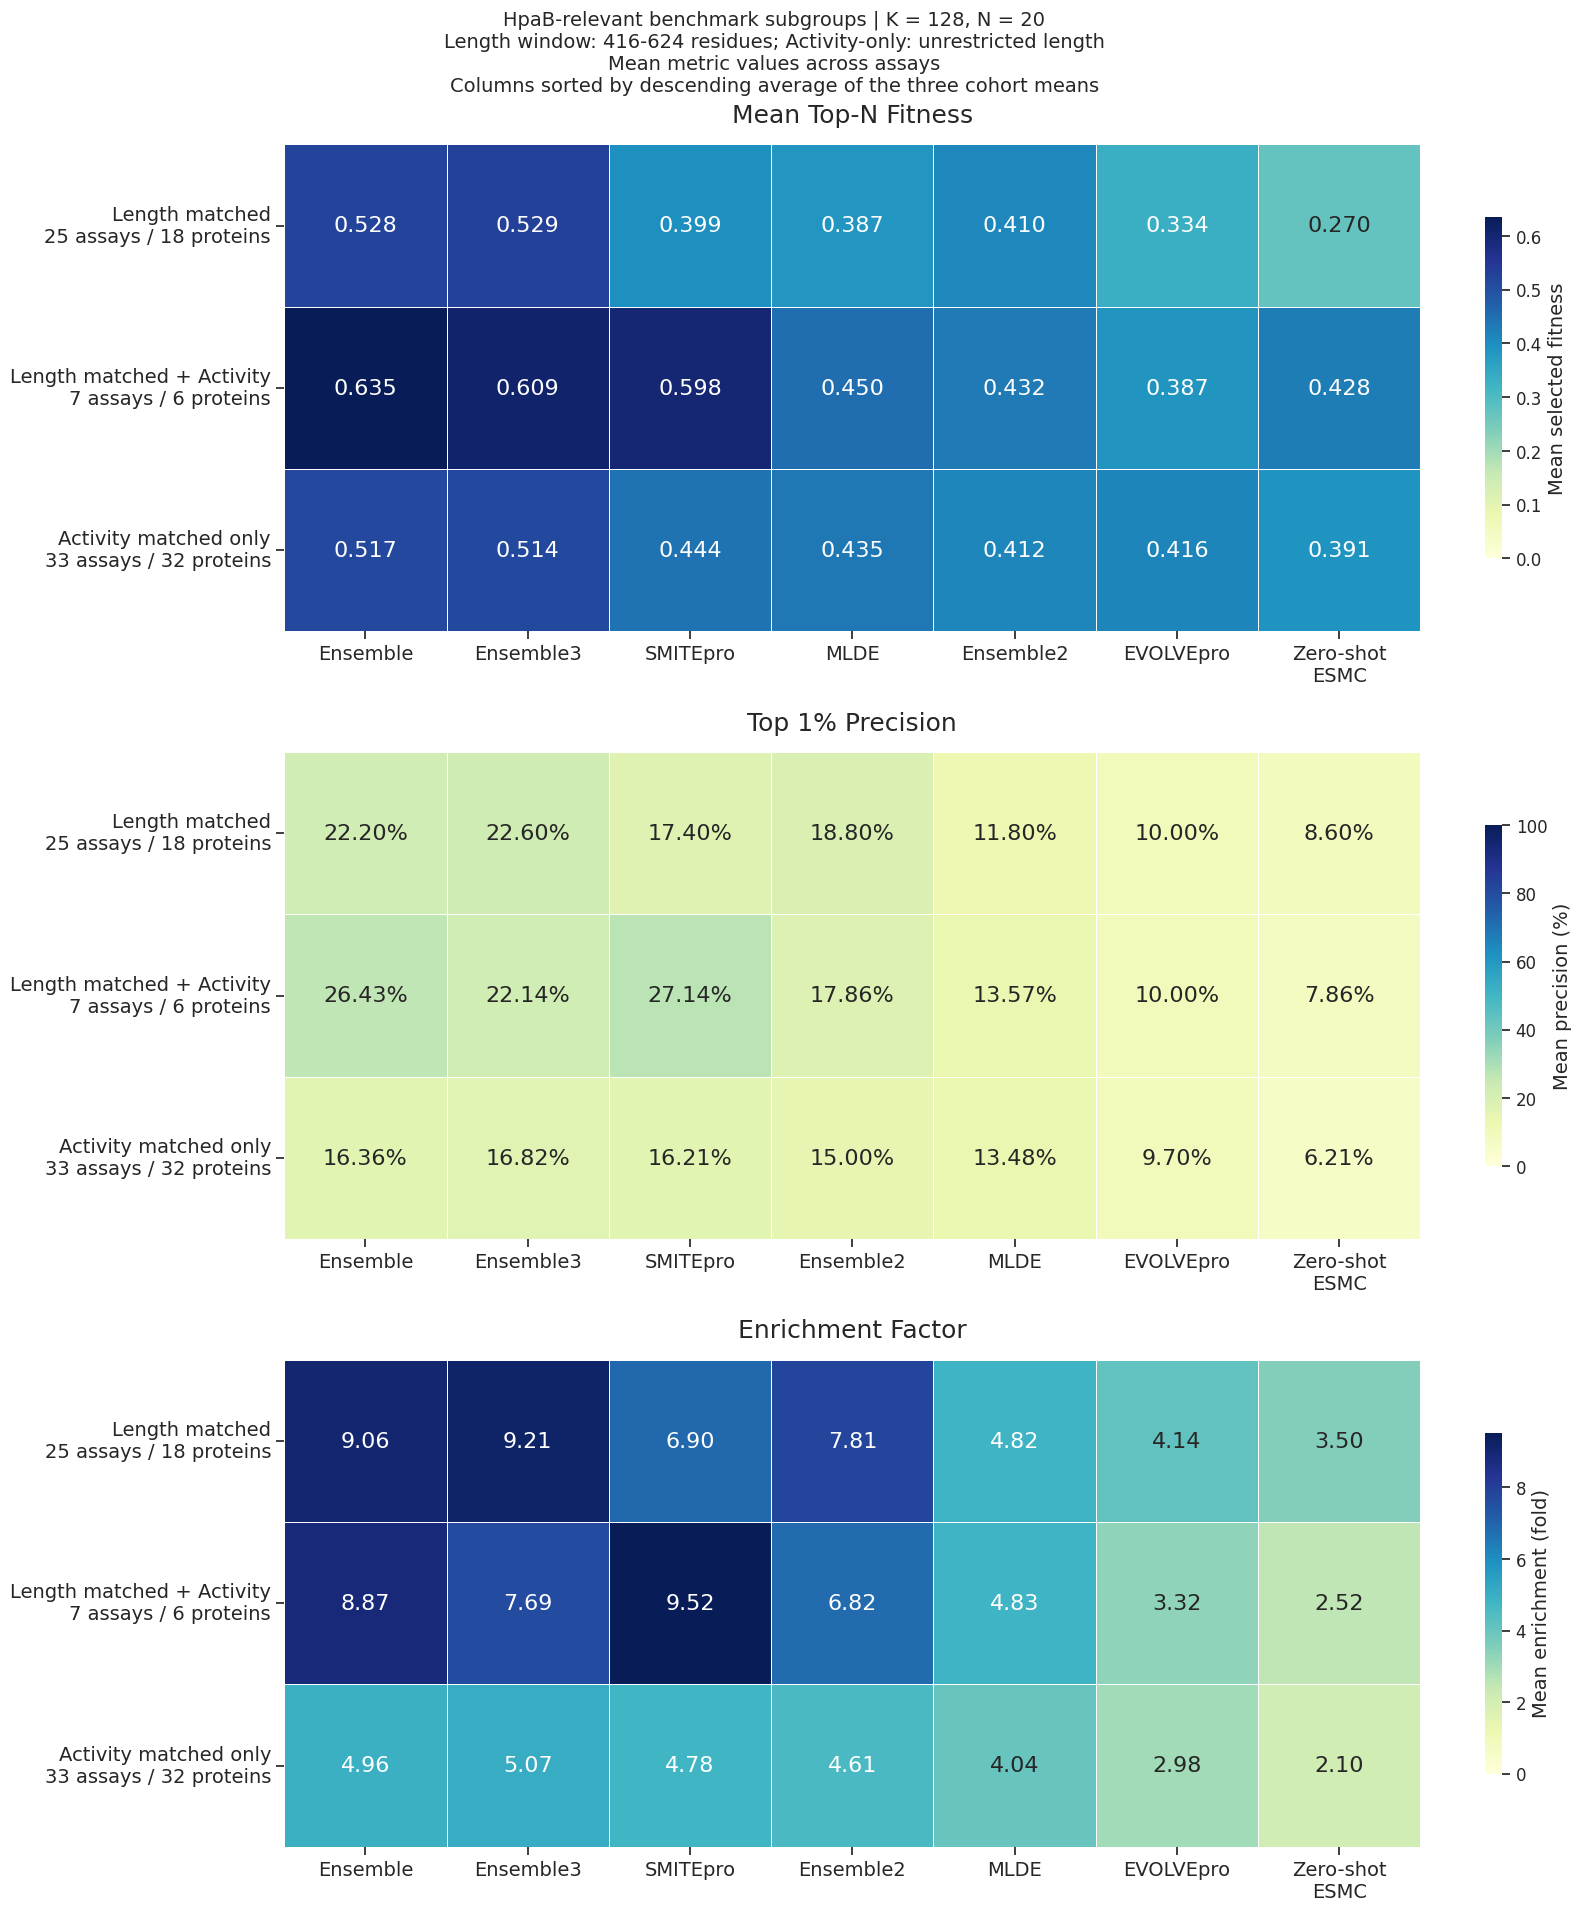

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'hpab_restricted_metric_frames' not in globals() or 'hpab_raw_scores' not in globals():
    raise RuntimeError('Run Cell 29 first to load the restricted subgroup scores.')

hpab_mean_training_size = 128
hpab_mean_budget = 20
hpab_mean_metrics = ['Mean Top-N Fitness', 'Top 1% Precision', 'Enrichment Factor']
hpab_mean_cohorts = ['Length matched', 'Length matched + Activity', 'Activity matched only']
hpab_mean_methods = ['Ensemble', 'Ensemble2', 'Ensemble3', 'SMITEpro', 'EVOLVEpro', 'MLDE One-Hot RF', 'Zero-Shot ESM']
hpab_mean_units = {'Mean Top-N Fitness': 'Mean selected fitness', 'Top 1% Precision': 'Mean precision (%)', 'Enrichment Factor': 'Mean enrichment (fold)'}
hpab_mean_labels = {
    'Ensemble': 'Ensemble',
    'Ensemble2': 'Ensemble2',
    'Ensemble3': 'Ensemble3',
    'SMITEpro': 'SMITEpro', 'EVOLVEpro': 'EVOLVEpro',
    'MLDE One-Hot RF': 'MLDE', 'Zero-Shot ESM': 'Zero-shot\nESMC',
}
hpab_mean_records = []
hpab_mean_matrices = {}
hpab_mean_method_orders = {}
for hpab_mean_metric in hpab_mean_metrics:
    hpab_mean_frame = hpab_restricted_metric_frames[hpab_mean_metric]
    assert (hpab_mean_frame.index.get_level_values('train_size') == hpab_mean_training_size).all()
    assert (hpab_mean_frame.index.get_level_values('N') == hpab_mean_budget).all()
    hpab_mean_scale = 100.0 if hpab_mean_metric == 'Top 1% Precision' else 1.0
    for hpab_mean_cohort in hpab_mean_cohorts:
        hpab_mean_assays = hpab_cohort_assays[hpab_mean_cohort]
        hpab_mean_scores = hpab_mean_frame.loc[
            hpab_mean_frame.index.get_level_values('assay').isin(hpab_mean_assays), hpab_mean_methods,
        ]
        assert len(hpab_mean_scores) == len(hpab_mean_assays)
        assert not hpab_mean_scores.index.get_level_values('assay').duplicated().any()
        assert np.isfinite(hpab_mean_scores.to_numpy()).all()
        hpab_mean_values = hpab_mean_scale * hpab_mean_scores.groupby(level='assay').mean().mean()
        hpab_mean_reference = hpab_raw_scores.loc[
            hpab_raw_scores['cohort'].eq(hpab_mean_cohort) & hpab_raw_scores['metric'].eq(hpab_mean_metric)
        ].set_index('method').reindex(hpab_mean_methods)
        np.testing.assert_allclose(hpab_mean_values.to_numpy(), hpab_mean_reference['assay_weighted_mean'].to_numpy())
        for hpab_mean_method in hpab_mean_methods:
            hpab_mean_records.append({
                'cohort': hpab_mean_cohort, 'metric': hpab_mean_metric, 'method': hpab_mean_method,
                'model': hpab_model_labels[hpab_mean_method], 'assays': len(hpab_mean_assays),
                'proteins': hpab_assay_metadata.loc[hpab_assay_metadata['assay'].isin(hpab_mean_assays), 'UniProt_ID'].nunique(),
                'train_size': hpab_mean_training_size, 'N': hpab_mean_budget,
                'assay_weighted_mean': hpab_mean_values[hpab_mean_method], 'unit': hpab_metric_units[hpab_mean_metric],
            })
hpab_mean_raw_scores = pd.DataFrame(hpab_mean_records)
assert len(hpab_mean_raw_scores) == len(hpab_mean_cohorts) * len(hpab_mean_metrics) * len(hpab_mean_methods)
hpab_mean_raw_scores.to_csv(
    historical_directory / f'hpab_subgroups_K{hpab_mean_training_size}_N{hpab_mean_budget}_mean_heatmap_values.csv', index=False,
)

hpab_mean_row_labels = [
    f'{hpab_mean_cohort}\n{len(hpab_cohort_assays[hpab_mean_cohort])} assays / '
    f'{hpab_assay_metadata.loc[hpab_assay_metadata["assay"].isin(hpab_cohort_assays[hpab_mean_cohort]), "UniProt_ID"].nunique()} proteins'
    for hpab_mean_cohort in hpab_mean_cohorts
]
hpab_mean_figure, hpab_mean_axes = plt.subplots(3, 1, figsize=(16, 19), squeeze=False, layout='constrained')
hpab_mean_figure.get_layout_engine().set(hspace=0.04)
for hpab_mean_row_index, hpab_mean_metric in enumerate(hpab_mean_metrics):
    hpab_mean_axis = hpab_mean_axes[hpab_mean_row_index, 0]
    hpab_mean_matrix = hpab_mean_raw_scores.loc[hpab_mean_raw_scores['metric'].eq(hpab_mean_metric)].pivot(
        index='cohort', columns='method', values='assay_weighted_mean',
    ).reindex(index=hpab_mean_cohorts, columns=hpab_mean_methods)
    assert hpab_mean_matrix.shape == (3, 7)
    assert np.isfinite(hpab_mean_matrix.to_numpy()).all()
    hpab_mean_sort_scores = hpab_mean_matrix.mean(axis=0).sort_values(ascending=False, kind='stable')
    hpab_mean_ordered_methods = list(hpab_mean_sort_scores.index)
    assert hpab_mean_sort_scores.is_monotonic_decreasing
    hpab_mean_method_orders[hpab_mean_metric] = hpab_mean_ordered_methods
    hpab_mean_matrix = hpab_mean_matrix.reindex(columns=hpab_mean_ordered_methods)
    np.testing.assert_allclose(
        hpab_mean_matrix.reindex(columns=hpab_mean_methods).to_numpy(),
        hpab_mean_raw_scores.loc[hpab_mean_raw_scores['metric'].eq(hpab_mean_metric)].pivot(
            index='cohort', columns='method', values='assay_weighted_mean',
        ).reindex(index=hpab_mean_cohorts, columns=hpab_mean_methods).to_numpy(),
    )
    hpab_mean_matrices[hpab_mean_metric] = hpab_mean_matrix.copy()
    hpab_mean_format = '.3f' if hpab_mean_metric == 'Mean Top-N Fitness' else '.2f'
    hpab_mean_annotations = np.array([
        [f'{hpab_mean_value:{hpab_mean_format}}' + ('%' if hpab_mean_metric == 'Top 1% Precision' else '') for hpab_mean_value in hpab_mean_row]
        for hpab_mean_row in hpab_mean_matrix.to_numpy()
    ])
    sns.heatmap(
        hpab_mean_matrix, annot=hpab_mean_annotations, fmt='', cmap='YlGnBu',
        vmin=0 if hpab_mean_metric != 'Mean Top-N Fitness' else min(0.0, hpab_mean_matrix.to_numpy().min()),
        vmax=100 if hpab_mean_metric == 'Top 1% Precision' else None,
        square=True, linewidths=0.5, ax=hpab_mean_axis, annot_kws={'fontsize': 16},
        xticklabels=[hpab_mean_labels[hpab_mean_method] for hpab_mean_method in hpab_mean_ordered_methods],
        yticklabels=hpab_mean_row_labels,
        cbar_kws={'label': hpab_mean_units[hpab_mean_metric], 'shrink': 0.7},
    )
    hpab_mean_axis.set_title(hpab_mean_metric, fontsize=18, pad=16)
    hpab_mean_axis.set_xlabel('')
    hpab_mean_axis.set_ylabel('')
    hpab_mean_axis.tick_params(axis='y', rotation=0, labelsize=14)
    hpab_mean_axis.tick_params(axis='x', rotation=0, labelsize=14)
    plt.setp(hpab_mean_axis.get_xticklabels(), rotation=0, ha='center')
    hpab_mean_colorbar = hpab_mean_axis.collections[0].colorbar
    hpab_mean_colorbar.ax.tick_params(labelsize=12)
    hpab_mean_colorbar.set_label(hpab_mean_units[hpab_mean_metric], fontsize=14)
hpab_mean_figure.suptitle(
    f'HpaB-relevant benchmark subgroups | K = {hpab_mean_training_size}, N = {hpab_mean_budget}\n'
    f'Length window: {hpab_length_bounds[0]}-{hpab_length_bounds[1]} residues; Activity-only: unrestricted length\n'
    'Mean metric values across assays\n'
    'Columns sorted by descending average of the three cohort means', fontsize=14,
)
assert hpab_mean_axes.shape == (3, 1)
assert len(hpab_mean_matrices) == 3
assert len(hpab_mean_method_orders) == 3
hpab_mean_export_directory = workspace_root / 'manuscript/figures'
hpab_mean_export_directory.mkdir(parents=True, exist_ok=True)
for hpab_mean_export_extension in ('png', 'pdf'):
    hpab_mean_figure.savefig(
        hpab_mean_export_directory / f'hpab_subgroup_mean_heatmaps.{hpab_mean_export_extension}',
        dpi=300, bbox_inches='tight',
    )
plt.show()

In [ ]:
from pathlib import Path
import importlib.util
import matplotlib
from IPython.display import display

sa_relative_path = Path('internal_data/Dan_data/experimental_results/plot_experimental_results.py')
sa_root = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / sa_relative_path).is_file()),
    None,
)
if sa_root is None:
    raise FileNotFoundError('Cannot find the Prism experimental plotting script.')
sa_spec = importlib.util.spec_from_file_location('hpab_experimental_plots', sa_root / sa_relative_path)
sa_plotting = importlib.util.module_from_spec(sa_spec)
sa_backend = matplotlib.get_backend()
try:
    sa_spec.loader.exec_module(sa_plotting)
finally:
    matplotlib.use(sa_backend)
sa_directory = (sa_root / sa_relative_path).parent
sa_summary, sa_factors, sa_sources = sa_plotting.prepare_prism(sa_directory)
sa_figure = sa_plotting.draw_stability(sa_summary, sa_directory, sa_root / 'manuscript/figures')
display(sa_figure)
sa_plotting.plt.close(sa_figure)

                  background  candidates  spearman_rho  above_background  below_background  nonpositive_means  destabilizing_above_background  destabilizing_below_background
                          WT          20     -0.026326                 2                18                  0                               1                              14
                       A199P          20      0.648120                 7                13                  4                               2                               9
                  I29V_A199P          19      0.556140                 8                11                  1                               1                               7
            I29V_A199P_D354K          20      0.346386                 4                16                  4                               0                               5
      I29V_A199P_D354K_G122A          20      0.494737                 4                16                  3                     

<Figure size 1450x1000 with 6 Axes>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import MaxNLocator

if 'budget_plot_metrics' not in globals():
    raise RuntimeError('Run Cell 25 first to load the matched comparison methods.')

bubble_metrics = ['Mean Top-N Fitness', 'Top 1% Precision', 'Enrichment Factor']
bubble_training_sizes = sorted(comparison_shots)
bubble_budgets = sorted(comparison_budgets)
bubble_labels = {
    **method_labels,
    'Ensemble': 'SMITEpro + EVOLVEpro',
    'Ensemble3': 'SMITEpro + EVOLVEpro + MLDE',
    'Ensemble2': 'SMITEpro + MLDE',
}
bubble_methods = [
    method for method in budget_display_methods
    if 'mlde' not in f'{method} {bubble_labels.get(method, method)}'.lower()
]
for bubble_method in bubble_methods:
    if 'kermut' in f'{bubble_method} {bubble_labels.get(bubble_method, bubble_method)}'.lower():
        bubble_labels[bubble_method] = 'Gaussian Process'
bubble_settings = pd.MultiIndex.from_product(
    [bubble_training_sizes, bubble_budgets], names=['train_size', 'N'],
)
bubble_keys = ['assay', 'method', 'metric', 'train_size', 'N']
bubble_source = budget_plot_metrics.loc[
    budget_plot_metrics['metric'].isin(bubble_metrics)
    & budget_plot_metrics['train_size'].isin(bubble_training_sizes)
    & budget_plot_metrics['N'].isin(bubble_budgets)
    & budget_plot_metrics['method'].isin(bubble_methods)
].copy()
assert len(bubble_methods) == 7 and len(bubble_settings) == 16
assert not bubble_source.duplicated(bubble_keys).any()
assert np.isfinite(bubble_source['value'].to_numpy()).all()
bubble_expected_per_assay = len(bubble_methods) * len(bubble_metrics) * len(bubble_settings)
bubble_coverage = bubble_source.groupby('assay').size()
bubble_complete_assays = bubble_coverage.index[bubble_coverage.eq(bubble_expected_per_assay)]
assert len(bubble_complete_assays) == 106
bubble_source = bubble_source.loc[bubble_source['assay'].isin(bubble_complete_assays)].copy()
assert bubble_source.groupby(['method', 'metric', 'train_size', 'N'])['assay'].nunique().eq(106).all()
bubble_means = bubble_source.groupby(['metric', 'method', 'train_size', 'N'], as_index=False)['value'].mean()
bubble_setting_ranks = bubble_means.assign(
    rank=bubble_means.groupby(['metric', 'train_size', 'N'])['value'].rank(ascending=False, method='average'),
)
bubble_mean_ranks = bubble_setting_ranks.groupby('method')['rank'].mean().reindex(bubble_methods).sort_values(kind='stable')
bubble_methods = list(bubble_mean_ranks.index)
assert bubble_mean_ranks.is_monotonic_increasing
assert bubble_setting_ranks.groupby('method').size().eq(48).all()
bubble_styles = {
    'Mean Top-N Fitness': ('A', 'Mean selected fitness', 'Normalized target', 1.0, '#097969', '.2f'),
    'Top 1% Precision': ('B', 'Top 1% precision', 'Selected variants in the held-out top 1% (%)', 100.0, '#2465aa', '.1f'),
    'Enrichment Factor': ('C', 'Top 1% enrichment', 'Fold enrichment over the held-out pool', 1.0, '#ba571f', '.1f'),
}
bubble_x_positions = np.array([
    training_index * (len(bubble_budgets) + 1) + budget_index
    for training_index in range(len(bubble_training_sizes))
    for budget_index in range(len(bubble_budgets))
])
bubble_x_grid, bubble_y_grid = np.meshgrid(bubble_x_positions, np.arange(len(bubble_methods)))
bubble_max_area = 230.0
bubble_matrices = {}
bubble_scatter_artists = {}
bubble_figure = plt.figure(figsize=(18, 14), facecolor='white')
bubble_grid = bubble_figure.add_gridspec(
    3, 2, width_ratios=[16, 2.8], left=0.225, right=0.98,
    top=0.94, bottom=0.07, hspace=0.48, wspace=0.12,
)
bubble_axes = []
for bubble_panel_index, bubble_metric in enumerate(bubble_metrics):
    bubble_letter, bubble_title, bubble_unit, bubble_scale, bubble_color, bubble_format = bubble_styles[bubble_metric]
    bubble_matrix = bubble_means.loc[bubble_means['metric'].eq(bubble_metric)].pivot(
        index='method', columns=['train_size', 'N'], values='value',
    ).reindex(index=bubble_methods, columns=bubble_settings) * bubble_scale
    assert bubble_matrix.shape == (7, 16)
    assert np.isfinite(bubble_matrix.to_numpy()).all()
    bubble_matrices[bubble_metric] = bubble_matrix.copy()
    bubble_values = bubble_matrix.to_numpy()
    bubble_nonnegative = (bubble_values >= 0).all()
    bubble_lower = 0.0 if bubble_nonnegative else float(bubble_values.min())
    bubble_upper = float(bubble_values.max())
    assert bubble_upper > bubble_lower
    bubble_norm = Normalize(vmin=bubble_lower, vmax=bubble_upper)
    bubble_cmap = LinearSegmentedColormap.from_list(
        f'bubble_metric_{bubble_panel_index}', ['#e2e9eb', bubble_color],
    )
    bubble_areas = bubble_max_area * bubble_values / bubble_upper if bubble_nonnegative else np.full_like(bubble_values, 100.0)
    bubble_axis = bubble_figure.add_subplot(bubble_grid[bubble_panel_index, 0])
    bubble_axes.append(bubble_axis)
    for bubble_row_index, bubble_method in enumerate(bubble_methods):
        if bubble_method == 'Ensemble':
            bubble_axis.axhspan(bubble_row_index - 0.48, bubble_row_index + 0.48, color='#f3f5f5', zorder=0)
        bubble_axis.axhline(bubble_row_index, color='#e3e7e8', linewidth=0.55, zorder=1)
    for bubble_training_index, bubble_training_size in enumerate(bubble_training_sizes):
        bubble_group_start = bubble_training_index * (len(bubble_budgets) + 1)
        bubble_axis.text(
            bubble_group_start + 1.5, -0.96, f'K = {bubble_training_size}',
            ha='center', va='center', fontsize=11, fontweight='bold', color='#30383c',
        )
        if bubble_training_index:
            bubble_axis.axvline(bubble_group_start - 1, color='#b9c2c5', linewidth=1.0, zorder=1)
    bubble_scatter = bubble_axis.scatter(
        bubble_x_grid.ravel(), bubble_y_grid.ravel(), s=bubble_areas.ravel(),
        c=bubble_values.ravel(), cmap=bubble_cmap, norm=bubble_norm,
        edgecolors='none', zorder=3,
    )
    bubble_scatter_artists[bubble_metric] = bubble_scatter
    bubble_best = np.isclose(bubble_values, bubble_values.max(axis=0, keepdims=True), rtol=0, atol=1e-10)
    bubble_axis.scatter(
        bubble_x_grid[bubble_best], bubble_y_grid[bubble_best],
        s=bubble_areas[bubble_best] + 45, facecolors='none', edgecolors='#343d42', linewidths=0.9, zorder=4,
    )
    bubble_axis.set_xlim(-0.65, bubble_x_positions.max() + 0.65)
    bubble_axis.set_ylim(len(bubble_methods) - 0.4, -1.4)
    bubble_axis.set_yticks(np.arange(len(bubble_methods)), [bubble_labels.get(method, method) for method in bubble_methods])
    bubble_axis.set_xticks(bubble_x_positions, bubble_budgets * len(bubble_training_sizes))
    bubble_axis.tick_params(axis='both', length=0, labelsize=10, pad=8)
    bubble_axis.set_xlabel('Selected variants, N', fontsize=10, labelpad=8)
    bubble_axis.set_title(f'{bubble_letter}   {bubble_title}', loc='left', fontsize=15, fontweight='bold', pad=21)
    for bubble_spine in bubble_axis.spines.values():
        bubble_spine.set_visible(False)
    for bubble_method, bubble_tick in zip(bubble_methods, bubble_axis.get_yticklabels()):
        if bubble_method == 'Ensemble':
            bubble_tick.set_fontweight('bold')
    bubble_legend_axis = bubble_figure.add_subplot(bubble_grid[bubble_panel_index, 1])
    bubble_legend_axis.set_axis_off()
    bubble_legend_axis.text(0, 0.99, bubble_unit, transform=bubble_legend_axis.transAxes, va='top', fontsize=10, wrap=True)
    bubble_colorbar_axis = bubble_legend_axis.inset_axes([0, 0.77, 0.96, 0.045])
    bubble_colorbar = bubble_figure.colorbar(bubble_scatter, cax=bubble_colorbar_axis, orientation='horizontal')
    bubble_colorbar.locator = MaxNLocator(nbins=3)
    bubble_colorbar.update_ticks()
    bubble_colorbar.ax.tick_params(labelsize=9, length=2)
    bubble_colorbar.outline.set_visible(False)
    bubble_legend_axis.text(
        0, 0.60, 'Circle area = mean value' if bubble_nonnegative else 'Fixed area; color = mean value',
        transform=bubble_legend_axis.transAxes, fontsize=10,
    )
    for bubble_example_index, bubble_fraction in enumerate((0.25, 0.5, 1.0)):
        bubble_example_value = bubble_upper * bubble_fraction if bubble_nonnegative else bubble_lower + (bubble_upper - bubble_lower) * bubble_fraction
        bubble_example_area = bubble_max_area * bubble_fraction if bubble_nonnegative else 100.0
        bubble_example_y = 0.49 - bubble_example_index * 0.12
        bubble_legend_axis.scatter(
            [0.14], [bubble_example_y], s=bubble_example_area,
            color=bubble_cmap(bubble_norm(bubble_example_value)), edgecolors='none',
            transform=bubble_legend_axis.transAxes,
        )
        bubble_example_label = f'{bubble_example_value:{bubble_format}}' + ('%' if bubble_metric == 'Top 1% Precision' else '')
        bubble_legend_axis.text(0.34, bubble_example_y, bubble_example_label, va='center', fontsize=10, transform=bubble_legend_axis.transAxes)
    bubble_legend_axis.scatter([0.14], [0.07], s=160, facecolors='none', edgecolors='#343d42', linewidths=0.9, transform=bubble_legend_axis.transAxes)
    bubble_legend_axis.text(0.34, 0.07, 'Highest mean\nwithin setting', va='center', fontsize=9, transform=bubble_legend_axis.transAxes)

assert len(bubble_axes) == 3
assert all(list(matrix.index) == bubble_methods for matrix in bubble_matrices.values())
assert all(len(artist.get_offsets()) == len(bubble_methods) * len(bubble_settings) for artist in bubble_scatter_artists.values())
assert not bubble_figure.texts
bubble_export_directory = workspace_root / 'manuscript/figures'
bubble_export_directory.mkdir(parents=True, exist_ok=True)
for bubble_export_extension in ('png', 'pdf'):
    bubble_figure.savefig(
        bubble_export_directory / f'benchmark_bubble_matrix.{bubble_export_extension}', dpi=200, bbox_inches='tight',
    )
bubble_means.to_csv(historical_directory / 'benchmark_bubble_matrix_means.csv', index=False)
plt.show()

RuntimeError: Run Cell 25 first to load the matched comparison methods.